# Do the applicant's earlier applications improve the model?

This notebook adds the 41 features from `05_previous_application_eda_features.ipynb` to the model built in `04_model_with_bureau.ipynb`, and measures whether the model gets better.

It follows the method of notebook 04 step for step. One thing changes, the features available, and everything else is held as fixed as possible, so that a difference in score can be put down to the new table.

## Where things stand

| Model | Features | Cross-validation | Holdout | Kaggle private |
|---|---:|---:|---:|---:|
| Application only (notebook 02) | 36 | 0.7685 | 0.7715 | 0.7638 |
| With the credit bureau (notebook 04) | 60 | 0.7779 | not opened | 0.7753 |

The model to beat is the second one: 36 application features and 24 bureau features, 3,500 trees, Platt scaling.

Notebook 05 ended with an expectation: a gain is likely, because 26 of the 41 new features add something beyond a model that already has the bureau features, and the features on how Home Credit priced earlier loans lose almost nothing against it. It declined to put a size on the gain, since the same kind of check under-predicted the bureau gain by a wide margin.

## Inputs

| File | Contents |
|---|---|
| `data/processed/application_*_features.parquet` | 55 application features (and `TARGET` in train) |
| `data/processed/bureau_*_features.parquet` | 40 bureau features |
| `data/processed/previous_*_features.parquet` | 41 features from earlier applications to Home Credit |
| `data/processed/application_split.parquet` | The frozen split: 246,008 development applicants in five folds, 61,503 holdout applicants |
| `artifacts/model_with_bureau/metadata.json` | The 60 features, the settings and the calibration of the current model |

## What counts as an improvement, fixed before any model is fitted

The four conditions of notebook 04, unchanged. On the same five development folds, against the current model:

1. The mean ROC AUC is higher.
2. It is higher in at least four of the five folds.
3. The mean gain is more than twice its standard error across the folds.
4. The mean gain exceeds the noise that a change of random seed produces. Notebook 04 measured that at 0.0005. Stage 2 here measures it again for the current model and uses the larger of the two.

If the conditions are not met, the conclusion is that this table does not help, and the model stays as it is.

## What this notebook does

| # | Stage | Question it answers |
|---|---|---|
| 1 | Setup, join and audit | Do the three feature tables join exactly, and is the split unchanged? |
| 2 | Baseline | Does the current 60-feature model still score 0.7779, fold by fold, when rebuilt here? |
| 3 | Add the new features | With every setting unchanged, what is the gain, and does it meet the conditions? |
| 4 | Where the gain comes from | Which families carry it, and who is it for? What does the one feature with a shift warning contribute? |
| 5 | Pruning | Can the list be shortened at no cost, selecting inside the folds and judging rare events separately? |
| 6 | Settings | Does the number of trees, or the share of features offered to each tree, want to change? |
| 7 | Calibration and threshold | Are the probabilities still right, and what does the gain mean at the reference operating point? |
| 8 | Explainability | Does the lender's own history take over from the external scores as a reason for decline? |
| 9 | Outputs | Refit on all of train, save the model, and write the Kaggle submissions, with expectations fixed beforehand |
| 10 | Conclusions | What this table was worth, its limits, and what comes next |

## Rules followed throughout

- **The same folds** for every comparison, fold against fold.
- **The holdout stays closed.** It was opened once, for the application-only model. It will be opened once more, when the last history table is in.
- **Kaggle scores are reported, never used to choose.**
- **Everything that learns from the outcome sits inside the pipeline:** feature selection, early stopping, calibration.
- **The new features need no fitting.** Notebook 05 showed that each applicant's features depend on that applicant's rows alone.
- **Lessons carried in from notebook 04.** A control with the new columns scrambled between applicants, because more columns alone change what each tree is offered. Rare-event features judged separately from any ranking by average contribution. And like-for-like comparisons whenever the number of trees changes.

## Warnings carried in from notebook 05

- `PREV_RUNNING_MAX_DAYS_REMAINING` differs between train and test (shift AUC 0.561) and is the feature that adds most beyond the current model. Stage 4 reports the model with and without it.
- Two features differ between the files in fine detail: time since the first decision, and the cost of credit of the most recent loan.
- This table as a whole differs more between train and test than the bureau did (0.74 against 0.69 on the joint test). The Kaggle result is the check.

## Out of scope

- The three child tables (`installments_payments`, `POS_CASH_balance`, `credit_card_balance`).
- Changing the model family.
- Opening the holdout.

## Stage 1: Setup, join and audit

| Section | Check |
|---|---|
| 1.1 | The shared pipeline code is still the code of notebook 02 |
| 1.2 | The recipe of the current model, read from the file notebook 04 saved |
| 1.3 | Load and join the three feature tables for the development set |
| 1.4 | The split and the folds |
| 1.5 | Leakage audit of the joined table |

No model is fitted in this stage.

In [1]:
import ast, hashlib, inspect, json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nbformat
import joblib
import lightgbm, sklearn, scipy
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

PROCESSED, RAW = '../data/processed', '../data/raw'
CACHE_DIR = Path('../artifacts/cv_cache_06')
sys.path.insert(0, '../src/models')
import pipeline as shared
from pipeline import SEED, N_SPLITS, CategoryEncoder, KeepColumns, CalibratedModel, lgbm_model, make_pipeline, cross_validate, compare, score_predictions, logit

# 1.1 the six pieces copied from notebook 02 are still identical to their source there
notebook_02 = nbformat.read('02_model_selection_training.ipynb', 4)
original = {}
for cell in notebook_02.cells:
    if cell.cell_type != 'code':
        continue
    try:
        tree = ast.parse(cell.source)
    except SyntaxError:
        continue
    for node in tree.body:
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            original.setdefault(node.name, []).append(ast.get_source_segment(cell.source, node))
COPIED = ['CategoryEncoder', 'KeepColumns', 'CalibratedModel', 'logit', 'score_predictions', 'describe']
fidelity = {name: len(original.get(name, [])) == 1 and original[name][0].strip() == inspect.getsource(getattr(shared, name)).strip() for name in COPIED}
print('identical to notebook 02:', fidelity)
assert all(fidelity.values())
MODULE_CHECKSUM = hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest()
print(f"module checksum {MODULE_CHECKSUM[:12]} (the module has not changed since notebook 04 if this is 1379a001d7bb: {MODULE_CHECKSUM.startswith('1379a001d7bb')})")
print(f"results are cached in {CACHE_DIR.as_posix().replace('../', '')}")

identical to notebook 02: {'CategoryEncoder': True, 'KeepColumns': True, 'CalibratedModel': True, 'logit': True, 'score_predictions': True, 'describe': True}
module checksum 1379a001d7bb (the module has not changed since notebook 04 if this is 1379a001d7bb: True)
results are cached in artifacts/cv_cache_06


### 1.2 The recipe of the current model

In [2]:
recipe = json.loads(Path('../artifacts/model_with_bureau/metadata.json').read_text(encoding='utf-8'))
CURRENT = list(recipe['features'])                                    # the 60 features of the current model
APP_IN_MODEL, BUREAU_IN_MODEL = list(recipe['feature_sources']['application']), list(recipe['feature_sources']['credit bureau'])
BEST_PARAMS = dict(recipe['training']['lightgbm_settings'])
N_TREES, LEARNING_RATE = int(recipe['training']['trees']), float(recipe['training']['learning_rate'])
REFERENCE_CV = recipe['evidence']['cross_validation']
THRESHOLD = float(recipe['decision']['reference_threshold'])

def FINAL():
    # the current model's LightGBM, unfitted
    return lgbm_model(BEST_PARAMS, N_TREES, LEARNING_RATE)

print(f"current model: {len(CURRENT)} features ({len(APP_IN_MODEL)} application, {len(BUREAU_IN_MODEL)} bureau), {N_TREES:,} trees, learning rate {LEARNING_RATE}, seed {recipe['training']['seed']}")
print('settings:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in BEST_PARAMS.items()})
print(f"its cross-validated scores in notebook 04: ROC AUC {REFERENCE_CV['roc_auc']:.5f}, PR AUC {REFERENCE_CV['pr_auc']:.5f}, log loss {REFERENCE_CV['log_loss']:.5f} (after calibration)")
versions = pd.DataFrame({'when the model was saved': recipe['versions'],
                         'now': {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__}})
versions['same'] = versions['when the model was saved'] == versions['now']
print()
print(versions.to_string())
assert versions['same'].all() and recipe['training']['seed'] == SEED and len(CURRENT) == 60 and N_TREES == 3500

current model: 60 features (36 application, 24 bureau), 3,500 trees, learning rate 0.02, seed 42
settings: {'num_leaves': 10, 'max_depth': 10, 'min_child_samples': 803, 'colsample_bytree': 0.3019, 'reg_alpha': 0.0048, 'reg_lambda': 0.4351, 'min_split_gain': 0.0095, 'cat_smooth': 24.2843, 'neg_bagging_fraction': 0.6151, 'scale_pos_weight': 1.2018}
its cross-validated scores in notebook 04: ROC AUC 0.77790, PR AUC 0.26542, log loss 0.24033 (after calibration)

             when the model was saved     now  same
python                         3.13.5  3.13.5  True
lightgbm                        4.7.0   4.7.0  True
pandas                          3.0.6   3.0.6  True
numpy                           2.5.3   2.5.3  True
scikit-learn                    1.9.1   1.9.1  True
scipy                          1.18.1  1.18.1  True


### 1.3 Load and join

Three tables are joined on `SK_ID_CURR`. Only the 246,008 development applicants are kept. The holdout applicants' rows are dropped here and no variable holds them afterwards.

In [3]:
split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
application = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
bureau = pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet')
previous = pd.read_parquet(f'{PROCESSED}/previous_train_features.parquet')
bureau_meta = json.loads(Path(f'{PROCESSED}/bureau_features_metadata.json').read_text(encoding='utf-8'))
previous_meta = json.loads(Path(f'{PROCESSED}/previous_features_metadata.json').read_text(encoding='utf-8'))
application['REGION_RATING_CLIENT_W_CITY'] = application['REGION_RATING_CLIENT_W_CITY'].astype(float)

APP_ALL = [c for c in application.columns if c != 'TARGET']
BUREAU_ALL, PREV = list(bureau.columns), list(previous.columns)
TEXT_FEATURES = [c for c in APP_ALL if not pd.api.types.is_numeric_dtype(application[c])]
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()

join_checks = {
    'application: 307,511 rows, 55 features and TARGET': application.shape == (307511, 56),
    'bureau: 307,511 rows, 40 features': bureau.shape == (307511, 40),
    'previous applications: 307,511 rows, 41 features': previous.shape == (307511, 41),
    'the bureau file is the one notebook 03 saved (checksum)': sha(f'{PROCESSED}/bureau_train_features.parquet') == bureau_meta['tables']['train']['sha256'],
    'the previous-application file is the one notebook 05 saved (checksum)': sha(f'{PROCESSED}/previous_train_features.parquet') == previous_meta['tables']['train']['sha256'],
    'the same applicants in the same order in all three': application.index.equals(bureau.index) and application.index.equals(previous.index),
    'no applicant repeated': application.index.is_unique,
    'no column name in more than one table': len(set(APP_ALL) | set(BUREAU_ALL) | set(PREV)) == 55 + 40 + 41,
    'every new column is named PREV_ and is numeric': all(c.startswith('PREV_') and pd.api.types.is_float_dtype(previous[c]) for c in PREV),
    'the 60 features of the current model are all present': set(CURRENT) <= set(APP_ALL) | set(BUREAU_ALL),
    'the split covers exactly these applicants': split.index.equals(application.index),
    'no new column holds the target': 'TARGET' not in PREV,
}
for name, ok in join_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(join_checks.values())

is_dev = (split['split'] == 'dev').values
joined = application.drop(columns='TARGET').join(bureau, how='left').join(previous, how='left')
assert joined.index.equals(application.index) and joined.shape == (307511, 136)
X_dev = joined.loc[is_dev].copy()
y_dev = application.loc[is_dev, 'TARGET'].copy()
y_arr = y_dev.values
dev_fold = split.loc[is_dev, 'fold'].to_numpy()
HOLDOUT_IDS, N_HOLDOUT = split.index[~is_dev], int((~is_dev).sum())
del application, bureau, previous, joined
for name in ['application', 'bureau', 'previous', 'joined']:
    assert name not in globals()

FAMILY = {c: previous_meta['features'][c]['family'] for c in PREV}
WARNED = {c: previous_meta['features'][c]['warning'] for c in PREV if 'warning' in previous_meta['features'][c]}
print(f"\ndevelopment set: {X_dev.shape[0]:,} applicants, {X_dev.shape[1]} features ({len(APP_ALL)} application + {len(BUREAU_ALL)} bureau + {len(PREV)} previous applications)")
print(f"defaults: {int(y_arr.sum()):,} ({y_arr.mean():.2%}); holdout: {N_HOLDOUT:,} applicants, not loaded")
print(f"new features by family: {pd.Series(FAMILY).value_counts().to_dict()}")
print(f"new features carrying a warning: {[c.replace('PREV_', '') for c in WARNED]}")
assert len(X_dev) == 246008 and int(y_arr.sum()) == 19860 and not X_dev.index.isin(HOLDOUT_IDS).any()

PASS  application: 307,511 rows, 55 features and TARGET
PASS  bureau: 307,511 rows, 40 features
PASS  previous applications: 307,511 rows, 41 features
PASS  the bureau file is the one notebook 03 saved (checksum)
PASS  the previous-application file is the one notebook 05 saved (checksum)
PASS  the same applicants in the same order in all three
PASS  no applicant repeated
PASS  no column name in more than one table
PASS  every new column is named PREV_ and is numeric
PASS  the 60 features of the current model are all present
PASS  the split covers exactly these applicants
PASS  no new column holds the target



development set: 246,008 applicants, 136 features (55 application + 40 bureau + 41 previous applications)
defaults: 19,860 (8.07%); holdout: 61,503 applicants, not loaded
new features by family: {'pricing and terms': 10, 'product and channel': 9, 'refusals': 7, 'timing': 6, 'outcomes': 5, 'loan state': 4}
new features carrying a warning: ['DAYS_SINCE_FIRST_DECISION', 'COST_OF_CREDIT_LAST', 'RUNNING_MAX_DAYS_REMAINING']


### 1.4 The split and the folds

In [4]:
fold_table = pd.DataFrame({'applicants': np.bincount(dev_fold), 'defaults': pd.Series(y_arr).groupby(dev_fold).sum().values,
                           'with_an_earlier_application_pct': pd.Series((X_dev['PREV_N_APPLICATIONS'] > 0).values).groupby(dev_fold).mean().values * 100,
                           'with_a_bureau_record_pct': pd.Series((X_dev['BUREAU_N_CREDITS'] > 0).values).groupby(dev_fold).mean().values * 100})
fold_table.index.name = 'fold'
print(fold_table.round(2).to_string())

# recompute the holdout split and the folds from the seed, as notebook 02 created them
all_y = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['TARGET'])['TARGET'].values
_, holdout_again = train_test_split(split.index.values, test_size=0.20, stratify=all_y, random_state=SEED)
del all_y
fold_again = np.empty(len(X_dev), dtype=int)
for k, (_, val_idx) in enumerate(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(np.zeros(len(y_arr)), y_arr)):
    fold_again[val_idx] = k
split_checks = {
    'five folds, every development applicant in exactly one': set(np.unique(dev_fold)) == {0, 1, 2, 3, 4},
    'the holdout recomputed from the seed is the frozen holdout': set(holdout_again) == set(HOLDOUT_IDS),
    'the folds recomputed from the seed are the frozen folds': bool((fold_again == dev_fold).all()),
    '246,008 development and 61,503 holdout applicants': (int(is_dev.sum()), N_HOLDOUT) == (246008, 61503),
}
print()
for name, ok in split_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(split_checks.values())
print('(recomputing the split reads every train outcome once, because the split was stratified on it. Those values were deleted at once and reached no feature or model.)')

      applicants  defaults  with_an_earlier_application_pct  with_a_bureau_record_pct
fold                                                                                 
0          49202      3972                            94.46                     85.57
1          49202      3972                            94.72                     85.90
2          49202      3972                            94.61                     85.48
3          49201      3972                            94.79                     85.90
4          49201      3972                            94.64                     85.51



PASS  five folds, every development applicant in exactly one
PASS  the holdout recomputed from the seed is the frozen holdout
PASS  the folds recomputed from the seed are the frozen folds
PASS  246,008 development and 61,503 holdout applicants
(recomputing the split reads every train outcome once, because the split was stratified on it. Those values were deleted at once and reached no feature or model.)


### 1.5 Leakage audit of the joined table

In [5]:
from scipy.stats import f_oneway

numeric_old = [c for c in APP_ALL + BUREAU_ALL if c not in TEXT_FEATURES]
def alone(c):
    v = X_dev[c]
    ok = v.notna().values
    a = roc_auc_score(y_arr[ok], v.values[ok])
    return max(a, 1 - a)
single = pd.Series({c: alone(c) for c in numeric_old + PREV})
print(f"strongest features alone (AUC): application or bureau {single[numeric_old].idxmax()} {single[numeric_old].max():.4f}; new {single[PREV].idxmax()} {single[PREV].max():.4f}")
print('five strongest new features alone:', single[PREV].sort_values(ascending=False).head(5).round(4).to_dict())

sample = X_dev.sample(60000, random_state=SEED)
cross = sample[numeric_old + PREV].corr(method='spearman').loc[PREV, numeric_old]
strongest = pd.DataFrame({'existing_feature': cross.abs().idxmax(axis=1), 'rank_correlation': [cross.loc[b, cross.abs().idxmax(axis=1)[b]] for b in PREV]}, index=PREV)
print('\nnew features most closely related to an existing feature:')
print(strongest.reindex(strongest['rank_correlation'].abs().sort_values(ascending=False).index).head(8).round(3).to_string())

position = pd.Series(np.arange(len(X_dev)), index=X_dev.index)
with_id = pd.DataFrame({'id': X_dev[PREV].corrwith(pd.Series(X_dev.index.values, index=X_dev.index), method='spearman'), 'position': X_dev[PREV].corrwith(position, method='spearman')})
fold_p = pd.Series({c: f_oneway(*[X_dev[c].values[(dev_fold == k) & X_dev[c].notna().values] for k in range(N_SPLITS)]).pvalue for c in PREV}).sort_values()
print(f"\nlargest rank correlation of a new feature with SK_ID_CURR or row position: {with_id.abs().max().max():.4f}")
print(f"across folds: smallest of {len(PREV)} p-values {fold_p.iloc[0]:.3f} ({fold_p.index[0].replace('PREV_', '')}); under 0.05: {int((fold_p < 0.05).sum())} (about {len(PREV) * 0.05:.0f} expected by chance)")

audit = {
    'no new feature alone exceeds 0.65': bool((single[PREV] <= 0.65).all()),
    'no new feature beats the best existing feature': bool((single[PREV] < single[numeric_old].max()).all()),
    'no new feature is a near-copy of an existing feature (all under 0.95)': bool(strongest['rank_correlation'].abs().max() < 0.95),
    'no new feature tracks the ID or the row order (all under 0.05)': bool(with_id.abs().max().max() < 0.05),
    'new features are level across folds (no p-value under 0.05 / 41)': bool(fold_p.iloc[0] >= 0.05 / len(PREV)),
    'no holdout applicant is in the development table': not X_dev.index.isin(HOLDOUT_IDS).any(),
    'the development table holds no outcome column': 'TARGET' not in X_dev.columns,
    'the test file has not been loaded': not any(name in globals() for name in ['X_test', 'X_all']),
}
print()
for name, ok in audit.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(audit.values())
print(f"\ncells missing: application {X_dev[APP_ALL].isna().values.mean():.1%}, bureau {X_dev[BUREAU_ALL].isna().values.mean():.1%}, previous applications {X_dev[PREV].isna().values.mean():.1%}")

strongest features alone (AUC): application or bureau EXT_MEAN 0.7165; new PREV_MEAN_DAYS_BETWEEN_DECISIONS 0.5708
five strongest new features alone: {'PREV_MEAN_DAYS_BETWEEN_DECISIONS': 0.5708, 'PREV_YIELD_LEVEL_MEAN': 0.569, 'PREV_COST_OF_CREDIT_MEAN': 0.5685, 'PREV_RATE_PER_PAYMENT_MEAN': 0.5679, 'PREV_YIELD_LEVEL_LAST': 0.5672}



new features most closely related to an existing feature:
                                         existing_feature  rank_correlation
PREV_N_APPLICATIONS            AMT_REQ_CREDIT_BUREAU_YEAR             0.626
PREV_N_CANCELED                AMT_REQ_CREDIT_BUREAU_YEAR             0.569
PREV_N_X_SELL                  AMT_REQ_CREDIT_BUREAU_YEAR             0.554
PREV_N_APPROVED_CASH           AMT_REQ_CREDIT_BUREAU_YEAR             0.514
PREV_N_APPROVED                AMT_REQ_CREDIT_BUREAU_YEAR             0.469
PREV_HOUR_MEAN                    HOUR_APPR_PROCESS_START             0.439
PREV_DAYS_SINCE_LAST_DECISION  AMT_REQ_CREDIT_BUREAU_YEAR            -0.384
PREV_AMT_CREDIT_MEAN           AMT_REQ_CREDIT_BUREAU_YEAR             0.380



largest rank correlation of a new feature with SK_ID_CURR or row position: 0.0117
across folds: smallest of 41 p-values 0.010 (DAYS_SINCE_LAST_DECISION); under 0.05: 2 (about 2 expected by chance)

PASS  no new feature alone exceeds 0.65
PASS  no new feature beats the best existing feature
PASS  no new feature is a near-copy of an existing feature (all under 0.95)
PASS  no new feature tracks the ID or the row order (all under 0.05)
PASS  new features are level across folds (no p-value under 0.05 / 41)
PASS  no holdout applicant is in the development table
PASS  the development table holds no outcome column
PASS  the test file has not been loaded

cells missing: application 6.7%, bureau 24.3%, previous applications 10.1%


## Stage 2: Baseline

Does the current model still score 0.7779 when it is rebuilt here?

Every later result is a difference from this baseline, so it is refitted from scratch and compared with notebook 04 as closely as the records allow.

**What counts as reproduced, fixed in advance:** the mean ROC AUC within 0.0001 of notebook 04's and every fold within 0.0002. Where notebook 04's saved predictions can be found, they are compared applicant by applicant.

| Section | What it does |
|---|---|
| 2.1 | The 60-feature model, refitted on the five folds, against notebook 04 |
| 2.2 | The same model with calibration |
| 2.3 | The noise floor for the current model |
| 2.4 | The baseline for applicants with and without each kind of history |

No new feature is used in this stage. The table passed to the pipeline has all 136 columns, and the pipeline keeps the 60.

### 2.1 The current model, refitted

In [6]:
NOTEBOOK_04_FOLDS = [0.77648, 0.77557, 0.77828, 0.77959, 0.77958]            # 'carried forward' in notebook 04, stage 6 (as printed in section 9.4)

def run(features, model=None, seed=None, X=None):
    # cross-validate a model on the given features, on the frozen folds. Nothing outside the pipeline is fitted.
    model = FINAL() if model is None else model
    if seed is not None:
        model.set_params(random_state=seed)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(make_pipeline(features, TEXT_FEATURES, model), X_dev if X is None else X, y_arr, dev_fold, cache_dir=CACHE_DIR)

started = time.time()
baseline = run(CURRENT)
print(f"current model, {len(CURRENT)} features: {'loaded from cache' if baseline['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
table = pd.DataFrame({'notebook 04': NOTEBOOK_04_FOLDS, 'rebuilt here': baseline['folds']['roc_auc'].values})
table['difference'] = table['rebuilt here'].round(5) - table['notebook 04']
table.index.name = 'fold'
print(table.to_string(float_format=lambda v: f'{v:.6f}'))
BASE_AUC = float(baseline['mean']['roc_auc'])
print(f"\nmean ROC AUC: {BASE_AUC:.6f} (notebook 04, after calibration: {REFERENCE_CV['roc_auc']:.6f}); difference {BASE_AUC - REFERENCE_CV['roc_auc']:+.6f}")

# notebook 04's own saved predictions, if its cache is still on disk
saved_04 = []
for path in sorted(Path('../artifacts/cv_cache_04').glob('*.joblib')):
    try:
        item = joblib.load(path)
    except Exception:
        continue
    if isinstance(item, dict) and 'oof' in item and 'folds' in item and len(item['oof']) == len(y_arr) and np.allclose(item['folds']['roc_auc'].round(5).values, NOTEBOOK_04_FOLDS):
        saved_04.append(item)
print(f"\nruns in notebook 04's cache with these fold scores: {len(saved_04)}")
exact = None
for item in saved_04:
    gap = float(np.abs(item['oof'] - baseline['oof']).max())
    print(f"  mean prediction {item['oof'].mean():.4f}, log loss {item['folds']['log_loss'].mean():.5f}: largest difference from the rebuilt predictions {gap:.2e}")
    exact = gap if exact is None else min(exact, gap)
reproduced = {
    'mean ROC AUC within 0.0001 of notebook 04': abs(BASE_AUC - REFERENCE_CV['roc_auc']) < 0.0001,
    'every fold within 0.0002 of notebook 04': bool((table['rebuilt here'] - table['notebook 04']).abs().max() < 0.0002),
    'every fold equal to five decimals': bool((table['difference'].abs() < 1e-9).all()),
    "identical to notebook 04's saved predictions, applicant by applicant": (exact is not None and exact < 1e-12) if saved_04 else None,
}
print()
for name, ok in reproduced.items():
    print(f"{'PASS' if ok else ('not checked' if ok is None else 'FAIL')}  {name}")
assert reproduced['mean ROC AUC within 0.0001 of notebook 04'] and reproduced['every fold within 0.0002 of notebook 04']

current model, 60 features: loaded from cache
      notebook 04  rebuilt here  difference
fold                                       
0        0.776480      0.776478    0.000000
1        0.775570      0.775571    0.000000
2        0.778280      0.778280    0.000000
3        0.779590      0.779588    0.000000
4        0.779580      0.779583    0.000000

mean ROC AUC: 0.777900 (notebook 04, after calibration: 0.777900); difference +0.000000



runs in notebook 04's cache with these fold scores: 2
  mean prediction 0.0811, log loss 0.24033: largest difference from the rebuilt predictions 1.69e-01
  mean prediction 0.1337, log loss 0.25614: largest difference from the rebuilt predictions 0.00e+00

PASS  mean ROC AUC within 0.0001 of notebook 04
PASS  every fold within 0.0002 of notebook 04
PASS  every fold equal to five decimals
PASS  identical to notebook 04's saved predictions, applicant by applicant


### 2.2 With calibration

In [7]:
def calibrated(features, model=None):
    return run(features, model=CalibratedModel(FINAL() if model is None else model, method='platt'))

def operating_point(p, threshold=None):
    threshold = THRESHOLD if threshold is None else threshold
    declined, bad = p >= threshold, y_arr == 1
    return {'approved_pct': (~declined).mean() * 100, 'defaults_caught_pct': (declined & bad).sum() / bad.sum() * 100,
            'default_rate_among_approved_pct': (~declined & bad).sum() / (~declined).sum() * 100, 'good_applicants_declined_pct': (declined & ~bad).sum() / (~bad).sum() * 100}

started = time.time()
baseline_cal = calibrated(CURRENT)
print(f"calibrated current model: {'loaded from cache' if baseline_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_old = baseline_cal['oof']
ref_point = operating_point(p_old)
against = pd.DataFrame({'notebook 04': {'roc_auc': REFERENCE_CV['roc_auc'], 'pr_auc': REFERENCE_CV['pr_auc'], 'log_loss': REFERENCE_CV['log_loss'], 'approved_pct': 71.201, 'defaults_caught_pct': 66.722},
                        'rebuilt here': {'roc_auc': baseline_cal['mean']['roc_auc'], 'pr_auc': baseline_cal['mean']['pr_auc'], 'log_loss': baseline_cal['mean']['log_loss'],
                                         'approved_pct': ref_point['approved_pct'], 'defaults_caught_pct': ref_point['defaults_caught_pct']}})
against['difference'] = against['rebuilt here'] - against['notebook 04']
print(against.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\naverage prediction {p_old.mean():.2%} against an actual {y_arr.mean():.2%}; at the reference threshold: { {k: round(float(v), 2) for k, v in ref_point.items()} }")
calibrated_ok = {
    'ROC AUC unchanged by calibration, in every fold': bool(np.allclose(baseline_cal['folds']['roc_auc'], baseline['folds']['roc_auc'], atol=1e-9)),
    'ROC AUC, PR AUC and log loss equal to notebook 04 to 1e-9': all(abs(against.loc[m, 'difference']) < 1e-9 for m in ['roc_auc', 'pr_auc', 'log_loss']),
    'approval rate and defaults caught as in notebook 04': abs(against.loc['approved_pct', 'difference']) < 0.001 and abs(against.loc['defaults_caught_pct', 'difference']) < 0.001,
}
print()
for name, ok in calibrated_ok.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(calibrated_ok.values())

calibrated current model: loaded from cache
                     notebook 04  rebuilt here  difference
roc_auc                  0.77790       0.77790     0.00000
pr_auc                   0.26542       0.26542     0.00000
log_loss                 0.24033       0.24033     0.00000
approved_pct            71.20100      71.20053    -0.00047
defaults_caught_pct     66.72200      66.72205     0.00005

average prediction 8.11% against an actual 8.07%; at the reference threshold: {'approved_pct': 71.2, 'defaults_caught_pct': 66.72, 'default_rate_among_approved_pct': 3.77, 'good_applicants_declined_pct': 25.47}

PASS  ROC AUC unchanged by calibration, in every fold
PASS  ROC AUC, PR AUC and log loss equal to notebook 04 to 1e-9
PASS  approval rate and defaults caught as in notebook 04


### 2.3 The noise floor

Notebook 04 measured how far the score moves when nothing changes but the random seed, on the application-only model, and found a range of 0.0005. The model is now larger and has more trees, so the measurement is repeated with two other seeds.

In [8]:
SEEDS = [1, 2]
started = time.time()
seed_runs = {SEED: baseline, **{s: run(CURRENT, seed=s) for s in SEEDS}}
print(f"two more seeds: {(time.time() - started) / 60:.1f} minutes")
by_seed = pd.DataFrame({f'seed {s}': r['folds']['roc_auc'] for s, r in seed_runs.items()}).T
by_seed['mean'] = by_seed.mean(axis=1)
print(by_seed.to_string(float_format=lambda v: f'{v:.5f}'))
differences = pd.DataFrame({f'seed {s} minus seed {SEED}': compare(seed_runs[s], baseline) for s in SEEDS}).T
print()
print(differences[['mean_difference', 'standard_error', 'folds_better', 'ratio_to_standard_error']].astype({'folds_better': int}).to_string(float_format=lambda v: f'{v:+.5f}'))
SEED_RANGE = float(by_seed['mean'].max() - by_seed['mean'].min())
NOISE_FLOOR = round(max(0.0005, SEED_RANGE, float(differences['mean_difference'].abs().max())), 4)
print(f"\nrange of the mean across three seeds: {SEED_RANGE:.5f}; notebook 04 measured 0.0005 on the application-only model")
print(f"noise floor used from here on (the larger of the two): {NOISE_FLOOR:.4f}")

def verdict(result, reference=None):
    # the four conditions for an improvement, on the frozen folds
    c = compare(result, baseline if reference is None else reference)
    conditions = {'1. mean ROC AUC is higher': c['mean_difference'] > 0, '2. higher in at least four of five folds': c['folds_better'] >= 4,
                  '3. gain is more than twice its standard error': c['mean_difference'] > 0 and c['ratio_to_standard_error'] > 2,
                  f'4. gain exceeds the seed noise floor of {NOISE_FLOOR:.4f}': c['mean_difference'] > NOISE_FLOOR}
    return {**c, 'conditions': conditions, 'improves': all(conditions.values())}
assert not any(verdict(seed_runs[s])['improves'] for s in SEEDS)
print('no seed alone meets the four conditions:', not any(verdict(seed_runs[s])['improves'] for s in SEEDS))

two more seeds: 0.0 minutes
fold          0       1       2       3       4    mean
seed 42 0.77648 0.77557 0.77828 0.77959 0.77958 0.77790
seed 1  0.77642 0.77557 0.77753 0.77999 0.77938 0.77778
seed 2  0.77615 0.77610 0.77766 0.78020 0.77864 0.77775

                      mean_difference  standard_error  folds_better  ratio_to_standard_error
seed 1 minus seed 42         -0.00012        +0.00019             2                 -0.65384
seed 2 minus seed 42         -0.00015        +0.00031             2                 -0.48770

range of the mean across three seeds: 0.00015; notebook 04 measured 0.0005 on the application-only model
noise floor used from here on (the larger of the two): 0.0005
no seed alone meets the four conditions: True


### 2.4 Where the baseline stands, by kind of history

In [9]:
has_prev = (X_dev['PREV_N_APPLICATIONS'] > 0).values
has_bureau = (X_dev['BUREAU_N_CREDITS'] > 0).values
refused_before = (X_dev['PREV_N_REFUSED'] > 0).values
GROUPS = {
    'all applicants': np.ones(len(X_dev), dtype=bool),
    'no earlier application': ~has_prev, 'has an earlier application': has_prev,
    '   refused at least once': refused_before, '   never refused': has_prev & ~refused_before,
    '   a loan still running': (X_dev['PREV_N_LOANS_RUNNING'] > 0).values,
    'no bureau record': ~has_bureau, 'neither kind of history': ~has_prev & ~has_bureau,
}
def by_group(result, cal=None):
    out = {}
    for label, m in GROUPS.items():
        per_fold = [roc_auc_score(y_arr[m & (dev_fold == k)], result['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)]
        out[label] = {'applicants': int(m.sum()), 'pct': m.mean() * 100, 'default_pct': y_arr[m].mean() * 100, 'roc_auc': float(np.mean(per_fold)), 'fold_sd': float(np.std(per_fold, ddof=1))}
        if cal is not None:
            out[label]['mean_prediction_pct'] = cal['oof'][m].mean() * 100
    return pd.DataFrame(out).T
baseline_groups = by_group(baseline, baseline_cal)
print(baseline_groups.to_string(float_format=lambda v: f'{v:,.4f}'))
cost = X_dev['PREV_COST_OF_CREDIT_MEAN']
fifth = pd.qcut(cost, 5, labels=False)
print('\nthe current model has no feature about how Home Credit priced earlier loans. Predicted and actual default rate (%) by fifth of the average cost of credit:')
print(pd.DataFrame({'predicted': pd.Series(p_old).groupby(fifth.values).mean() * 100, 'actual': pd.Series(y_arr).groupby(fifth.values).mean() * 100}).assign(gap=lambda t: t['predicted'] - t['actual']).round(2).T.to_string())
for label, m in {'refused for reason SCOFR': (X_dev['PREV_N_REFUSED_SCOFR'] > 0).values, 'most recent decided application was refused': (X_dev['PREV_LAST_DECIDED_WAS_REFUSED'] == 1).values,
                 'applied through the AP+ channel': (X_dev['PREV_N_CHANNEL_AP_CASH'] > 0).values}.items():
    print(f"{label}: {int(m.sum()):,} applicants, predicted {p_old[m].mean():.2%}, actual {y_arr[m].mean():.2%}")

                             applicants      pct  default_pct  roc_auc  fold_sd  mean_prediction_pct
all applicants             246,008.0000 100.0000       8.0729   0.7779   0.0018               8.1082
no earlier application      13,174.0000   5.3551       6.0043   0.8066   0.0140               6.0658
has an earlier application 232,834.0000  94.6449       8.1900   0.7761   0.0021               8.2238
   refused at least once    79,161.0000  32.1782      10.4079   0.7715   0.0090               9.8645
   never refused           153,673.0000  62.4667       7.0474   0.7725   0.0043               7.3786
   a loan still running    119,862.0000  48.7228       8.3529   0.7716   0.0039               8.2139
no bureau record            35,244.0000  14.3264      10.1209   0.7485   0.0060              10.2117
neither kind of history      1,984.0000   0.8065       7.3085   0.8126   0.0312               7.3292

the current model has no feature about how Home Credit priced earlier loans. Predicted and

### Stages 1 and 2 findings

**Setup (stage 1)**
- The six pieces of shared code are still identical to their source in notebook 02, and the module has not changed since notebook 04.
- The recipe was read from the model notebook 04 saved: 60 features (36 application, 24 bureau), 3,500 trees, learning rate 0.02, and the settings of notebook 02. All six package versions match.
- The three feature tables hold the same 307,511 applicants in the same order, and both history tables match the checksums their notebooks recorded. All 12 join checks pass. The development table has 246,008 applicants and 136 features.
- The holdout and the folds recomputed from the seed are the frozen ones. Recomputing the split reads every train outcome once, because the split was stratified on it. Those values were deleted at once.
- The leakage audit of the joined table is clean. The strongest new feature alone scores 0.571, against 0.7165 for `EXT_MEAN`. No new feature is a copy of an existing one: the closest link is 0.63, between the number of earlier applications and the count of bureau enquiries in the last year, which is to be expected since an application to Home Credit triggers an enquiry. Nothing tracks the applicant ID or the row order, and the features are level across folds.

**The baseline is reproduced exactly (stage 2)**

| Fold | Notebook 04 | Rebuilt here |
|---:|---:|---:|
| 0 | 0.77648 | 0.776478 |
| 1 | 0.77557 | 0.775571 |
| 2 | 0.77828 | 0.778280 |
| 3 | 0.77959 | 0.779588 |
| 4 | 0.77958 | 0.779583 |
| Mean | 0.777900 | 0.777900 |

- Every fold agrees with notebook 04 to the five decimals it printed. Notebook 04's saved predictions were found in its cache, and the rebuilt predictions equal them for all 246,008 applicants with a largest difference of exactly zero.
- Passing a table with 136 columns instead of 95 makes no difference: the pipeline keeps its 60.
- The calibrated model matches as well: ROC AUC, PR AUC and log loss to nine decimals, and 71.2% approved with 66.7% of defaults caught at the reference threshold.

**The noise floor**
- With two other seeds the mean moves by 0.00015. That is less than the 0.0005 measured on the application-only model in notebook 04, which is plausible for a model with more trees.
- The larger of the two, 0.0005, is used. No seed alone meets the four conditions.

**Where the current model is wrong, before any new feature is added**

| Fifth of the average cost of credit on earlier loans | Predicted | Actual | Gap |
|---|---:|---:|---:|
| Cheapest | 7.35% | 6.52% | +0.83 |
| Second | 7.60% | 6.69% | +0.91 |
| Third | 8.00% | 7.49% | +0.51 |
| Fourth | 8.31% | 8.21% | +0.10 |
| Dearest | 9.74% | 11.85% | -2.10 |

- The model is calibrated overall and wrong along this line. It over-predicts for applicants Home Credit lent to cheaply and under-predicts by 2.1 points for those it lent to at the highest cost. It has no feature that carries the lender's earlier pricing, and this is the size of what it is missing.
- It also under-predicts for applicants refused for reason `SCOFR` (16.9% predicted, 19.6% actual), for those whose most recent decided application was refused (11.0% against 12.1%), and for those who applied through the `AP+` channel (9.9% against 11.4%).
- These gaps are measured on the baseline alone, with no new feature in any model. They are the same kind of evidence as the under-prediction for microloan holders in notebook 04, which the bureau features went on to close.
- The model orders the 5% of applicants with no earlier application better (0.807) than the rest (0.776). For them all 41 new features will be missing, and notebook 04 found that such applicants lose a little when columns they cannot use are added.

**Leakage check**
- No new feature entered any model in these two stages. A few were used to define groups in section 2.4.
- Every score is out-of-fold on the frozen folds, with the calibrator nested inside the training folds.
- The holdout was not used.

**Decisions**
- The baseline is `baseline` (uncalibrated, 0.777900) and `baseline_cal`.
- Stage 3 adds the 41 new features with every setting unchanged and applies the four conditions.

## Stage 3: Add the new features

With every setting unchanged, what is the gain, and does it meet the four conditions?

The model is the one from stage 2 in every respect but one: it is given the 41 features from earlier applications as well as its 60. Same settings, same 3,500 trees, same seed, same folds. Nothing is tuned to the new features.

**Two controls**, as in notebook 04.
- **Scrambled features.** The 41 columns are given to the model with their rows shuffled, so each applicant receives another applicant's history with Home Credit. Notebook 04 found that 40 scrambled bureau columns made the model worse by 0.0020, because each tree is offered a random 30% of its features and noise crowds out signal. The same is expected here.
- **Other seeds.** The comparison is repeated with seeds 1 and 2, each against the current model fitted with that seed.

| Section | What it does |
|---|---|
| 3.1 | The comparison, fold by fold, and the verdict |
| 3.2 | The two controls |
| 3.3 | Resampling applicants |
| 3.4 | What the gain means in practice |

### 3.1 The comparison

In [10]:
WITH_NEW = CURRENT + PREV
assert len(WITH_NEW) == 101 and len(set(WITH_NEW)) == 101

started = time.time()
with_new = run(WITH_NEW)
print(f"current model + earlier applications, {len(WITH_NEW)} features, settings unchanged: {'loaded from cache' if with_new['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
folds = pd.DataFrame({'current model (60)': baseline['folds']['roc_auc'], 'with earlier applications (101)': with_new['folds']['roc_auc']})
folds['gain'] = folds.iloc[:, 1] - folds.iloc[:, 0]
print()
print(folds.to_string(float_format=lambda v: f'{v:.5f}'))
headline = verdict(with_new)
GAIN = headline['mean_difference']
print(f"\nmean ROC AUC: {baseline['mean']['roc_auc']:.5f} -> {with_new['mean']['roc_auc']:.5f}   gain {GAIN:+.5f}")
print(f"standard error of the gain across folds: {headline['standard_error']:.5f}   gain / standard error: {headline['ratio_to_standard_error']:.1f}")
print(f"smallest gain in any fold: {headline['smallest']:+.5f}; largest: {headline['largest']:+.5f}")
print()
for name, ok in headline['conditions'].items():
    print(f"{'MET    ' if ok else 'NOT MET'}  {name}")
print(f"\nverdict: the new features {'IMPROVE' if headline['improves'] else 'DO NOT IMPROVE'} the model by the conditions fixed in advance")
other = pd.DataFrame({'current model': baseline['mean'], 'with earlier applications': with_new['mean']}).loc[['roc_auc', 'pr_auc']]
other['gain'] = other.iloc[:, 1] - other.iloc[:, 0]
other['folds_better'] = [int((with_new['folds'][m] > baseline['folds'][m]).sum()) for m in other.index]
print()
print(other.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nfitting time per fold: {baseline['folds']['fit_seconds'].mean():.0f} seconds with 60 features, {with_new['folds']['fit_seconds'].mean():.0f} seconds with 101")
print(f"for scale: the bureau table added 0.0092 like for like in notebook 04; tuning in notebook 02 was worth 0.0071; seed noise {NOISE_FLOOR:.4f}")
print(f"running total, cross-validated: application only 0.76852 -> with bureau {baseline['mean']['roc_auc']:.5f} -> with earlier applications {with_new['mean']['roc_auc']:.5f}")

current model + earlier applications, 101 features, settings unchanged: loaded from cache

      current model (60)  with earlier applications (101)    gain
fold                                                             
0                0.77648                          0.78521 0.00873
1                0.77557                          0.78223 0.00666
2                0.77828                          0.78638 0.00810
3                0.77959                          0.78778 0.00819
4                0.77958                          0.78758 0.00800

mean ROC AUC: 0.77790 -> 0.78584   gain +0.00794
standard error of the gain across folds: 0.00034   gain / standard error: 23.1
smallest gain in any fold: +0.00666; largest: +0.00873

MET      1. mean ROC AUC is higher
MET      2. higher in at least four of five folds
MET      3. gain is more than twice its standard error
MET      4. gain exceeds the seed noise floor of 0.0005

verdict: the new features IMPROVE the model by the conditions fix

### 3.2 Controls

In [11]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(X_dev))
X_scrambled = X_dev.copy()
X_scrambled[PREV] = X_dev[PREV].to_numpy()[order]
assert X_scrambled[CURRENT].equals(X_dev[CURRENT]) and not X_scrambled[PREV].equals(X_dev[PREV])
assert np.allclose(np.sort(X_scrambled['PREV_N_APPLICATIONS'].values), np.sort(X_dev['PREV_N_APPLICATIONS'].values))

started = time.time()
scrambled = run(WITH_NEW, X=X_scrambled)
print(f"scrambled features: {'loaded from cache' if scrambled['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
del X_scrambled
started = time.time()
paired = {s: run(WITH_NEW, seed=s) for s in SEEDS}
print(f"two more seeds: {(time.time() - started) / 60:.1f} minutes")

rows = {'real features, seed 42': verdict(with_new), 'scrambled features, seed 42': verdict(scrambled),
        'real features, seed 1 (against seed 1)': verdict(paired[1], seed_runs[1]), 'real features, seed 2 (against seed 2)': verdict(paired[2], seed_runs[2])}
controls = pd.DataFrame({label: {'mean_gain': v['mean_difference'], 'standard_error': v['standard_error'], 'folds_better': v['folds_better'], 'smallest_fold': v['smallest'],
                                 'largest_fold': v['largest'], 'meets_all_four': v['improves']} for label, v in rows.items()}).T
print()
print(controls.to_string(float_format=lambda v: f'{v:+.5f}'))
real_gains = [rows[k]['mean_difference'] for k in rows if k.startswith('real')]
SCRAMBLED_GAIN = rows['scrambled features, seed 42']['mean_difference']
print(f"\ngain with real features across three seeds: {min(real_gains):+.5f} to {max(real_gains):+.5f} (mean {np.mean(real_gains):+.5f})")
print(f"gain with scrambled features: {SCRAMBLED_GAIN:+.5f}  (notebook 04, 40 scrambled bureau columns: -0.00201)")
print(f"gain attributable to the information in the new features (real minus scrambled, seed 42): {GAIN - SCRAMBLED_GAIN:+.5f}")

scrambled features: loaded from cache


two more seeds: 0.0 minutes

                                       mean_gain standard_error folds_better smallest_fold largest_fold meets_all_four
real features, seed 42                  +0.00794       +0.00034            5      +0.00666     +0.00873           True
scrambled features, seed 42             -0.00154       +0.00040            0      -0.00279     -0.00054          False
real features, seed 1 (against seed 1)  +0.00822       +0.00056            5      +0.00627     +0.00941           True
real features, seed 2 (against seed 2)  +0.00809       +0.00064            5      +0.00570     +0.00924           True

gain with real features across three seeds: +0.00794 to +0.00822 (mean +0.00808)
gain with scrambled features: -0.00154  (notebook 04, 40 scrambled bureau columns: -0.00201)
gain attributable to the information in the new features (real minus scrambled, seed 42): +0.00948


### 3.3 Resampling applicants

A second view of the uncertainty, from the 246,008 out-of-fold predictions. Applicants are drawn with replacement 500 times, and each time both models are scored on the same drawn applicants.

gain on all out-of-fold predictions pooled: +0.00793  (mean of the five fold gains: +0.00794)
95% interval for the gain: +0.00676 to +0.00907; standard deviation 0.00060
resamples in which the model with the new features scores higher: 100.0%; in which the gain exceeds the noise floor: 100.0%


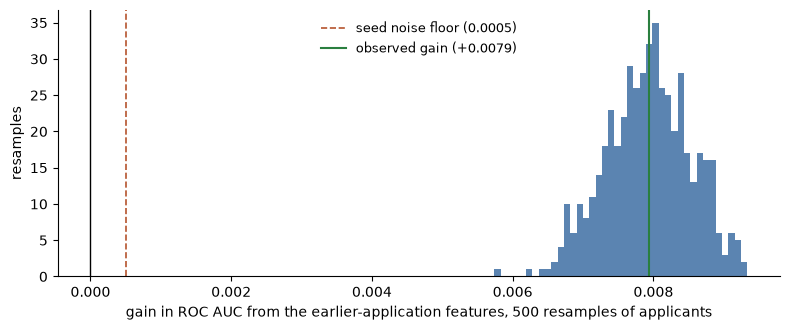

In [12]:
from scipy.stats import rankdata

def fast_auc(y, score):
    ranks = rankdata(score)
    n_pos = y.sum()
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * (len(y) - n_pos))
assert abs(fast_auc(y_arr, baseline['oof']) - roc_auc_score(y_arr, baseline['oof'])) < 1e-12

rng = np.random.default_rng(SEED)
boot = np.empty((500, 2))
for i in range(500):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot[i] = fast_auc(y_arr[idx], baseline['oof'][idx]), fast_auc(y_arr[idx], with_new['oof'][idx])
boot_gain = boot[:, 1] - boot[:, 0]
pooled_gain = roc_auc_score(y_arr, with_new['oof']) - roc_auc_score(y_arr, baseline['oof'])
print(f"gain on all out-of-fold predictions pooled: {pooled_gain:+.5f}  (mean of the five fold gains: {GAIN:+.5f})")
print(f"95% interval for the gain: {np.quantile(boot_gain, 0.025):+.5f} to {np.quantile(boot_gain, 0.975):+.5f}; standard deviation {boot_gain.std(ddof=1):.5f}")
print(f"resamples in which the model with the new features scores higher: {(boot_gain > 0).mean():.1%}; in which the gain exceeds the noise floor: {(boot_gain > NOISE_FLOOR).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(boot_gain, bins=40, color='#5b84b1')
ax.axvline(0, color='black', linewidth=1)
ax.axvline(NOISE_FLOOR, color='#b5542d', linestyle='--', linewidth=1.2, label=f'seed noise floor ({NOISE_FLOOR:.4f})')
ax.axvline(pooled_gain, color='#2a7f3f', linewidth=1.5, label=f'observed gain ({pooled_gain:+.4f})')
ax.set_xlabel('gain in ROC AUC from the earlier-application features, 500 resamples of applicants'); ax.set_ylabel('resamples'); ax.legend(frameon=False, fontsize=9)
sns.despine(); plt.tight_layout(); plt.show()

### 3.4 What the gain means in practice

Each model declines the same share of applicants, the share the reference operating point declines (28.8%), and the question is how many defaults each catches. This uses only the order of the predictions, so it does not depend on calibration.

In [13]:
APPROVE = float((p_old < THRESHOLD).mean())            # the approval rate of the calibrated current model at the reference threshold
def at_approval_rate(score, approve):
    declined = score >= np.quantile(score, approve)
    return {'defaults_caught_pct': (declined & (y_arr == 1)).sum() / y_arr.sum() * 100, 'default_rate_among_approved_pct': y_arr[~declined].mean() * 100}

practical = {}
for approve in [0.90, 0.80, APPROVE, 0.60]:
    a, b = at_approval_rate(baseline['oof'], approve), at_approval_rate(with_new['oof'], approve)
    practical[f'approve {approve:.1%}'] = {'defaults caught, current model (%)': a['defaults_caught_pct'], 'with earlier applications (%)': b['defaults_caught_pct'],
                                          'more defaults caught per 100,000 applicants': (b['defaults_caught_pct'] - a['defaults_caught_pct']) / 100 * y_arr.mean() * 100000,
                                          'default rate among approved, current (%)': a['default_rate_among_approved_pct'], 'with earlier applications  (%)': b['default_rate_among_approved_pct']}
print(pd.DataFrame(practical).T.to_string(float_format=lambda v: f'{v:,.2f}'))

declined_a = baseline['oof'] >= np.quantile(baseline['oof'], APPROVE)
declined_b = with_new['oof'] >= np.quantile(with_new['oof'], APPROVE)
print(f"\nat {APPROVE:.1%} approval: applicants whose decision changes {(declined_a != declined_b).mean():.1%}")
print(f"  newly declined: {int((declined_b & ~declined_a).sum()):,}, default rate {y_arr[declined_b & ~declined_a].mean():.1%}")
print(f"  newly approved: {int((~declined_b & declined_a).sum()):,}, default rate {y_arr[~declined_b & declined_a].mean():.1%}")
print(f"rank correlation between the two models' predictions: {pd.Series(baseline['oof']).corr(pd.Series(with_new['oof']), method='spearman'):.4f}  "
      f"(two seeds of the current model: {pd.Series(baseline['oof']).corr(pd.Series(seed_runs[1]['oof']), method='spearman'):.4f})")
def lift(score):
    order = np.argsort(-score)
    tenth = len(order) // 10
    return y_arr[order[:tenth]].sum() / y_arr.sum() * 100, y_arr[order[-tenth:]].mean() * 100
(top_a, safe_a), (top_b, safe_b) = lift(baseline['oof']), lift(with_new['oof'])
print(f"share of all defaults in the riskiest tenth: {top_a:.2f}% -> {top_b:.2f}%; default rate in the safest tenth: {safe_a:.2f}% -> {safe_b:.2f}%")

               defaults caught, current model (%)  with earlier applications (%)  more defaults caught per 100,000 applicants  default rate among approved, current (%)  with earlier applications  (%)
approve 90.0%                               35.85                          36.41                                        45.93                                      5.75                            5.70
approve 80.0%                               54.78                          56.05                                       102.03                                      4.56                            4.44
approve 71.2%                               66.72                          67.89                                        93.90                                      3.77                            3.64
approve 60.0%                               77.60                          78.88                                       103.25                                      3.01                            2.84


rank correlation between the two models' predictions: 0.9439  (two seeds of the current model: 0.9947)
share of all defaults in the riskiest tenth: 35.85% -> 36.41%; default rate in the safest tenth: 1.05% -> 0.85%


### Stage 3 findings

**The features from earlier applications improve the model**

| Fold | Current model (60) | With earlier applications (101) | Gain |
|---:|---:|---:|---:|
| 0 | 0.7765 | 0.7852 | +0.0087 |
| 1 | 0.7756 | 0.7822 | +0.0067 |
| 2 | 0.7783 | 0.7864 | +0.0081 |
| 3 | 0.7796 | 0.7878 | +0.0082 |
| 4 | 0.7796 | 0.7876 | +0.0080 |
| **Mean** | **0.7779** | **0.7858** | **+0.0079** |

- All four conditions fixed in advance are met. The gain is positive in every fold, 23 times its standard error, and 16 times the seed noise floor.
- PR AUC rises from 0.2654 to 0.2765, in every fold.
- Nothing was tuned to the new features.
- This is a little less than the bureau table added (0.0087 on first addition, 0.0092 like for like) and comes on top of it. The running total, cross-validated: 0.7685 with the application alone, 0.7779 with the bureau, 0.7858 with earlier applications.
- Notebook 05 declined to put a size on the gain and said only "probably at least comparable to the bureau". It is slightly smaller. As a statement held loosely it was about right, and the refusal to give a number was the sound part.

**The controls**

| Model | Gain over the current model | Folds better |
|---|---:|---:|
| Real features, seed 42 | +0.0079 | 5 of 5 |
| Real features, seed 1 | +0.0082 | 5 of 5 |
| Real features, seed 2 | +0.0081 | 5 of 5 |
| Scrambled features | -0.0015 | 0 of 5 |

- The gain is the same across three seeds (0.0079 to 0.0082).
- Giving each applicant another applicant's history with Home Credit makes the model worse by 0.0015, in every fold. More columns alone hurt, as they did in notebook 04 (-0.0020). Against that control the information in the features is worth 0.0095.

**Resampling applicants**
- Across 500 resamples of the out-of-fold predictions the gain has a 95% interval of 0.0068 to 0.0091. The model with the new features scores higher in all 500 and beats the noise floor in all 500.

**In practice**

| Approval rate | Defaults caught, current model | With earlier applications | More caught per 100,000 applicants |
|---:|---:|---:|---:|
| 90% | 35.9% | 36.4% | 46 |
| 80% | 54.8% | 56.1% | 102 |
| 71.2% | 66.7% | 67.9% | 94 |
| 60% | 77.6% | 78.9% | 103 |

- At the reference approval rate the model catches 67.9% of defaults instead of 66.7%, with the same number declined. The default rate among approved applicants falls from 3.77% to 3.64%.
- 7.9% of applicants get a different decision. Those newly declined default at 10.5%, and those newly approved at 8.1%.
- The default rate in the safest tenth falls from 1.05% to 0.85%. The new features help most at identifying good applicants, which fits what they are: a record of loans granted cheaply and repaid.
- The two models' predictions correlate at 0.944. Two seeds of the same model agree at 0.995.

**Leakage check for this stage**
- The new features were built before the folds were looked at, from each applicant's own rows, and need no fitting.
- The comparison is fold against fold, against a baseline reproduced exactly.
- The conditions, the controls and the noise floor were set before this stage ran.
- Notebook 05 made six choices using development outcomes (one feature added, five dropped). Their effect on this gain cannot be separated out here. Notebook 04 found the measurable part of such an effect to be 0.0001, and Kaggle then confirmed its gain in full.
- The holdout was not used.

**Decisions**
- The features are adopted. `with_new` (101 features, 0.7858) is the model to carry forward.

## Stage 4: Where the gain comes from

| Section | Question |
|---|---|
| 4.1 | Who is the gain for? |
| 4.2 | Which families of features carry it? Each family added alone, and each removed |
| 4.3 | What do the three features carrying warnings contribute? |
| 4.4 | How much is just knowing how many earlier applications there were? |

Every model here uses the settings of stage 3 and the same folds.

### 4.1 Who is the gain for?

The new features are all missing for the 5% of applicants with no earlier application. Notebook 04 found that applicants in that position lose a little, because the extra columns crowd out the features the model needs for them.

In [14]:
def group_auc(result):
    return pd.DataFrame({label: [roc_auc_score(y_arr[m & (dev_fold == k)], result['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)] for label, m in GROUPS.items()})
a, b = group_auc(baseline), group_auc(with_new)
d = b - a
who = pd.DataFrame({'applicants': {label: int(m.sum()) for label, m in GROUPS.items()}, 'default_pct': {label: y_arr[m].mean() * 100 for label, m in GROUPS.items()},
                    'current_model': a.mean(), 'with_new_features': b.mean(), 'gain': d.mean(), 'standard_error': d.std(ddof=1) / np.sqrt(N_SPLITS), 'folds_better': (d > 0).sum()})
print(who.to_string(float_format=lambda v: f'{v:,.4f}'))
changed = declined_a != declined_b
print(f"\nof the applicants whose decision changes, {has_prev[changed].mean():.1%} have an earlier application (they are {has_prev.mean():.1%} of all applicants)")
print(f"share whose decision changes: with an earlier application {changed[has_prev].mean():.2%}, without {changed[~has_prev].mean():.2%}")

                            applicants  default_pct  current_model  with_new_features   gain  standard_error  folds_better
all applicants                  246008       8.0729         0.7779             0.7858 0.0079          0.0003             5
no earlier application           13174       6.0043         0.8066             0.8118 0.0052          0.0020             4
has an earlier application      232834       8.1900         0.7761             0.7842 0.0081          0.0004             5
   refused at least once         79161      10.4079         0.7715             0.7805 0.0090          0.0006             5
   never refused                153673       7.0474         0.7725             0.7800 0.0075          0.0006             5
   a loan still running         119862       8.3529         0.7716             0.7823 0.0106          0.0006             5
no bureau record                 35244      10.1209         0.7485             0.7665 0.0179          0.0008             5
neither kind of 

### 4.2 Which families carry the gain?

Each family is added alone to the current model, which shows what it can do by itself, and removed from the full model, which shows what the other families cannot supply.

twelve models: 1.1 minutes (12 loaded from cache)

                     features  gain_when_added_alone  folds_better  share_of_full_gain_pct  change_when_removed  folds_worse  se_removed
pricing and terms          10               +0.00495             5               +62.37686             -0.00278            5    +0.00027
loan state                  4               +0.00334             5               +42.08395             -0.00163            5    +0.00031
product and channel         9               +0.00199             5               +25.04109             -0.00001            2    +0.00010
outcomes                    5               +0.00072             4                +9.07017             +0.00006            1    +0.00009
refusals                    7               +0.00030             3                +3.79966             +0.00018            2    +0.00017
timing                      6               +0.00007             2                +0.83118             -0.00005            3   

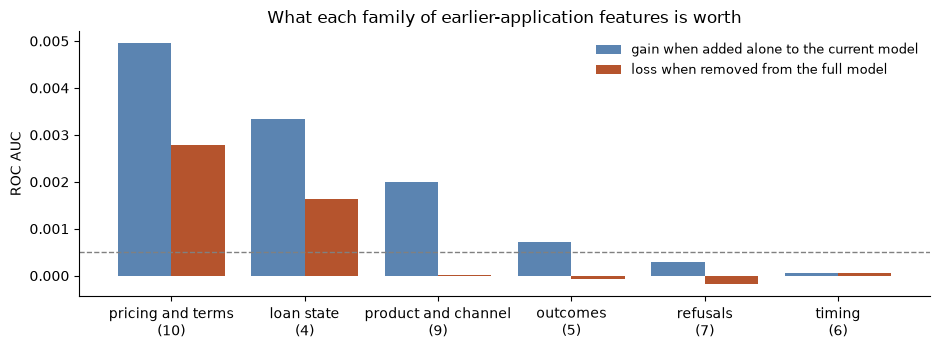

In [15]:
FAMILIES = {family: [c for c in PREV if FAMILY[c] == family] for family in ['pricing and terms', 'refusals', 'outcomes', 'product and channel', 'timing', 'loan state']}
assert sum(len(v) for v in FAMILIES.values()) == len(PREV)

started = time.time()
alone_runs = {family: run(CURRENT + members) for family, members in FAMILIES.items()}
without_runs = {family: run([c for c in WITH_NEW if c not in members]) for family, members in FAMILIES.items()}
print(f"twelve models: {(time.time() - started) / 60:.1f} minutes ({sum(r['cached'] for r in list(alone_runs.values()) + list(without_runs.values()))} loaded from cache)")
rows = {}
for family, members in FAMILIES.items():
    up, down = compare(alone_runs[family], baseline), compare(without_runs[family], with_new)
    rows[family] = {'features': len(members), 'gain_when_added_alone': up['mean_difference'], 'folds_better': up['folds_better'], 'share_of_full_gain_pct': up['mean_difference'] / GAIN * 100,
                    'change_when_removed': down['mean_difference'], 'folds_worse': N_SPLITS - down['folds_better'], 'se_removed': down['standard_error']}
families = pd.DataFrame(rows).T.sort_values('gain_when_added_alone', ascending=False)
print()
print(families.astype({'features': int, 'folds_better': int, 'folds_worse': int}).to_string(float_format=lambda v: f'{v:+.5f}'))
print(f"\nfull gain from all six families together: {GAIN:+.5f}")
print(f"sum of the six gains when added alone: {families['gain_when_added_alone'].sum():+.5f}  ({families['gain_when_added_alone'].sum() / GAIN:.0%} of the full gain: above 100% means the families overlap)")
print(f"sum of the six losses when removed:    {families['change_when_removed'].sum():+.5f}  ({-families['change_when_removed'].sum() / GAIN:.0%} of the full gain is unique to one family)")

fig, ax = plt.subplots(figsize=(9.5, 3.6))
x = np.arange(len(families))
ax.bar(x - 0.2, families['gain_when_added_alone'].astype(float), 0.4, label='gain when added alone to the current model', color='#5b84b1')
ax.bar(x + 0.2, -families['change_when_removed'].astype(float), 0.4, label='loss when removed from the full model', color='#b5542d')
ax.axhline(NOISE_FLOOR, color='grey', linestyle='--', linewidth=1)
ax.set_xticks(x); ax.set_xticklabels([f"{f}\n({int(n)})" for f, n in zip(families.index, families['features'])]); ax.set_ylabel('ROC AUC'); ax.legend(frameon=False, fontsize=9)
ax.set_title('What each family of earlier-application features is worth')
sns.despine(); plt.tight_layout(); plt.show()

### 4.3 The features carrying warnings

Notebook 05 sent three features forward with a warning.

- **`RUNNING_MAX_DAYS_REMAINING`**, the longest remaining term on a loan still running. Its values differ between train and test (a median of 272 days against 215), and it was the single feature that added most beyond the current model.
- **`DAYS_SINCE_FIRST_DECISION`** and **`COST_OF_CREDIT_LAST`**, which differ between the files in fine detail only.

Each group is removed from the full model. A small loss means the warning costs little to act on.

In [16]:
SHIFT_WARNED = ['PREV_RUNNING_MAX_DAYS_REMAINING']
FINE_DETAIL = [c for c in WARNED if c not in SHIFT_WARNED]
assert set(SHIFT_WARNED) <= set(PREV) and len(FINE_DETAIL) == 2
print('fine-detail warnings:', [c.replace('PREV_', '') for c in FINE_DETAIL])

started = time.time()
warned_runs = {
    'without RUNNING_MAX_DAYS_REMAINING': run([c for c in WITH_NEW if c not in SHIFT_WARNED]),
    'without the 2 fine-detail features': run([c for c in WITH_NEW if c not in FINE_DETAIL]),
    'without all 3': run([c for c in WITH_NEW if c not in SHIFT_WARNED + FINE_DETAIL]),
}
print(f"three models: {(time.time() - started) / 60:.1f} minutes")
warned = {}
for label, r in warned_runs.items():
    against_full, against_base = compare(r, with_new), compare(r, baseline)
    warned[label] = {'roc_auc': r['mean']['roc_auc'], 'change_from_full_model': against_full['mean_difference'], 'standard_error': against_full['standard_error'],
                     'folds_worse': N_SPLITS - against_full['folds_better'], 'gain_over_current_model': against_base['mean_difference'],
                     'share_of_full_gain_kept_pct': against_base['mean_difference'] / GAIN * 100, 'still_meets_all_four': verdict(r)['improves']}
print()
print(pd.DataFrame(warned).T.to_string(float_format=lambda v: f'{v:+.5f}'))

# who the flagged feature matters for
has_running_term = X_dev['PREV_RUNNING_MAX_DAYS_REMAINING'].notna().values
no_flag = warned_runs['without RUNNING_MAX_DAYS_REMAINING']
auc_in = lambda r, m: float(np.mean([roc_auc_score(y_arr[m & (dev_fold == k)], r['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)]))
print(f"\napplicants with a running loan that has a planned end: {int(has_running_term.sum()):,} ({has_running_term.mean():.1%})")
print(f"ROC AUC within that group: current model {auc_in(baseline, has_running_term):.4f}, full model {auc_in(with_new, has_running_term):.4f}, full model without the feature {auc_in(no_flag, has_running_term):.4f}")
print(f"ROC AUC among the rest:    current model {auc_in(baseline, ~has_running_term):.4f}, full model {auc_in(with_new, ~has_running_term):.4f}, full model without the feature {auc_in(no_flag, ~has_running_term):.4f}")
term = X_dev.loc[has_running_term, 'PREV_RUNNING_MAX_DAYS_REMAINING']
band = pd.cut(term, [0, 90, 180, 365, 730, 5000], labels=['up to 90 days', '91 to 180', '181 to 365', '1 to 2 years', 'over 2 years'])
print('\ndefault rate (%) by the longest remaining term, with the current model\'s calibrated prediction beside it:')
print(pd.DataFrame({'applicants': band.value_counts().sort_index(), 'actual': pd.Series(y_arr[has_running_term]).groupby(band.values, observed=True).mean() * 100,
                    'current model predicts': pd.Series(p_old[has_running_term]).groupby(band.values, observed=True).mean() * 100}).round(2).to_string())

fine-detail warnings: ['DAYS_SINCE_FIRST_DECISION', 'COST_OF_CREDIT_LAST']


three models: 0.1 minutes

                                    roc_auc change_from_full_model standard_error folds_worse gain_over_current_model share_of_full_gain_kept_pct still_meets_all_four
without RUNNING_MAX_DAYS_REMAINING +0.78461               -0.00122       +0.00016           5                +0.00671                   +84.59694                 True
without the 2 fine-detail features +0.78601               +0.00017       +0.00016           2                +0.00811                  +102.18902                 True
without all 3                      +0.78431               -0.00153       +0.00019           5                +0.00641                   +80.77376                 True

applicants with a running loan that has a planned end: 86,228 (35.1%)


ROC AUC within that group: current model 0.7698, full model 0.7827, full model without the feature 0.7789


ROC AUC among the rest:    current model 0.7821, full model 0.7874, full model without the feature 0.7875

default rate (%) by the longest remaining term, with the current model's calibrated prediction beside it:
               applicants  actual  current model predicts
up to 90 days       16054    6.78                    8.20
91 to 180           14890    6.72                    8.26
181 to 365          22934    7.81                    8.32
1 to 2 years        17068    8.46                    7.71
over 2 years        15282    9.59                    6.96


### 4.4 How much is just the number of earlier applications?

In [17]:
started = time.time()
count_only = run(CURRENT + ['PREV_N_APPLICATIONS'])
strongest_four = ['PREV_COST_OF_CREDIT_MEAN', 'PREV_COST_OF_CREDIT_LAST', 'PREV_RUNNING_MAX_DAYS_REMAINING', 'PREV_GRANTED_TO_REQUESTED_MEAN']
top_four = run(CURRENT + strongest_four)
print(f"two models: {(time.time() - started) / 60:.1f} minutes")
steps = {}
for label, r in {'current model (60)': baseline, 'plus the number of earlier applications (61)': count_only,
                 'plus the four features notebook 05 ranked highest beyond the current model (64)': top_four, 'plus all 41 features (101)': with_new}.items():
    c = compare(r, baseline)
    steps[label] = {'roc_auc': r['mean']['roc_auc'], 'gain': c['mean_difference'], 'folds_better': c['folds_better'], 'share_of_full_gain_pct': c['mean_difference'] / GAIN * 100}
print()
print(pd.DataFrame(steps).T.astype({'folds_better': int}).to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nthe four features: {[c.replace('PREV_', '') for c in strongest_four]}")

two models: 0.1 minutes

                                                                                 roc_auc    gain  folds_better  share_of_full_gain_pct
current model (60)                                                               0.77790 0.00000             0                 0.00000
plus the number of earlier applications (61)                                     0.77809 0.00019             3                 2.37095
plus the four features notebook 05 ranked highest beyond the current model (64)  0.78268 0.00478             5                60.25431
plus all 41 features (101)                                                       0.78584 0.00794             5               100.00000

the four features: ['COST_OF_CREDIT_MEAN', 'COST_OF_CREDIT_LAST', 'RUNNING_MAX_DAYS_REMAINING', 'GRANTED_TO_REQUESTED_MEAN']


### Stage 4 findings

**Nobody loses this time**

| Group | Applicants | Current model | With new features | Gain | Folds better |
|---|---:|---:|---:|---:|---:|
| Has an earlier application | 232,834 | 0.7761 | 0.7842 | +0.0081 | 5 of 5 |
| A loan still running | 119,862 | 0.7716 | 0.7823 | +0.0106 | 5 of 5 |
| Refused at least once | 79,161 | 0.7715 | 0.7805 | +0.0090 | 5 of 5 |
| Never refused | 153,673 | 0.7725 | 0.7800 | +0.0075 | 5 of 5 |
| **No bureau record** | 35,244 | 0.7485 | 0.7665 | **+0.0179** | 5 of 5 |
| No earlier application | 13,174 | 0.8066 | 0.8118 | +0.0052 | 4 of 5 |

- **The applicants the bureau table could not help gain the most.** Those with no bureau record were 0.0028 worse off after notebook 04 and are now 0.0179 better off. For them the history with Home Credit is the only credit history there is, and 94% of them have one.
- Applicants with no earlier application do not lose, as I had expected from notebook 04. They gain 0.0052, in 4 of 5 folds, with a wide standard error because they are few. All 41 features are missing for them, so this is not from information about them. A plausible reason is that the model can now set these applicants apart cleanly, since their count is zero, and they are a different kind of applicant (stage 2 of notebook 05). I have not tested that explanation.
- The gain is largest for applicants with a loan still running (+0.0106).

**Pricing and loan state carry the gain. Refusals carry almost none.**

| Family | Features | Gain when added alone | Share of the full gain | Change when removed |
|---|---:|---:|---:|---:|
| Pricing and terms | 10 | +0.0050 | 62% | -0.0028 |
| Loan state | 4 | +0.0033 | 42% | -0.0016 |
| Product and channel | 9 | +0.0020 | 25% | 0.0000 |
| Outcomes | 5 | +0.0007 | 9% | +0.0001 |
| Refusals | 7 | +0.0003 | 4% | +0.0002 |
| Timing | 6 | +0.0001 | 1% | 0.0000 |

- How Home Credit priced earlier loans gives 62% of the gain alone and costs the most to remove. This is the family notebook 05 identified as almost entirely new to the model, and it is.
- Four features on the state of earlier loans give 42% alone. Most of that is one feature, taken up below.
- **The refusal family adds 0.0003, in 3 of 5 folds.** That is inside the noise. Notebook 05 called refusals "the clearest signal" in the table, on the strength of default rates that double from no refusals to five or more. Those rates are real. But stage 8 of notebook 05 already showed refusals falling from 0.56 alone to 0.52 against the current model, and here, added to that model, they contribute nothing measurable. Applicants whom Home Credit refused are applicants the model already rates as risky, from their external scores and their bureau record.
- This is the lesson of notebook 04 from the other side. There, features that looked weak one at a time added up to a large gain. Here, a family that looked strong one at a time adds almost nothing. A feature's relationship with default says little about what it adds to a model that already knows a great deal.
- Timing adds nothing, and outcomes very little. Together with refusals that is 18 features contributing about 0.001 between them.
- The families overlap: their gains alone sum to 143% of the full gain, and 53% of it is unique to one family.

**One feature is worth 15% of the gain, and it is the one with the shift warning**

| Model | ROC AUC | Change from the full model | Folds worse |
|---|---:|---:|---:|
| Without `RUNNING_MAX_DAYS_REMAINING` | 0.7846 | -0.0012 | 5 of 5 |
| Without the 2 fine-detail features | 0.7860 | +0.0002 | 2 of 5 |
| Without all 3 | 0.7843 | -0.0015 | 5 of 5 |

- The longest remaining term on a running loan is worth 0.0012, more than the refusal, outcome and timing families together. Among the 35% of applicants who have such a loan, the model scores 0.7827 with it and 0.7789 without. Among the rest it makes no difference.
- What it tells the model is something the current model has backwards:

| Longest remaining term | Actual default rate | Current model predicts |
|---|---:|---:|
| Up to 90 days | 6.8% | 8.2% |
| 91 to 180 days | 6.7% | 8.3% |
| 181 to 365 days | 7.8% | 8.3% |
| 1 to 2 years | 8.5% | 7.7% |
| Over 2 years | 9.6% | 7.0% |

- Applicants with a long time still to run on an existing Home Credit loan default more, and the current model expects them to default less. Someone taking a new loan while years of payments remain on another is carrying more, and nothing in the application or the bureau table says so.
- **Decision: kept.** The warning stands. Test applicants' running loans are closer to their end (a median of 215 days against 272), so the feature's values sit lower in the test file. The pattern above is smooth and has an obvious reading, which makes it less likely to be an accident of the training file. As with microloans in notebook 04, stage 9 writes a diagnostic submission without it.
- The two features with a fine-detail warning cost nothing to remove (+0.0002). Whether they stay is a matter for pruning.

**The count alone is worth almost nothing**
- The number of earlier applications adds 0.0002. The four features notebook 05 ranked highest give 60% of the gain (0.0048).

**Leakage check for this stage**
- All 17 models use the stage 3 settings and the frozen folds.
- No feature list was chosen here. The one decision, keeping the feature with the shift warning, was planned before its value was known.
- The holdout was not used.

**Decisions**
- Keep `RUNNING_MAX_DAYS_REMAINING`, with a diagnostic submission in stage 9.
- Carry to stage 5: refusals, outcomes and timing are the families most likely to be prunable, with the caution that several refusal features are rare events.

## Stage 5: Pruning

Can the list of new features be shortened at no cost?

Stage 4 suggests it can: three of the six families add about 0.001 between them. The method is that of notebook 04, including what it learned.

- **Selection inside the folds.** In each fold the new features are ranked using the training folds only, and the model is fitted on the ones that ranking kept. That gives an honest score for "the best *m*". One fixed list is drawn up only afterwards, and the difference between its score and the honest one is reported.
- **Rare events judged separately.** A ranking by average contribution undervalues a feature that is zero for almost everyone. In notebook 04 four such features, ranked near the bottom, turned out to be worth more than the sixteen correctly removed. So the rare-event features are identified in advance, and those the ranking drops are tested by adding them back.

**The rules, fixed in advance.**
1. Take the smallest number of new features whose honest score is within the noise floor (0.0005) of the full model's.
2. Rare-event features are those that are zero for at least 90% of applicants with an earlier application. Add back the ones the ranking dropped. Keep them if the overall score does not fall by more than the noise floor.

The 60 features of the current model are always kept. They were pruned in notebooks 02 and 04.

| Section | What it does |
|---|---|
| 5.1 | Rank the new features inside each fold |
| 5.2 | The honest score for the best 25, 20, 15 and 10 |
| 5.3 | A fixed list, and the rare-event test |
| 5.4 | Features built from two tables |

### 5.1 Ranking inside each fold

In [18]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

FAST_TREES, FAST_RATE = 1400, 0.05              # a quicker version of the model for ranking: the same settings, 3,500 trees at 0.02 scaled to 0.05

def rank_candidates(X_encoded, y, always, candidates):
    # Ranks the candidates using these rows only: fit on 80%, measure each feature's average contribution on the other 20%.
    y = np.asarray(y)
    grow, watch = train_test_split(np.arange(len(y)), test_size=0.20, stratify=y, random_state=SEED)
    columns = list(always) + list(candidates)
    model = lgbm_model(BEST_PARAMS, FAST_TREES, FAST_RATE).fit(X_encoded.iloc[grow][columns], y[grow])
    contributions = model.booster_.predict(X_encoded.iloc[watch][columns], pred_contrib=True)[:, :-1]
    size = pd.Series(np.abs(contributions).mean(axis=0), index=columns)
    return size[list(candidates)].sort_values(ascending=False)

class TopCandidates(BaseEstimator, TransformerMixin):
    # Keeps the 'always' columns and the best 'keep' of the 'candidates', ranked on the rows passed to fit.
    def __init__(self, always, candidates, keep):
        self.always = always
        self.candidates = candidates
        self.keep = keep
    def fit(self, X, y):
        self.ranking_ = rank_candidates(X, y, self.always, self.candidates)
        self.columns_ = list(self.always) + list(self.ranking_.index[:self.keep])
        return self
    def transform(self, X):
        return X[self.columns_]

def selecting_pipeline(keep):
    return Pipeline([('preprocess', Pipeline([('encode', CategoryEncoder(columns=list(TEXT_FEATURES))), ('choose', TopCandidates(CURRENT, PREV, keep))])), ('model', FINAL())])

RANK_PATH = CACHE_DIR / 'rankings_v1.joblib'
started = time.time()
if RANK_PATH.exists():
    fold_rankings = joblib.load(RANK_PATH)
else:
    fold_rankings = {}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for k in range(N_SPLITS):
            fit = dev_fold != k
            encoded = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit]).transform(X_dev[fit])
            fold_rankings[k] = rank_candidates(encoded, y_arr[fit], CURRENT, PREV)
    joblib.dump(fold_rankings, RANK_PATH)
print(f"five rankings: {(time.time() - started) / 60:.1f} minutes")

size = pd.DataFrame(fold_rankings)
ranks = size.rank(ascending=False).astype(int)
zero_share = (X_dev.loc[has_prev, PREV] == 0).mean()
ranking = pd.DataFrame({'family': pd.Series(FAMILY), 'mean_contribution': size.mean(axis=1), 'mean_rank': ranks.mean(axis=1), 'best_rank': ranks.min(axis=1), 'worst_rank': ranks.max(axis=1),
                        'share_pct': size.mean(axis=1) / size.mean(axis=1).sum() * 100, 'zero_for_pct_of_applicants': zero_share * 100}).sort_values('mean_rank')
ranking.index = [c.replace('PREV_', '') for c in ranking.index]
ranking['cumulative_pct'] = ranking['share_pct'].cumsum()
print(ranking.to_string(float_format=lambda v: f'{v:.3f}'))
RARE_EVENTS = [c for c in PREV if zero_share[c] >= 0.90]
print(f"\nrare-event features (zero for at least 90% of applicants with an earlier application): {[c.replace('PREV_', '') for c in RARE_EVENTS]}")
print(pd.DataFrame({m: {'chosen in all five folds': int((ranks <= m).all(axis=1).sum()), 'chosen in at least one': int((ranks <= m).any(axis=1).sum()),
                        'share of the new features\' contribution (%)': float(size.mean(axis=1).sort_values(ascending=False).iloc[:m].sum() / size.mean(axis=1).sum() * 100)} for m in [25, 20, 15, 10]}).T.round(1).to_string())
print(pd.DataFrame({'features': ranking.groupby('family').size(), 'share_pct': ranking.groupby('family')['share_pct'].sum(), 'best_rank': ranking.groupby('family')['mean_rank'].min()}).sort_values('share_pct', ascending=False).round(1).to_string())

five rankings: 0.0 minutes


                                          family  mean_contribution  mean_rank  best_rank  worst_rank  share_pct  zero_for_pct_of_applicants  cumulative_pct
AMT_ANNUITY_MEAN               pricing and terms              0.096      1.000          1           1     10.792                       0.003          10.792
RUNNING_MAX_DAYS_REMAINING            loan state              0.079      2.000          2           2      8.834                       0.000          19.626
COST_OF_CREDIT_MEAN            pricing and terms              0.071      3.000          3           3      8.009                       0.000          27.635
N_LOANS_ENDED                         loan state              0.049      4.800          4           6      5.531                       8.235          33.166
RUNNING_ANNUITY_SUM                   loan state              0.046      5.400          4           8      5.120                       0.085          38.286
GRANTED_TO_REQUESTED_MEAN      pricing and terms          

### 5.2 The honest score for the best *m*

In [19]:
def run_pipeline(pipe, X=None):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(pipe, X_dev if X is None else X, y_arr, dev_fold, cache_dir=CACHE_DIR)

def group_change(result, reference, mask):
    d = [roc_auc_score(y_arr[mask & (dev_fold == k)], result['oof'][mask & (dev_fold == k)]) - roc_auc_score(y_arr[mask & (dev_fold == k)], reference['oof'][mask & (dev_fold == k)]) for k in range(N_SPLITS)]
    return float(np.mean(d))

M_VALUES = [25, 20, 15, 10]
started = time.time()
selected_runs = {m: run_pipeline(selecting_pipeline(m)) for m in M_VALUES}
print(f"four models with selection inside the folds: {(time.time() - started) / 60:.1f} minutes")
rows = {}
for label, r in {'all 41 new features': with_new, **{f'best {m}, chosen in each fold': selected_runs[m] for m in M_VALUES}, 'no new features': baseline}.items():
    full, base = compare(r, with_new), compare(r, baseline)
    rows[label] = {'roc_auc': r['mean']['roc_auc'], 'change_from_all_41': full['mean_difference'], 'folds_worse': (N_SPLITS - full['folds_better']) if r is not with_new else 0,
                   'gain_over_current_model': base['mean_difference'], 'within_noise_of_all_41': full['mean_difference'] > -NOISE_FLOOR}
honest = pd.DataFrame(rows).T
print()
print(honest.to_string(float_format=lambda v: f'{v:+.5f}'))
eligible = [m for m in M_VALUES if honest.loc[f'best {m}, chosen in each fold', 'within_noise_of_all_41']]
M_CHOSEN = min(eligible) if eligible else 41
print(f"\nrule 1: the smallest number of new features within {NOISE_FLOOR:.4f} of the full model -> {M_CHOSEN}")

four models with selection inside the folds: 0.2 minutes

                              roc_auc change_from_all_41 folds_worse gain_over_current_model within_noise_of_all_41
all 41 new features          +0.78584           +0.00000           0                +0.00794                   True
best 25, chosen in each fold +0.78558           -0.00026           4                +0.00768                   True
best 20, chosen in each fold +0.78572           -0.00012           2                +0.00781                   True
best 15, chosen in each fold +0.78533           -0.00051           5                +0.00743                  False
best 10, chosen in each fold +0.78504           -0.00080           5                +0.00714                  False
no new features              +0.77790           -0.00794           5                +0.00000                  False

rule 1: the smallest number of new features within 0.0005 of the full model -> 20


### 5.3 A fixed list, and the rare-event test

In [20]:
order = ['PREV_' + c for c in ranking.index]
RULE_PREV = order[:M_CHOSEN]
print(f"fixed list by rule 1: {len(RULE_PREV)} new features")
print(pd.Series({f: [c.replace('PREV_', '') for c in RULE_PREV if FAMILY[c] == f] for f in FAMILIES}).to_string())
print(f"\ndropped: {[c.replace('PREV_', '') for c in order[M_CHOSEN:]]}")

started = time.time()
pruned_rule = run(CURRENT + RULE_PREV)
vs_full = compare(pruned_rule, with_new)
print(f"\nfixed list of {len(CURRENT) + len(RULE_PREV)} features: ROC AUC {pruned_rule['mean']['roc_auc']:.5f}; against all 41: {vs_full['mean_difference']:+.5f} (better in {vs_full['folds_better']} of 5 folds)")
if M_CHOSEN in selected_runs:
    print(f"against the honest score for the same number: {compare(pruned_rule, selected_runs[M_CHOSEN])['mean_difference']:+.5f}  <- what fixing the list on these folds flatters")

# rule 2: the rare-event features the ranking dropped
rare_dropped = [c for c in RARE_EVENTS if c not in RULE_PREV]
print(f"\nrare-event features the ranking dropped: {[c.replace('PREV_', '') for c in rare_dropped]}")
if rare_dropped:
    pruned_rare = run(CURRENT + RULE_PREV + rare_dropped)
    rare_vs = compare(pruned_rare, pruned_rule)
    print(f"added back: ROC AUC {pruned_rule['mean']['roc_auc']:.5f} -> {pruned_rare['mean']['roc_auc']:.5f}: change {rare_vs['mean_difference']:+.5f} (standard error {rare_vs['standard_error']:.5f}, better in {rare_vs['folds_better']} of 5 folds)")
    pct = lambda score: pd.Series(score).rank(pct=True).values
    positions = {}
    for c in rare_dropped:
        m = (X_dev[c] > 0).values
        positions[c.replace('PREV_', '')] = {'applicants': int(m.sum()), 'pct_of_applicants': m.mean() * 100, 'default_pct': y_arr[m].mean() * 100, 'current model': pct(baseline['oof'])[m].mean(),
                                            'rule list (without)': pct(pruned_rule['oof'])[m].mean(), 'rule list plus the rare events': pct(pruned_rare['oof'])[m].mean(), 'all 41': pct(with_new['oof'])[m].mean()}
    print('\napplicants with the event: their average position in the risk ordering under each model (1 = riskiest of all)')
    print(pd.DataFrame(positions).T.to_string(float_format=lambda v: f'{v:,.3f}'))
    ADD_RARE = bool(rare_vs['mean_difference'] > -NOISE_FLOOR)
    print(f"\nrule 2: the overall score does not fall by more than {NOISE_FLOOR:.4f} -> {'kept' if ADD_RARE else 'left out'}")
else:
    ADD_RARE, pruned_rare = False, pruned_rule
KEPT_PREV = RULE_PREV + (rare_dropped if ADD_RARE else [])
PRUNED, pruned = CURRENT + KEPT_PREV, (pruned_rare if ADD_RARE else pruned_rule)
print(f"\nfixed list now: {len(KEPT_PREV)} new features, {len(PRUNED)} in total; ROC AUC {pruned['mean']['roc_auc']:.5f}; against all 41: {compare(pruned, with_new)['mean_difference']:+.5f}; "
      f"against the current model: {compare(pruned, baseline)['mean_difference']:+.5f}")
print(f"by family: {pd.Series([FAMILY[c] for c in KEPT_PREV]).value_counts().to_dict()}")
print(f"warned features still in the list: {[c.replace('PREV_', '') for c in KEPT_PREV if c in WARNED]}")
print(f"applicants with no earlier application: {group_change(pruned, baseline, ~has_prev):+.5f} against the current model; applicants with no bureau record: {group_change(pruned, baseline, ~has_bureau):+.5f}")
print(f"fitting time per fold: {pruned['folds']['fit_seconds'].mean():.0f} seconds, against {with_new['folds']['fit_seconds'].mean():.0f} with all 41 (this session's timings vary with the machine's load)")
print(f"minutes for this section: {(time.time() - started) / 60:.1f}")

fixed list by rule 1: 20 new features
pricing and terms      [AMT_ANNUITY_MEAN, COST_OF_CREDIT_MEAN, GRANTE...
refusals                                       [DAYS_SINCE_LAST_REFUSAL]
outcomes                                                    [N_APPROVED]
product and channel              [N_APPROVED_CASH, N_APPROVED_REVOLVING]
timing                 [DAYS_SINCE_FIRST_DECISION, DAYS_SINCE_LAST_DE...
loan state             [RUNNING_MAX_DAYS_REMAINING, N_LOANS_ENDED, RU...

dropped: ['N_REFUSED', 'LAST_DECIDED_WAS_REFUSED', 'N_APPROVED_CONSUMER', 'N_CLIENT_TYPE_NEW', 'N_X_SELL', 'N_REFUSED_24M', 'N_CANCELED', 'N_CHANNEL_AP_CASH', 'N_REFUSED_CASH', 'N_REFUSED_HC', 'N_LOANS_RUNNING', 'N_REFUSED_LIMIT', 'N_WALK_IN', 'N_DECIDED_12M', 'N_REFUSED_12M', 'N_APPLICATIONS', 'N_REFUSED_REVOLVING', 'N_APPROVED_HIGH_YIELD', 'N_REFUSED_SCOFR', 'HISTORY_REACHES_WINDOW_EDGE', 'N_REFUSED_OTHER']



fixed list of 80 features: ROC AUC 0.78570; against all 41: -0.00013 (better in 3 of 5 folds)
against the honest score for the same number: -0.00001  <- what fixing the list on these folds flatters

rare-event features the ranking dropped: ['N_REFUSED_LIMIT', 'N_REFUSED_SCOFR', 'N_REFUSED_OTHER', 'N_CHANNEL_AP_CASH', 'N_REFUSED_REVOLVING']


added back: ROC AUC 0.78570 -> 0.78565: change -0.00005 (standard error 0.00016, better in 3 of 5 folds)



applicants with the event: their average position in the risk ordering under each model (1 = riskiest of all)
                     applicants  pct_of_applicants  default_pct  current model  rule list (without)  rule list plus the rare events  all 41
N_REFUSED_LIMIT      22,494.000              9.144       11.977          0.583                0.605                           0.615   0.613
N_REFUSED_SCOFR       5,313.000              2.160       19.575          0.741                0.761                           0.771   0.769
N_REFUSED_OTHER       4,358.000              1.771       10.257          0.552                0.573                           0.572   0.572
N_CHANNEL_AP_CASH    17,991.000              7.313       11.372          0.560                0.572                           0.593   0.592
N_REFUSED_REVOLVING  19,777.000              8.039       12.545          0.600                0.619                           0.626   0.624

rule 2: the overall score does not fall by more 

### 5.4 Features built from two tables

Notebook 05 left one idea for this notebook. The annuity on loans still running is what the applicant already pays Home Credit each month, and it means more beside their income and the annuity of the loan they are now applying for. Notebook 04 tested the equivalent idea for the bureau and found it made the model slightly worse, so this is a test and not an assumption.

Each ratio is computed from the applicant's own row.

In [21]:
X_cross = X_dev.copy()
income, running = X_cross['AMT_INCOME_TOTAL'], X_cross['PREV_RUNNING_ANNUITY_SUM']
X_cross['CROSS_RUNNING_ANNUITY_TO_INCOME'] = running / income
X_cross['CROSS_ALL_ANNUITIES_TO_INCOME'] = (running.fillna(0) + X_cross['AMT_ANNUITY']) / income
positive = lambda s: s.where(s > 0)                      # a past average of zero gives no ratio (a handful of approved applications have an annuity of zero)
X_cross['CROSS_NEW_CREDIT_TO_PAST_AVERAGE'] = X_cross['AMT_CREDIT'] / positive(X_cross['PREV_AMT_CREDIT_MEAN'])
X_cross['CROSS_NEW_ANNUITY_TO_PAST_AVERAGE'] = X_cross['AMT_ANNUITY'] / positive(X_cross['PREV_AMT_ANNUITY_MEAN'])
CROSS = [c for c in X_cross.columns if c.startswith('CROSS_')]
assert not np.isinf(X_cross[CROSS].to_numpy()).any() and (income.dropna() > 0).all()
print(f"applicants whose past average annuity is zero: {int((X_cross['PREV_AMT_ANNUITY_MEAN'] == 0).sum())}")
alone_cross = {}
for c in CROSS:
    ok = X_cross[c].notna().values
    a = roc_auc_score(y_arr[ok], X_cross[c].values[ok])
    alone_cross[c.replace('CROSS_', '')] = {'has_a_value_pct': ok.mean() * 100, 'auc_alone': max(a, 1 - a), 'higher_value_means': 'more risk' if a > 0.5 else 'less risk'}
print(pd.DataFrame(alone_cross).T.to_string(float_format=lambda v: f'{v:.4f}'))

started = time.time()
with_cross = run(PRUNED + CROSS, X=X_cross)
print(f"\nfixed list plus the four ratios ({len(PRUNED) + len(CROSS)} features): {'loaded from cache' if with_cross['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
cross_verdict = verdict(with_cross, pruned)
print(f"ROC AUC {pruned['mean']['roc_auc']:.5f} -> {with_cross['mean']['roc_auc']:.5f}: change {cross_verdict['mean_difference']:+.5f} (standard error {cross_verdict['standard_error']:.5f}, better in {cross_verdict['folds_better']} of 5 folds)")
for name, ok in cross_verdict['conditions'].items():
    print(f"  {'MET    ' if ok else 'NOT MET'}  {name}")
ADD_CROSS = bool(cross_verdict['improves'])
if ADD_CROSS:
    X_dev = X_cross
X_cross = None
CHOSEN_FEATURES = PRUNED + CROSS if ADD_CROSS else PRUNED
chosen = with_cross if ADD_CROSS else pruned
print(f"\nfeature list carried forward: {len(CHOSEN_FEATURES)} features ({len(APP_IN_MODEL)} application, {len(BUREAU_IN_MODEL)} bureau, {len(KEPT_PREV)} earlier applications, {len(CROSS) if ADD_CROSS else 0} built from two tables)")
print(f"its ROC AUC: {chosen['mean']['roc_auc']:.5f}; gain over the current model {compare(chosen, baseline)['mean_difference']:+.5f}; meets all four conditions: {verdict(chosen)['improves']}")

applicants whose past average annuity is zero: 7


                            has_a_value_pct auc_alone higher_value_means
RUNNING_ANNUITY_TO_INCOME           48.7224    0.5382          less risk
ALL_ANNUITIES_TO_INCOME             99.9955    0.5084          more risk
NEW_CREDIT_TO_PAST_AVERAGE          94.3124    0.5252          more risk
NEW_ANNUITY_TO_PAST_AVERAGE         94.3083    0.5520          more risk



fixed list plus the four ratios (89 features): loaded from cache
ROC AUC 0.78565 -> 0.78564: change -0.00001 (standard error 0.00020, better in 3 of 5 folds)
  NOT MET  1. mean ROC AUC is higher
  NOT MET  2. higher in at least four of five folds
  NOT MET  3. gain is more than twice its standard error
  NOT MET  4. gain exceeds the seed noise floor of 0.0005

feature list carried forward: 85 features (36 application, 24 bureau, 25 earlier applications, 0 built from two tables)
its ROC AUC: 0.78565; gain over the current model +0.00775; meets all four conditions: True


### Stage 5 findings

**Twenty of the 41 features carry the gain**

| New features | ROC AUC | Against all 41 | Folds worse |
|---|---:|---:|---:|
| All 41 | 0.78584 | | |
| Best 25, chosen in each fold | 0.78558 | -0.00026 | 4 of 5 |
| Best 20, chosen in each fold | 0.78572 | -0.00012 | 2 of 5 |
| Best 15, chosen in each fold | 0.78533 | -0.00051 | 5 of 5 |
| Best 10, chosen in each fold | 0.78504 | -0.00080 | 5 of 5 |

- These scores are honest: each fold ranked the features and chose its own list from its training rows, so the validation fold never influenced which features it was scored with.
- Rule 1 (the smallest number within the noise floor of 0.0005 of the full model) picks **20**. Fifteen misses by 0.00001.
- The best 20 score slightly above the best 25. That is noise, not a sign that five features hurt. Differences of this size are below what a change of seed produces.
- The ranking is stable at the top. The same three features are first, second and third in all five folds: the average annuity of earlier loans, the longest remaining term on a running loan, and the average cost of credit. Fourteen of the 20 are chosen in every fold.
- Pricing and terms hold 43% of what the new features contribute, and loan state 20%. This agrees with stage 4, which measured it a different way.

**What fixing the list costs in honesty**
- The single list of 20 used from here on was ranked on all the development rows, which the honest scores above avoided. The fixed list scores 0.78570 against the honest 0.78572 for the same number, so the fixed list is not flattered: the difference is -0.00001.

**Five rare-event features are added back, by rule 2**

| Feature | Applicants with the event | Their default rate | Position in the risk ordering: current model | Rule list without them | With them |
|---|---:|---:|---:|---:|---:|
| Refused for the SCOFR reason | 2.2% | 19.6% | 0.741 | 0.761 | 0.771 |
| Refused in a revolving application | 8.0% | 12.5% | 0.600 | 0.619 | 0.626 |
| Refused for exceeding a limit | 9.1% | 12.0% | 0.583 | 0.605 | 0.615 |
| Applied through the cash channel of a partner | 7.3% | 11.4% | 0.560 | 0.572 | 0.593 |
| Refused for another reason | 1.8% | 10.3% | 0.552 | 0.573 | 0.572 |

- The ranking dropped all five features that are zero for at least 90% of applicants. A ranking by average contribution will always do this to a feature that speaks for few people, whatever it says about them. Notebooks 03 and 04 met the same problem.
- Adding them back changes the overall score by -0.00005 (standard error 0.00016), which is nothing. Rule 2 keeps them if the score does not fall by more than the noise floor, so they stay.
- What they do is visible only among the applicants concerned. Those refused for the SCOFR reason default at 19.6%, more than twice the average, and with the feature the model places them higher in the risk ordering (0.771 against 0.761). Four of the five move the right way. The fifth, refusal for another reason, does not move, and is kept only because the rule treats the five as one group decided in advance.
- I should be plain about the limit of this evidence. The overall score cannot tell these features from noise, and "the affected applicants are ranked a little higher" was not one of the four conditions. They are kept because the rule said so before the result was known, and because the cost is five columns.

**The four ratios built from two tables add nothing**

| Ratio | Has a value | AUC alone |
|---|---:|---:|
| New annuity to the average past annuity | 94% | 0.552 |
| Running annuity to income | 49% | 0.538 |
| New credit to the average past credit | 94% | 0.525 |
| All annuities to income | 100% | 0.508 |

- Added to the 85 features, they change the score by -0.00001 (better in 3 of 5 folds). None of the four conditions is met. **They are not added.**
- This is the second time: notebook 04 tested the same idea for the bureau and it failed there too. The trees already have both parts of each ratio and can combine them.
- A correction to the first run of this section: it stopped on its own check, because seven applicants have an average past annuity of exactly zero and the ratio for them was infinite. A past average of zero now gives no ratio. The check was right to stop the run.

**The list carried forward**

| Source | Features |
|---|---:|
| Application | 36 |
| Bureau | 24 |
| Earlier applications | 25 (9 pricing and terms, 4 refusals, 4 timing, 4 product and channel, 3 loan state, 1 outcomes) |
| **Total** | **85** |

- ROC AUC **0.78565**, a gain of **0.00775** over the current model, meeting all four conditions. Dropping 16 features cost 0.00019.
- Applicants with no bureau record gain 0.0171 and those with no earlier application 0.0049, much as with all 41.
- Three features with warnings from notebook 05 remain: `RUNNING_MAX_DAYS_REMAINING` (differs between train and test), and `COST_OF_CREDIT_LAST` and `DAYS_SINCE_FIRST_DECISION` (fine detail). Stage 4 showed the first is worth 0.0012 and the other two nothing measurable. The first stays, with a diagnostic submission in stage 9. The other two stay because the ranking chose them in the folds and no rule fixed in advance removes them.

**Leakage check for this stage**
- The scores used to choose how many features to keep came from lists chosen inside each fold.
- The fixed list was then ranked on all development rows. Its score is compared with the honest one above, and they agree.
- Rule 2 and the test of the ratios were decided on the validation folds, as every model comparison in this project is. Rule 2 added features without a gain and the ratios were rejected, so neither can have raised the score by selection.
- The holdout was not used.

**Decision**
- 85 features. Stage 6 checks whether the settings still suit them.

## Stage 6: Settings

Do the settings still fit now that the model has 25 more features?

**Why there is no new search.** Notebook 02 searched twice and notebook 04 searched once more, with 30 trials. All three found the same thing: many different settings reach the same score, and the settings in use were never beaten. A fourth search would cost about an hour and would most likely repeat that, and each search adds a little optimism to the score it reports. So this stage tests only the two settings that have a reason to move when features are added:

- **The share of features offered to each tree**, now 30%. With 85 features instead of 60, each tree sees about 26 of them. Notebook 04 suspected this setting and found it did not want to change.
- **The number of trees**, now 3,500. Notebook 04 raised it from 2,365 when the bureau features came in. A model with more to learn may want more again.

**The rules, fixed in advance.**
- The share changes only if another value meets all four conditions from stage 2 against the current value, on the same folds.
- The number of trees changes only if the best point on the curve beats 3,500 by more than the noise floor of 0.0005, in at least four of five folds. This is the rule notebook 04 used.

| Section | What it does |
|---|---|
| 6.1 | The share of features per tree |
| 6.2 | The number of trees |
| 6.3 | The model carried forward, and the gain stated like for like |

### 6.1 The share of features per tree

Three other values are tried, one below the current 30% and two above. Each is a full run on the frozen folds with everything else unchanged.

In [22]:
CURRENT_SHARE = float(BEST_PARAMS['colsample_bytree'])
SHARES = [0.2, 0.4, 0.5]
print(f"share in use: {CURRENT_SHARE:.4f} (about {CURRENT_SHARE * len(CHOSEN_FEATURES):.0f} of {len(CHOSEN_FEATURES)} features offered to each tree)")

started = time.time()
share_runs = {s: run(CHOSEN_FEATURES, model=lgbm_model({**BEST_PARAMS, 'colsample_bytree': s}, N_TREES, LEARNING_RATE)) for s in SHARES}
print(f"three models: {(time.time() - started) / 60:.1f} minutes ({sum(r['cached'] for r in share_runs.values())} loaded from cache)\n")

share_verdicts = {s: verdict(r, chosen) for s, r in share_runs.items()}
table = pd.DataFrame({f'{s:.0%}': {'roc_auc': r['mean']['roc_auc'], 'change_from_current_share': share_verdicts[s]['mean_difference'], 'standard_error': share_verdicts[s]['standard_error'],
                                   'folds_better': share_verdicts[s]['folds_better'], 'no_bureau_record': group_change(r, chosen, ~has_bureau),
                                   'no_earlier_application': group_change(r, chosen, ~has_prev), 'meets_all_four': share_verdicts[s]['improves']} for s, r in share_runs.items()}).T
table.loc[f'{CURRENT_SHARE:.0%} (in use)'] = {'roc_auc': chosen['mean']['roc_auc'], 'change_from_current_share': 0.0, 'standard_error': np.nan, 'folds_better': 0,
                                               'no_bureau_record': 0.0, 'no_earlier_application': 0.0, 'meets_all_four': False}
print(table.sort_values('roc_auc', ascending=False).to_string(float_format=lambda v: f'{v:.5f}'))

passing = [s for s in SHARES if share_verdicts[s]['improves']]
NEW_SHARE = max(passing, key=lambda s: share_runs[s]['mean']['roc_auc']) if passing else CURRENT_SHARE
SHARE_CHANGED = NEW_SHARE != CURRENT_SHARE
CANDIDATE_PARAMS = {**BEST_PARAMS, 'colsample_bytree': NEW_SHARE}
after_share = share_runs[NEW_SHARE] if SHARE_CHANGED else chosen
print(f"\nrule: change only if a value meets all four conditions against the current one -> {'changed to ' + format(NEW_SHARE, '.0%') if SHARE_CHANGED else 'unchanged'}")

share in use: 0.3019 (about 26 of 85 features offered to each tree)


three models: 0.2 minutes (3 loaded from cache)



             roc_auc change_from_current_share standard_error folds_better no_bureau_record no_earlier_application meets_all_four
30% (in use) 0.78565                   0.00000            NaN            0          0.00000                0.00000          False
40%          0.78564                  -0.00001        0.00019            3          0.00002                0.00019          False
20%          0.78557                  -0.00008        0.00012            2          0.00020               -0.00102          False
50%          0.78535                  -0.00030        0.00011            0          0.00038               -0.00004          False

rule: change only if a value meets all four conditions against the current one -> unchanged


### 6.2 The number of trees

One model of 5,000 trees is fitted on each set of training folds and scored on its validation fold at seven points along the way. That gives the whole curve for the price of one run.

The curve is measured on the validation folds, as any tuning by cross-validation is. Picking the best point on it therefore flatters the result a little, which is why the rule asks for more than the noise floor.

In [23]:
import hashlib, joblib

CHECKPOINTS = [2000, 2500, 3000, 3500, 4000, 4500, 5000]
assert N_TREES in CHECKPOINTS
curve_path = CACHE_DIR / f"trees_{hashlib.md5(json.dumps({'p': {k: repr(v) for k, v in sorted(CANDIDATE_PARAMS.items())}, 'f': CHOSEN_FEATURES, 'c': CHECKPOINTS, 'rate': LEARNING_RATE, 'seed': SEED}, sort_keys=True).encode()).hexdigest()}.joblib"
started = time.time()
if curve_path.exists():
    curve = joblib.load(curve_path)
else:
    curve = {}
    for k in range(N_SPLITS):
        fit, val = dev_fold != k, dev_fold == k
        encoder = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit])               # learned from the training folds only
        X_fit, X_val = encoder.transform(X_dev[fit])[CHOSEN_FEATURES], encoder.transform(X_dev[val])[CHOSEN_FEATURES]
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            model = lgbm_model(CANDIDATE_PARAMS, max(CHECKPOINTS), LEARNING_RATE).fit(X_fit, y_arr[fit])
            curve[k] = {n: roc_auc_score(y_arr[val], model.predict_proba(X_val, num_iteration=n)[:, 1]) for n in CHECKPOINTS}
    joblib.dump(curve, curve_path)
print(f"tree curve: {(time.time() - started) / 60:.1f} minutes")

fold_columns = [f'fold {k}' for k in range(N_SPLITS)]
curve = pd.DataFrame(curve)
curve.columns = fold_columns
curve['mean'] = curve[fold_columns].mean(axis=1)
curve[f'against {N_TREES:,}'] = curve['mean'] - curve.loc[N_TREES, 'mean']
curve['folds better'] = [(curve.loc[n, fold_columns] > curve.loc[N_TREES, fold_columns]).sum() for n in curve.index]
curve.index.name = 'trees'
print(curve.to_string(float_format=lambda v: f'{v:.5f}'))

same_as_pipeline = abs(curve.loc[N_TREES, 'mean'] - after_share['mean']['roc_auc'])
print(f"\ncheck: the curve's value at {N_TREES:,} trees ({curve.loc[N_TREES, 'mean']:.5f}) equals the pipeline's result ({after_share['mean']['roc_auc']:.5f}): {same_as_pipeline < 1e-9}")
assert same_as_pipeline < 1e-9, 'the curve and the pipeline must be the same model'

best_count = int(curve['mean'].idxmax())
tree_gain = float(curve.loc[best_count, f'against {N_TREES:,}'])
FINAL_TREES = best_count if (tree_gain > NOISE_FLOOR and curve.loc[best_count, 'folds better'] >= 4) else N_TREES
TREES_CHANGED = FINAL_TREES != N_TREES
print(f"best point on the curve: {best_count:,} trees, {tree_gain:+.5f} against {N_TREES:,}")
print(f"rule: change the number only if the gain exceeds the noise floor of {NOISE_FLOOR:.4f} in at least four folds -> {FINAL_TREES:,} trees")

tree curve: 0.0 minutes
       fold 0  fold 1  fold 2  fold 3  fold 4    mean  against 3,500  folds better
trees                                                                             
2000  0.78438 0.78131 0.78500 0.78673 0.78546 0.78458       -0.00107             0
2500  0.78476 0.78167 0.78591 0.78723 0.78631 0.78517       -0.00048             1
3000  0.78498 0.78195 0.78622 0.78738 0.78671 0.78545       -0.00020             1
3500  0.78518 0.78217 0.78659 0.78721 0.78710 0.78565        0.00000             0
4000  0.78532 0.78209 0.78652 0.78727 0.78703 0.78565       -0.00000             2
4500  0.78541 0.78181 0.78646 0.78707 0.78694 0.78554       -0.00011             1
5000  0.78519 0.78186 0.78626 0.78700 0.78671 0.78540       -0.00025             1

check: the curve's value at 3,500 trees (0.78565) equals the pipeline's result (0.78565): True


best point on the curve: 3,500 trees, +0.00000 against 3,500
rule: change the number only if the gain exceeds the noise floor of 0.0005 in at least four folds -> 3,500 trees


### 6.3 The model carried forward

If anything changed, the model is refitted through the pipeline with the new settings, and the current model is refitted with the same settings too. A gain that the current model also gets from the new settings is not a gain from the new features, so the comparison that counts is like for like.

In [24]:
FINAL_PARAMS = dict(CANDIDATE_PARAMS)

def MODEL():
    # the model carried forward from this stage, unfitted
    return lgbm_model(FINAL_PARAMS, FINAL_TREES, LEARNING_RATE)

ANYTHING_CHANGED = SHARE_CHANGED or TREES_CHANGED
started = time.time()
if TREES_CHANGED:
    final_run = run(CHOSEN_FEATURES, model=MODEL())
    print(f"model with {FINAL_TREES:,} trees: {'loaded from cache' if final_run['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
    print(f"it reproduces the curve's value ({curve.loc[FINAL_TREES, 'mean']:.5f}): {abs(final_run['mean']['roc_auc'] - curve.loc[FINAL_TREES, 'mean']) < 1e-9}. "
          'The number was read off that curve, so this is a check of the pipeline and not an independent test.')
else:
    final_run = after_share
baseline_same = run(CURRENT, model=MODEL()) if ANYTHING_CHANGED else baseline

print(f"\ncarried forward: {len(CHOSEN_FEATURES)} features; share of features per tree {FINAL_PARAMS['colsample_bytree']:.4f} ({'changed' if SHARE_CHANGED else 'unchanged'}); "
      f"{FINAL_TREES:,} trees ({'changed from ' + format(N_TREES, ',') if TREES_CHANGED else 'unchanged'}) at learning rate {LEARNING_RATE}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL_PARAMS.items()})

if ANYTHING_CHANGED:
    effect = compare(baseline_same, baseline)
    print(f"\ncurrent model (60 features) with the same settings: ROC AUC {baseline_same['mean']['roc_auc']:.5f} against {baseline['mean']['roc_auc']:.5f} as saved "
          f"({effect['mean_difference']:+.5f}, better in {effect['folds_better']} of 5 folds)")
like = compare(final_run, baseline_same)
print(f"\ngain from the earlier applications, both models on the same settings: {like['mean_difference']:+.5f} (standard error {like['standard_error']:.5f}, better in {like['folds_better']} of 5 folds)")
print(f"gain against the current model as saved:                               {compare(final_run, baseline)['mean_difference']:+.5f}")

summary = pd.DataFrame({label: {'features': n, 'trees': trees, 'roc_auc': r['mean']['roc_auc'], 'pr_auc': r['mean']['pr_auc'], 'gain_over_current_model': compare(r, baseline)['mean_difference'],
                                'no_bureau_record': group_change(r, baseline, ~has_bureau), 'no_earlier_application': group_change(r, baseline, ~has_prev),
                                'seconds_per_fold': r['folds']['fit_seconds'].mean()}
                        for label, n, trees, r in [('current model', len(CURRENT), N_TREES, baseline), ('all 41 new features', len(WITH_NEW), N_TREES, with_new),
                                                   ('pruned list (stage 5)', len(CHOSEN_FEATURES), N_TREES, chosen), ('carried forward', len(CHOSEN_FEATURES), FINAL_TREES, final_run)]}).T
print()
print(summary.astype({'features': int, 'trees': int}).to_string(float_format=lambda v: f'{v:.5f}'))
final_verdict = verdict(final_run)
print(f"\nthe model carried forward meets all four conditions against the current model as saved: {final_verdict['improves']}")
assert final_verdict['improves']


carried forward: 85 features; share of features per tree 0.3019 (unchanged); 3,500 trees (unchanged) at learning rate 0.02
{'num_leaves': 10, 'max_depth': 10, 'min_child_samples': 803, 'colsample_bytree': 0.3019, 'reg_alpha': 0.0048, 'reg_lambda': 0.4351, 'min_split_gain': 0.0095, 'cat_smooth': 24.2843, 'neg_bagging_fraction': 0.6151, 'scale_pos_weight': 1.2018}

gain from the earlier applications, both models on the same settings: +0.00775 (standard error 0.00036, better in 5 of 5 folds)
gain against the current model as saved:                               +0.00775



                       features  trees  roc_auc  pr_auc  gain_over_current_model  no_bureau_record  no_earlier_application  seconds_per_fold
current model                60   3500  0.77790 0.26542                  0.00000           0.00000                 0.00000          62.58918
all 41 new features         101   3500  0.78584 0.27653                  0.00794           0.01794                 0.00516          69.32186
pruned list (stage 5)        85   3500  0.78565 0.27684                  0.00775           0.01709                 0.00489          72.11346
carried forward              85   3500  0.78565 0.27684                  0.00775           0.01709                 0.00489          72.11346

the model carried forward meets all four conditions against the current model as saved: True


### Stage 6 findings

**The share of features per tree stays at 30%**

| Share | ROC AUC | Against 30% | Folds better |
|---|---:|---:|---:|
| 30% (in use) | 0.78565 | | |
| 40% | 0.78564 | -0.00001 | 3 of 5 |
| 20% | 0.78557 | -0.00008 | 2 of 5 |
| 50% | 0.78535 | -0.00030 | 0 of 5 |

- No other value is better, and none comes near the four conditions. The value in use is the best of the four, as it was in notebook 04's search.
- From 20% to 40% the score moves by less than 0.0001. At 50% it is lower in all five folds. The model prefers trees that each see a minority of the features, and adding 25 features did not change that.

**The number of trees stays at 3,500**

| Trees | Mean ROC AUC | Against 3,500 | Folds better |
|---:|---:|---:|---:|
| 2,000 | 0.78458 | -0.00107 | 0 of 5 |
| 2,500 | 0.78517 | -0.00048 | 1 of 5 |
| 3,000 | 0.78545 | -0.00020 | 1 of 5 |
| 3,500 | 0.78565 | | |
| 4,000 | 0.78565 | 0.00000 | 2 of 5 |
| 4,500 | 0.78554 | -0.00011 | 1 of 5 |
| 5,000 | 0.78540 | -0.00025 | 1 of 5 |

- The curve peaks at 3,500 and 4,000, which are equal to five decimal places, and falls on both sides. The rule asks for a gain above 0.0005 in four folds, and there is no gain at all.
- The folds do not agree on the exact peak (3,000 in one, 3,500 in three, 4,500 in one), which is what a flat top looks like. From 3,000 to 4,500 the score moves by 0.0002.
- When the bureau features came in, the model wanted about half as many trees again. This time it wants no more. One reading is that the earlier-application features are fewer and more concentrated: stage 5 found three of them at the top of every fold's ranking.
- The curve's value at 3,500 trees equals the stage 5 result to nine decimal places, so the curve and the pipeline are the same model.

**So nothing changes, and the gain is like for like as it stands**
- The settings and the tree count are exactly those of the current model. The gain of **0.00775** (standard error 0.00036, 5 of 5 folds) is therefore between two models that differ only in their features. No adjustment of the kind notebook 04 needed applies here.
- The model carried forward: 85 features, 3,500 trees, learning rate 0.02. ROC AUC 0.78565, PR AUC 0.2768 against 0.2654.

**What this stage did not do**
- It did not search the other eight settings. Three earlier searches found them on a plateau, and I judged a fourth not worth its cost in time and in optimism. That is a judgement and not a result: a search could in principle find something those two checks cannot see.

**Leakage check for this stage**
- Both checks were read on the validation folds, as tuning by cross-validation is. Neither changed anything, so neither adds optimism to the score.
- The holdout was not used.

**Decision**
- `MODEL()` builds the model and `final_run` holds its result on the folds. Stage 7 calibrates it.

## Stage 7: Calibration and threshold

Are the probabilities still right, and what does the gain mean at the reference operating point?

The method is the one notebooks 02 and 04 used, unchanged: Platt scaling, fitted in a nested way so that the calibrator never learns from predictions the model made on its own training rows. The threshold is not re-fitted either. It follows from the cost ratio by the formula 1 / (1 + ratio), which gives 0.0909 at a ratio of ten. Choosing either again would be one more choice made on these folds.

"Current model" below means the calibrated model with bureau features from notebook 04, rebuilt in stage 2.

| Section | What it does |
|---|---|
| 7.1 | Calibrate, and compare with the calibrated current model |
| 7.2 | Are the probabilities right, overall and across the range? |
| 7.3 | Are they right within groups, especially groups defined by the earlier applications? |
| 7.4 | The reference operating point, and the cost at three cost ratios |
| 7.5 | Approval rates by gender, age and kind of history |

### 7.1 Calibrate

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

started = time.time()
final_cal = run(CHOSEN_FEATURES, model=CalibratedModel(MODEL(), method='platt'))
print(f"calibrated model with earlier applications: {'loaded from cache' if final_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_new = final_cal['oof']
assert np.array_equal(p_old, baseline_cal['oof'])

metrics = pd.DataFrame({'current model': baseline_cal['mean'], 'with earlier applications': final_cal['mean']}).loc[['roc_auc', 'pr_auc', 'log_loss', 'brier']]
metrics['change'] = metrics['with earlier applications'] - metrics['current model']
metrics['folds_better'] = [int(((final_cal['folds'][m] > baseline_cal['folds'][m]) if m in ('roc_auc', 'pr_auc') else (final_cal['folds'][m] < baseline_cal['folds'][m])).sum()) for m in metrics.index]
print(metrics.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nbefore calibration the model predicts {final_run['oof'].mean():.2%} on average, with a log loss of {final_run['mean']['log_loss']:.4f}; after, {p_new.mean():.2%} and {final_cal['mean']['log_loss']:.4f}; actual default rate {y_arr.mean():.2%}")
print(f"calibration changes ROC AUC by at most {np.abs(final_cal['folds']['roc_auc'] - final_run['folds']['roc_auc']).max():.1e} in any fold")
print(f"log loss of predicting the default rate for everyone: {-(y_arr.mean() * np.log(y_arr.mean()) + (1 - y_arr.mean()) * np.log(1 - y_arr.mean())):.4f}")

# the line that would correct the uncalibrated scores, fitted to each validation fold: is the distortion still a plain shift?
lines = []
for k in range(N_SPLITS):
    m = dev_fold == k
    line = LogisticRegression(C=1e6, max_iter=1000).fit(logit(final_run['oof'][m]).reshape(-1, 1), y_arr[m])
    lines.append({'fold': k, 'slope': line.coef_[0, 0], 'intercept': line.intercept_[0], 'mean_prediction_after_pct': p_new[m].mean() * 100, 'actual_pct': y_arr[m].mean() * 100})
print('\nthe correction each fold would need (a slope of 1 means the scores are correctly spread and only their level is off):')
print(pd.DataFrame(lines).set_index('fold').to_string(float_format=lambda v: f'{v:.4f}'))

calibrated model with earlier applications: loaded from cache
          current model  with earlier applications   change  folds_better
roc_auc         0.77790                    0.78565  0.00775             5
pr_auc          0.26542                    0.27684  0.01142             5
log_loss        0.24033                    0.23773 -0.00260             5
brier           0.06669                    0.06612 -0.00057             5

before calibration the model predicts 13.26% on average, with a log loss of 0.2531; after, 8.13% and 0.2377; actual default rate 8.07%
calibration changes ROC AUC by at most 0.0e+00 in any fold
log loss of predicting the default rate for everyone: 0.2805



the correction each fold would need (a slope of 1 means the scores are correctly spread and only their level is off):
      slope  intercept  mean_prediction_after_pct  actual_pct
fold                                                         
0    0.9920    -0.6462                     8.1144      8.0728
1    0.9739    -0.6841                     8.2047      8.0728
2    1.0135    -0.6259                     8.1702      8.0728
3    1.0146    -0.5986                     8.0150      8.0730
4    1.0074    -0.6270                     8.1275      8.0730


### 7.2 Are the probabilities right?

                                               mean_prediction_pct  actual_pct  calibration_error_pts  largest_gap_in_any_twentieth_pts
current model                                                8.108       8.073                  0.273                             0.576
with earlier applications                                    8.126       8.073                  0.282                             0.609
with earlier applications, before calibration               13.263       8.073                  5.190                            16.015

predicted and actual default rate (%) by tenth of applicants, safest first:
          current: predicted  current: actual  new: predicted  new: actual
tenth 1                 1.06             1.05            0.96         0.89
tenth 2                 1.85             1.46            1.72         1.45
tenth 3                 2.58             2.26            2.44         2.13
tenth 4                 3.41             3.24            3.27         3.11
tent

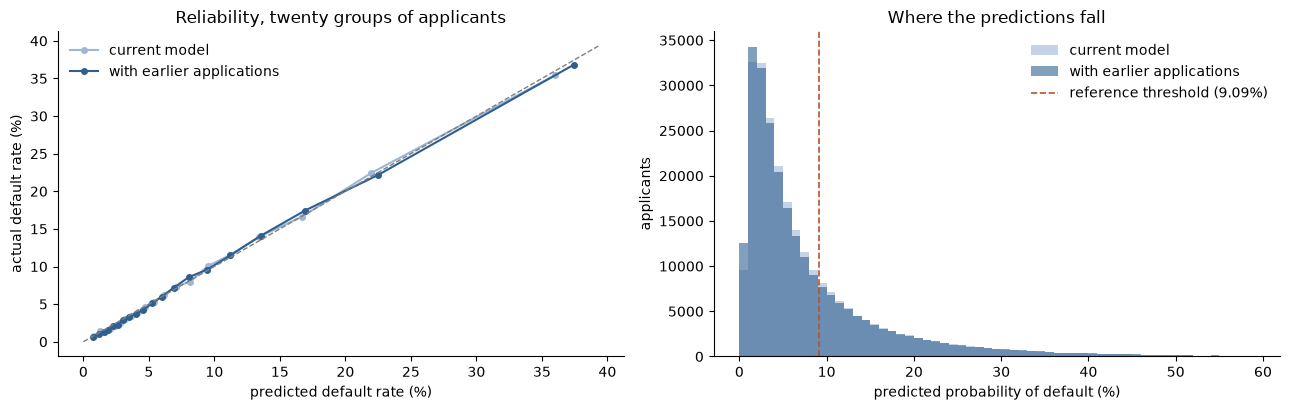

In [26]:
def reliability(p, bins=20):
    order = np.argsort(p)
    groups = np.array_split(order, bins)
    table = pd.DataFrame({'predicted_pct': [p[g].mean() * 100 for g in groups], 'actual_pct': [y_arr[g].mean() * 100 for g in groups], 'applicants': [len(g) for g in groups]})
    table['gap'] = table['predicted_pct'] - table['actual_pct']
    return table

def calibration_error(p, bins=20):
    t = reliability(p, bins)
    return float((t['gap'].abs() * t['applicants']).sum() / t['applicants'].sum()), float(t['gap'].abs().max())

report = {}
for label, p in {'current model': p_old, 'with earlier applications': p_new, 'with earlier applications, before calibration': final_run['oof']}.items():
    error, worst = calibration_error(p)
    report[label] = {'mean_prediction_pct': p.mean() * 100, 'actual_pct': y_arr.mean() * 100, 'calibration_error_pts': error, 'largest_gap_in_any_twentieth_pts': worst}
print(pd.DataFrame(report).T.to_string(float_format=lambda v: f'{v:.3f}'))

tenths = pd.DataFrame({'current: predicted': reliability(p_old, 10)['predicted_pct'], 'current: actual': reliability(p_old, 10)['actual_pct'],
                       'new: predicted': reliability(p_new, 10)['predicted_pct'], 'new: actual': reliability(p_new, 10)['actual_pct']})
tenths.index = [f'tenth {i + 1}' for i in range(10)]
print('\npredicted and actual default rate (%) by tenth of applicants, safest first:')
print(tenths.to_string(float_format=lambda v: f'{v:.2f}'))
print(f"\nthe new model spreads applicants further: safest tenth {tenths.iloc[0, 3]:.2f}% against {tenths.iloc[0, 1]:.2f}%, riskiest tenth {tenths.iloc[-1, 3]:.2f}% against {tenths.iloc[-1, 1]:.2f}%")
print(f"share of all defaults in the riskiest tenth: {tenths.iloc[-1, 1] / tenths['current: actual'].sum():.1%} -> {tenths.iloc[-1, 3] / tenths['new: actual'].sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for label, p, colour in [('current model', p_old, '#9db7d5'), ('with earlier applications', p_new, '#2f5f8f')]:
    t = reliability(p)
    axes[0].plot(t['predicted_pct'], t['actual_pct'], marker='o', markersize=4, label=label, color=colour)
limit = max(reliability(p_new)['predicted_pct'].max(), reliability(p_new)['actual_pct'].max()) * 1.05
axes[0].plot([0, limit], [0, limit], color='grey', linestyle='--', linewidth=1)
axes[0].set_xlabel('predicted default rate (%)'); axes[0].set_ylabel('actual default rate (%)'); axes[0].set_title('Reliability, twenty groups of applicants'); axes[0].legend(frameon=False)
axes[1].hist(p_old * 100, bins=np.arange(0, 60, 1), alpha=0.6, label='current model', color='#9db7d5')
axes[1].hist(p_new * 100, bins=np.arange(0, 60, 1), alpha=0.6, label='with earlier applications', color='#2f5f8f')
axes[1].axvline(THRESHOLD * 100, color='#b5542d', linestyle='--', linewidth=1.2, label=f'reference threshold ({THRESHOLD:.2%})')
axes[1].set_xlabel('predicted probability of default (%)'); axes[1].set_ylabel('applicants'); axes[1].set_title('Where the predictions fall'); axes[1].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

### 7.3 Within groups

A model can be right on average and wrong for particular kinds of applicant. Notebook 04 found the application-only model gave holders of a microloan 13.7% when 19.9% of them default, and the bureau features closed that gap. The same question is asked here of groups that only the earlier applications can define. The groups were chosen from what notebook 05 and stage 4 found to matter, before looking at these gaps.

Some of the groups are defined by features the pruned model no longer uses. Those are a harder test: the model has to be right for them without being told directly who they are.

In [27]:
age = -X_dev['DAYS_BIRTH'].values / 365.25
prev = lambda c: X_dev['PREV_' + c]
remaining = prev('RUNNING_MAX_DAYS_REMAINING')
calibration_groups = {
    'no earlier application': ~has_prev, 'has an earlier application': has_prev,
    'refused at least once': (prev('N_REFUSED') > 0).values, 'last decision was a refusal': (prev('LAST_DECIDED_WAS_REFUSED') == 1).values,
    'refused for the SCOFR reason': (prev('N_REFUSED_SCOFR') > 0).values, 'a loan still running': (prev('N_LOANS_RUNNING') > 0).values,
    'running loan ends within 180 days': (remaining <= 180).values, 'running loan has over 2 years left': (remaining > 730).values,
    'was approved a high-yield loan': (prev('N_APPROVED_HIGH_YIELD') > 0).values, 'costliest fifth of earlier loans': (prev('COST_OF_CREDIT_MEAN') >= prev('COST_OF_CREDIT_MEAN').quantile(0.8)).values,
    'no bureau record': ~has_bureau, 'has a bureau record': has_bureau,
    'men': (X_dev['CODE_GENDER'] == 'M').values, 'women': (X_dev['CODE_GENDER'] == 'F').values,
    'under 30': age < 30, '30 to 45': (age >= 30) & (age < 45), '45 to 60': (age >= 45) & (age < 60), 'over 60': age >= 60,
    'cash loans': (X_dev['NAME_CONTRACT_TYPE'] == 'Cash loans').values, 'revolving loans': (X_dev['NAME_CONTRACT_TYPE'] == 'Revolving loans').values,
}
N_PREV_GROUPS = 10
not_in_model = [c for c in ['N_REFUSED', 'LAST_DECIDED_WAS_REFUSED', 'N_REFUSED_SCOFR', 'N_LOANS_RUNNING', 'RUNNING_MAX_DAYS_REMAINING', 'N_APPROVED_HIGH_YIELD', 'COST_OF_CREDIT_MEAN'] if 'PREV_' + c not in CHOSEN_FEATURES]
print('features used to define groups that the model itself does not use:', not_in_model)
print("the 'costliest fifth' cut point is a description of the development set, used only to define a group for this table\n")

rows = {}
for label, m in calibration_groups.items():
    actual = y_arr[m].mean()
    se = np.sqrt(actual * (1 - actual) / m.sum()) * 100
    rows[label] = {'applicants': int(m.sum()), 'actual_pct': actual * 100, 'current_model_pct': p_old[m].mean() * 100, 'new_model_pct': p_new[m].mean() * 100,
                   'gap_current': (p_old[m].mean() - actual) * 100, 'gap_new': (p_new[m].mean() - actual) * 100, 'standard_error': se}
groups_table = pd.DataFrame(rows).T
groups_table['gap_current_in_se'] = groups_table['gap_current'] / groups_table['standard_error']
groups_table['gap_new_in_se'] = groups_table['gap_new'] / groups_table['standard_error']
print(groups_table.astype({'applicants': int}).to_string(float_format=lambda v: f'{v:,.2f}'))
prev_groups = list(calibration_groups)[:N_PREV_GROUPS]
print(f"\nlargest gap in the {N_PREV_GROUPS} groups defined by earlier applications: {groups_table.loc[prev_groups, 'gap_current'].abs().max():.2f} points with the current model "
      f"({groups_table.loc[prev_groups, 'gap_current'].abs().idxmax()}), {groups_table.loc[prev_groups, 'gap_new'].abs().max():.2f} with the new one ({groups_table.loc[prev_groups, 'gap_new'].abs().idxmax()})")
print(f"groups more than 2 standard errors off: {int((groups_table['gap_current_in_se'].abs() > 2).sum())} with the current model, {int((groups_table['gap_new_in_se'].abs() > 2).sum())} with the new one "
      f"{list(groups_table.index[groups_table['gap_new_in_se'].abs() > 2])}")
print(f"average gap, weighted by group size: {np.average(groups_table['gap_current'].abs(), weights=groups_table['applicants']):.3f} -> {np.average(groups_table['gap_new'].abs(), weights=groups_table['applicants']):.3f} points")

features used to define groups that the model itself does not use: ['N_REFUSED', 'LAST_DECIDED_WAS_REFUSED', 'N_LOANS_RUNNING', 'N_APPROVED_HIGH_YIELD']
the 'costliest fifth' cut point is a description of the development set, used only to define a group for this table



                                    applicants  actual_pct  current_model_pct  new_model_pct  gap_current  gap_new  standard_error  gap_current_in_se  gap_new_in_se
no earlier application                   13174        6.00               6.07           6.02         0.06     0.01            0.21               0.30           0.05
has an earlier application              232834        8.19               8.22           8.25         0.03     0.06            0.06               0.60           0.98
refused at least once                    79161       10.41               9.86          10.43        -0.54     0.02            0.11              -5.01           0.21
last decision was a refusal              40147       12.07              10.98          11.84        -1.09    -0.23            0.16              -6.73          -1.44
refused for the SCOFR reason              5313       19.57              16.89          19.14        -2.68    -0.43            0.54              -4.93          -0.80
a loan sti

### 7.4 The operating point, and what it costs

The reference rule from notebook 02: decline when the predicted probability is 0.0909 or above. The same rule is applied to both models' calibrated probabilities.

Cost is counted in units of one wrongly declined good applicant: each good applicant declined costs 1, and each defaulter approved costs the ratio.

In [28]:
from scipy.stats import ks_2samp

def outcome(p, ratio):
    t = 1 / (1 + ratio)
    declined, bad = p >= t, y_arr == 1
    missed, wrongly = int((~declined & bad).sum()), int((declined & ~bad).sum())
    return {'threshold': t, 'approved_pct': (~declined).mean() * 100, 'defaults_caught_pct': (declined & bad).sum() / bad.sum() * 100,
            'default_rate_among_approved_pct': missed / (~declined).sum() * 100, 'good_applicants_declined_pct': wrongly / (~bad).sum() * 100,
            'cost_per_1000_applicants': (ratio * missed + wrongly) / len(p) * 1000}

rows = {}
for ratio in [5, 10, 20]:
    a, b = outcome(p_old, ratio), outcome(p_new, ratio)
    blanket = min(ratio * y_arr.mean(), 1 - y_arr.mean()) * 1000            # the better of approving everyone and declining everyone
    for label, o in [('current model', a), ('with earlier applications', b)]:
        rows[(f'ratio {ratio}', label)] = {**o, 'saving_against_no_model_pct': (1 - o['cost_per_1000_applicants'] / blanket) * 100}
    rows[(f'ratio {ratio}', 'change')] = {k: b[k] - a[k] for k in a} | {'saving_against_no_model_pct': (a['cost_per_1000_applicants'] - b['cost_per_1000_applicants']) / blanket * 100}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:,.3f}'))

ref_old, ref_new = outcome(p_old, 10), outcome(p_new, 10)
assert abs(ref_old['threshold'] - THRESHOLD) < 1e-4
d_old, d_new, bad = p_old >= THRESHOLD, p_new >= THRESHOLD, y_arr == 1
print(f"\nat the reference threshold of {THRESHOLD:.4f}:")
print(pd.DataFrame({'current model': {'approved, repaid': int((~d_old & ~bad).sum()), 'approved, defaulted': int((~d_old & bad).sum()), 'declined, repaid': int((d_old & ~bad).sum()), 'declined, defaulted': int((d_old & bad).sum())},
                    'with earlier applications': {'approved, repaid': int((~d_new & ~bad).sum()), 'approved, defaulted': int((~d_new & bad).sum()), 'declined, repaid': int((d_new & ~bad).sum()), 'declined, defaulted': int((d_new & bad).sum())}}
                   ).assign(change=lambda t: t['with earlier applications'] - t['current model']).to_string())
print(f"\ncost per 1,000 applicants at a ratio of 10: {ref_old['cost_per_1000_applicants']:.1f} -> {ref_new['cost_per_1000_applicants']:.1f} ({(ref_new['cost_per_1000_applicants'] / ref_old['cost_per_1000_applicants'] - 1):+.1%})")
print(f"applicants whose decision changes: {(d_old != d_new).mean():.1%}; newly declined default at {y_arr[d_new & ~d_old].mean():.1%}, newly approved at {y_arr[~d_new & d_old].mean():.1%}")

ks = lambda p: ks_2samp(p[bad], p[~bad]).statistic
print(f"KS statistic: {ks(p_old):.4f} -> {ks(p_new):.4f}")
by_fold = pd.DataFrame({k: {'current model': (10 * (~d_old & bad)[dev_fold == k].sum() + (d_old & ~bad)[dev_fold == k].sum()) / (dev_fold == k).sum() * 1000,
                            'with earlier applications': (10 * (~d_new & bad)[dev_fold == k].sum() + (d_new & ~bad)[dev_fold == k].sum()) / (dev_fold == k).sum() * 1000} for k in range(N_SPLITS)}).T
by_fold['change'] = by_fold['with earlier applications'] - by_fold['current model']
print('\ncost per 1,000 applicants at a ratio of 10, by fold:')
print(by_fold.round(1).T.to_string())
print(f"lower cost with earlier applications in {int((by_fold['change'] < 0).sum())} of 5 folds")

                                    threshold  approved_pct  defaults_caught_pct  default_rate_among_approved_pct  good_applicants_declined_pct  cost_per_1000_applicants  saving_against_no_model_pct
ratio 5  current model                  0.167        87.596               40.997                            5.438                         9.893                   329.103                       18.467
         with earlier applications      0.167        87.281               42.638                            5.306                        10.091                   324.302                       19.657
         change                         0.000        -0.315                1.641                           -0.132                         0.199                    -4.801                        1.189
ratio 10 current model                  0.091        71.201               66.722                            3.773                        25.469                   502.780                       37.720
     



at the reference threshold of 0.0909:
                     current model  with earlier applications  change
approved, repaid            168550                     169315     765
approved, defaulted           6609                       6421    -188
declined, repaid             57598                      56833    -765
declined, defaulted          13251                      13439     188

cost per 1,000 applicants at a ratio of 10: 502.8 -> 492.0 (-2.1%)
applicants whose decision changes: 7.7%; newly declined default at 10.7%, newly approved at 8.1%


KS statistic: 0.4162 -> 0.4294

cost per 1,000 applicants at a ratio of 10, by fold:
                               0      1      2      3      4
current model              506.4  501.2  503.1  502.9  500.3
with earlier applications  495.2  494.8  488.7  489.9  491.6
change                     -11.2   -6.4  -14.4  -13.0   -8.7
lower cost with earlier applications in 5 of 5 folds


### 7.5 Approval rates by gender, age and kind of history

Notebook 02 found that the application-only model approves men at 0.80 times the rate of women and applicants under 30 at 0.60 times the rate of those over 60. Notebook 04 found the bureau features left those gaps as they were and widened one, between applicants with and without a bureau record. This section measures the same gaps again, and adds applicants with and without an earlier application and those who were refused before. It only measures.

In [29]:
fair_groups = {'gender': {'women': calibration_groups['women'], 'men': calibration_groups['men']},
               'age': {k: calibration_groups[k] for k in ['under 30', '30 to 45', '45 to 60', 'over 60']},
               'bureau record': {'has a bureau record': has_bureau, 'no bureau record': ~has_bureau},
               'earlier application': {'has an earlier application': has_prev, 'no earlier application': ~has_prev},
               'refused before': {'never refused': has_prev & ~calibration_groups['refused at least once'], 'refused at least once': calibration_groups['refused at least once']}}
rows = {}
for segment, members in fair_groups.items():
    old_rates = {g: (~d_old)[m].mean() for g, m in members.items()}
    new_rates = {g: (~d_new)[m].mean() for g, m in members.items()}
    for g, m in members.items():
        rows[(segment, g)] = {'applicants': int(m.sum()), 'default_pct': y_arr[m].mean() * 100, 'approved_current_pct': old_rates[g] * 100, 'approved_new_pct': new_rates[g] * 100,
                              'ratio_to_highest_current': old_rates[g] / max(old_rates.values()), 'ratio_to_highest_new': new_rates[g] / max(new_rates.values()),
                              'defaults_caught_current_pct': (d_old & bad)[m].sum() / bad[m].sum() * 100, 'defaults_caught_new_pct': (d_new & bad)[m].sum() / bad[m].sum() * 100}
fairness = pd.DataFrame(rows).T
print(fairness.astype({'applicants': int}).to_string(float_format=lambda v: f'{v:,.2f}'))
print()
for segment, low in [('gender', 'men'), ('age', 'under 30'), ('bureau record', 'no bureau record'), ('earlier application', 'no earlier application'), ('refused before', 'refused at least once')]:
    print(f"{low} against the highest in '{segment}': {fairness.loc[(segment, low), 'ratio_to_highest_current']:.3f} -> {fairness.loc[(segment, low), 'ratio_to_highest_new']:.3f}")

                                                applicants  default_pct  approved_current_pct  approved_new_pct  ratio_to_highest_current  ratio_to_highest_new  defaults_caught_current_pct  defaults_caught_new_pct
gender              women                           161887         7.00                 76.32             76.29                      1.00                  1.00                        61.05                    62.77
                    men                              84119        10.14                 61.36             62.09                      0.80                  0.81                        74.27                    74.18
age                 under 30                         36281        11.48                 53.59             54.17                      0.62                  0.63                        78.46                    78.25
                    30 to 45                         98993         9.04                 67.17             67.67                      0.77       

### Stage 7 findings

**Calibrated, the model is better on every measure**

| Measure | Current model | With earlier applications | Change | Folds better |
|---|---:|---:|---:|---:|
| ROC AUC | 0.7779 | 0.7856 | +0.0077 | 5 of 5 |
| PR AUC | 0.2654 | 0.2768 | +0.0114 | 5 of 5 |
| Log loss | 0.2403 | 0.2377 | -0.0026 | 5 of 5 |
| Brier score | 0.0667 | 0.0661 | -0.0006 | 5 of 5 |

- Before calibration the model predicts an average of 13.3% against an actual 8.07%, the same inflation as both earlier models and for the same reason. After Platt scaling it predicts 8.13%.
- The distortion is still a plain shift: the correcting line has a slope between 0.97 and 1.01 in every fold. The method chosen in notebook 02 still fits and nothing about it was re-chosen.
- Calibration changes ROC AUC by exactly zero.

**The probabilities are right across the range**
- Predicted and actual rates agree to within 0.61 points in every twentieth of applicants (current model 0.58). The average calibration error is 0.28 points (current model 0.27). The two models are equally well calibrated overall.
- The new model spreads applicants further. Its safest tenth defaults at 0.89% against 1.05%, and its riskiest tenth at 29.5% against 28.9%. The riskiest tenth holds 36.5% of all defaults, up from 35.8%.

**The current model was wrong for whole groups of applicants, and the new one is not**

| Group | Applicants | Actual | Current model | New model |
|---|---:|---:|---:|---:|
| Running loan has over 2 years left | 15,282 | 9.59% | 6.96% | 9.65% |
| Running loan ends within 180 days | 30,944 | 6.75% | 8.23% | 6.89% |
| Costliest fifth of earlier loans | 45,985 | 11.85% | 9.74% | 11.84% |
| Refused for the SCOFR reason | 5,313 | 19.57% | 16.89% | 19.14% |
| Last decision was a refusal | 40,147 | 12.07% | 10.98% | 11.84% |
| Refused at least once | 79,161 | 10.41% | 9.86% | 10.43% |

- This is the clearest picture of what the table adds, as the microloan holders were in notebook 04. The current model is right on average and wrong for particular kinds of applicant. It gives applicants whose earlier loans were the most expensive 9.7% when 11.9% of them default, and it has the remaining term backwards, as stage 4 found.
- Of the 20 groups, seven are more than two standard errors from their actual rate under the current model, some by more than ten. Under the new model **none is**. The largest gap among the groups defined by earlier applications falls from 2.68 points to 0.43, and the average gap across all groups from 0.23 points to 0.07.
- Four of these groups are defined by features the pruned model does not use (number of refusals, whether the last decision was a refusal, number of running loans, number of high-yield loans). The model is right for them all the same, from the related features it kept.
- **Refusals matter here although they added nothing to the ranking.** Stage 4 found the refusal family worth 0.0003 in ROC AUC. Yet the current model under-predicts for refused applicants by 0.5 to 2.7 points. Both are true. Ranking refused applicants a little differently among themselves changes the overall order very little, but knowing their level of risk changes the probability each is given, and the decision at a threshold is taken on the probability. This is a second reason, beside the one in stage 5, for keeping features that the ranking score does not reward.
- A caution on this table: the groups were chosen from what notebook 05 and stage 4 had already shown to matter, and stage 4 had already printed the remaining-term gap. So the gaps under the current model were partly known in advance, and the table shows where it was wrong and not how often a randomly chosen group would be. What is not chosen is the result for the new model: none of 20 groups off.
- For gender, age, loan type and bureau record, where the current model was already right, nothing changed.

**At the reference threshold the model approves more people and catches more defaults**

| | Current model | With earlier applications | Change |
|---|---:|---:|---:|
| Approved | 71.20% | 71.44% | +0.24 |
| Defaults caught | 66.72% | 67.67% | +0.95 |
| Default rate among approved | 3.77% | 3.65% | -0.12 |
| Good applicants declined | 25.47% | 25.13% | -0.34 |
| Cost per 1,000 applicants, ratio 10 | 502.8 | 492.0 | -2.1% |

- In the development set that is 188 more defaults declined and 765 more good applicants approved, at the same threshold. Both kinds of mistake fall together.
- The cost falls in all five folds, by between 6 and 14 per 1,000 applicants. At cost ratios of 5 and 20 it falls by 1.5% and 2.3%.
- 7.7% of applicants get a different decision. Those newly declined default at 10.7% and those newly approved at 8.1%.
- The KS statistic rises from 0.416 to 0.429.
- Since the application-only model of notebook 02, the cost at the reference point has gone from 516.2 to 502.8 to 492.0 per 1,000 applicants, and defaults caught from 65.4% to 66.7% to 67.7%, with slightly more applicants approved each time.

**Approval rates by group**

| Comparison | Current model | With earlier applications |
|---|---:|---:|
| Men against women | 0.80 | 0.81 |
| Under 30 against over 60 | 0.62 | 0.63 |
| No bureau record against a record | 0.81 | 0.83 |
| Refused before against never refused | 0.86 | 0.82 |

- The gender and age gaps are essentially unchanged, as they were in notebook 04. The policy question notebook 02 left open is still open.
- The gap that notebook 04 widened narrows a little. Applicants with no bureau record are approved at 0.83 times the rate of those with one, up from 0.81. Most of them have a history with Home Credit, and the model can now use it.
- One gap widens, and it is the one this table creates. Applicants who were refused before are approved at 0.82 times the rate of those who never were, down from 0.86. They default at 10.4% against 7.0%, so a gap is expected, and the model now catches 75.5% of their defaults against 72.6%. But a lender should see what this is: its own earlier refusal now counts against the applicant. If the earlier refusal was itself made by a model or a rule, some of what is learned here is the old rule's judgement and not the applicant's behaviour. That is a question about the data that this project cannot answer, and it goes to the conclusions.
- Defaults caught rise in most groups. They fall slightly for men (74.3% to 74.2%), for applicants under 30 (78.5% to 78.3%) and for those never refused (62.7% to 62.2%), groups in which the model now approves more people.

**Leakage check for this stage**
- The calibrator is fitted inside the training folds, on predictions the model made for rows it had not seen.
- The calibration method and the threshold were taken from notebook 02 unchanged. Nothing was chosen in this stage.
- The cut point for "costliest fifth" was taken from the development set to define a group in a table. No model saw it.
- All figures are out-of-fold on the frozen folds. The holdout was not used.

**Decisions**
- The model carried forward is the 85-feature model with Platt scaling, and the reference threshold stays at 0.0909.
- For the conclusions: the lender's own earlier refusals as an input, and the wider approval gap that follows.

## Stage 8: Explainability

What does the model now say about an applicant, and can it be said to them?

Notebook 04 ended its explanation with a partial success. The bureau features took some ground from the external scores, whose inputs are unknown, but a low external score was still the main reason for 63% of declines. The earlier applications are a different kind of information. They are Home Credit's own records, so every fact in them is one the lender can state and the applicant can check: what you were charged before, what you still owe us, when we refused you.

Two things are worth knowing in advance from the earlier stages. The features that carry the gain are about pricing and running loans, not about refusals (stage 4). And the strongest of them, the average annuity of earlier loans and the cost of credit, are less obviously "reasons" than a refusal would be. So this stage also looks at what the leading features actually say.

**Method**, as in notebooks 02 and 04. Both models are fitted on the whole development set with calibration. For a sample of 20,000 applicants, each prediction is split into one contribution per feature (SHAP values, computed exactly by LightGBM), expressed in the same calibrated log-odds as the probability. A contribution above zero pushes the applicant's risk up. A family's contribution is the sum over its features.

| Section | What it does |
|---|---|
| 8.1 | Fit both models and check the contributions add up |
| 8.2 | What each model relies on, by family and by feature |
| 8.3 | What the leading new features say |
| 8.4 | Reasons for a decline, before and after |
| 8.5 | Two applicants whose decision changed |
| 8.6 | Do the explanations hold for applicants the model has not seen? |

An explanation describes what a model does. It is not a measure of accuracy, so explaining rows the model was trained on does not inflate any score. Section 8.6 still checks that the picture is the same for unseen applicants.

### 8.1 Fit and check

In [30]:
import hashlib, joblib, lightgbm, sklearn

MODEL_DIR = CACHE_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def fitted(tag, build):
    # a fitted pipeline, saved to disk so that a later run does not have to fit it again
    path = MODEL_DIR / f'{tag}.joblib'
    if path.exists():
        return joblib.load(path), True
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model = build()
    joblib.dump(model, path, compress=3)
    return model, False

def model_tag(prefix, features, params, trees, rows):
    spec = {'features': list(features), 'params': {k: repr(v) for k, v in sorted(params.items())}, 'trees': trees, 'rate': LEARNING_RATE, 'rows': rows, 'seed': SEED,
            'module': hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest(), 'versions': [lightgbm.__version__, sklearn.__version__]}
    return prefix + '_' + hashlib.md5(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:16]

started = time.time()
new_model, c1 = fitted(model_tag('dev_with_previous', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'dev'),
                       lambda: make_pipeline(CHOSEN_FEATURES, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt')).fit(X_dev, y_arr))
old_model, c2 = fitted(model_tag('dev_current', CURRENT, BEST_PARAMS, N_TREES, 'dev'),
                       lambda: make_pipeline(CURRENT, TEXT_FEATURES, CalibratedModel(FINAL(), method='platt')).fit(X_dev, y_arr))
print(f"both models fitted on the development set: {(time.time() - started) / 60:.1f} minutes ({int(c1) + int(c2)} of 2 loaded from disk)")

def explain_sample(model, X_raw):
    # contributions in calibrated log-odds, one column per feature, plus the starting point
    prepared = model.named_steps['preprocess'].transform(X_raw)
    calibrated_step = model.named_steps['model']
    a, b = float(calibrated_step.calibrator_.coef_[0, 0]), float(calibrated_step.calibrator_.intercept_[0])
    out = calibrated_step.model_.booster_.predict(prepared, pred_contrib=True)
    return pd.DataFrame(a * out[:, :-1], columns=list(prepared.columns), index=X_raw.index), float(a * out[0, -1] + b), (a, b)

sample_rows = np.sort(np.random.default_rng(SEED).choice(len(X_dev), size=20_000, replace=False))       # the same sample as notebooks 02 and 04
X_sample, y_sample = X_dev.iloc[sample_rows], y_arr[sample_rows]
started = time.time()
shap_new, base_new, line_new = explain_sample(new_model, X_sample)
shap_old, base_old, line_old = explain_sample(old_model, X_sample)
print(f"contributions for {len(X_sample):,} applicants under both models in {time.time() - started:.0f} seconds")

sigmoid = lambda z: 1 / (1 + np.exp(-z))
p_fit_new, p_fit_old = new_model.predict_proba(X_sample)[:, 1], old_model.predict_proba(X_sample)[:, 1]
checks = {
    'with earlier applications: contributions and starting point rebuild the probability': float(np.abs(sigmoid(shap_new.sum(axis=1).values + base_new) - p_fit_new).max()),
    'current model: the same': float(np.abs(sigmoid(shap_old.sum(axis=1).values + base_old) - p_fit_old).max()),
}
for name, gap in checks.items():
    print(f"largest difference, {name}: {gap:.1e}")
assert max(checks.values()) < 1e-9
print(f"\nstarting point: current model {sigmoid(base_old):.2%}, with earlier applications {sigmoid(base_new):.2%}")
print(f"calibration line: current model {line_old[0]:.4f} x log-odds {line_old[1]:+.4f}; with earlier applications {line_new[0]:.4f} x log-odds {line_new[1]:+.4f}")
print(f"average predicted probability in the sample: {p_fit_old.mean():.2%} and {p_fit_new.mean():.2%}; actual default rate in the sample {y_sample.mean():.2%}")
print(f"features explained: {shap_old.shape[1]} and {shap_new.shape[1]}")
assert list(shap_new.columns) == list(CHOSEN_FEATURES) and list(shap_old.columns) == list(CURRENT)

both models fitted on the development set: 0.0 minutes (2 of 2 loaded from disk)


contributions for 20,000 applicants under both models in 96 seconds


largest difference, with earlier applications: contributions and starting point rebuild the probability: 3.8e-15
largest difference, current model: the same: 4.1e-15

starting point: current model 5.52%, with earlier applications 5.37%
calibration line: current model 0.9924 x log-odds -0.6513; with earlier applications 0.9949 x log-odds -0.6424
average predicted probability in the sample: 8.04% and 8.05%; actual default rate in the sample 7.90%
features explained: 60 and 85


### 8.2 What each model relies on

In [31]:
APP_FAMILIES = {            # the families of notebook 02, stage 12
    'external scores': [c for c in APP_IN_MODEL if c.startswith('EXT_')],
    'loan and amounts': ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'ANNUITY_TO_CREDIT', 'CREDIT_TO_GOODS', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME', 'NAME_CONTRACT_TYPE'],
    'age, gender, education, family': ['DAYS_BIRTH', 'CODE_GENDER', 'EDUCATION_LEVEL', 'NAME_FAMILY_STATUS'],
    'employment': ['DAYS_EMPLOYED', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE'],
    'documents, phone and registration': ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUMENT_3', 'FLAG_WORK_PHONE'],
    'housing, car and region': ['OWN_CAR_AGE', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT_W_CITY', 'REG_CITY_NOT_LIVE_CITY'],
    'social circle and bureau enquiries': ['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_YEAR'],
}
assert sorted(c for members in APP_FAMILIES.values() for c in members) == sorted(APP_IN_MODEL)
OLD_FAMILIES = {**APP_FAMILIES, 'credit bureau': list(BUREAU_IN_MODEL)}
ALL_FAMILIES = {**OLD_FAMILIES, 'earlier applications': list(KEPT_PREV)}
family_of = {c: f for f, members in ALL_FAMILIES.items() for c in members}
NEW = 'earlier applications'

size_old, size_new = shap_old.abs().mean(), shap_new.abs().mean()
by_family = pd.DataFrame({'features': {f: len(m) for f, m in ALL_FAMILIES.items()},
                          'current: share (%)': {f: size_old.reindex(m).sum() / size_old.sum() * 100 for f, m in ALL_FAMILIES.items()},
                          'new: share (%)': {f: size_new.reindex(m).sum() / size_new.sum() * 100 for f, m in ALL_FAMILIES.items()},
                          'current: size': {f: size_old.reindex(m).sum() for f, m in ALL_FAMILIES.items()},
                          'new: size': {f: size_new.reindex(m).sum() for f, m in ALL_FAMILIES.items()}}).fillna(0)
by_family['change in size (%)'] = (by_family['new: size'] / by_family['current: size'].where(by_family['current: size'] > 0) - 1) * 100
print("share of each model's total contribution, by family ('size' is the summed average contribution of the family's features, in log-odds):")
print(by_family.sort_values('new: share (%)', ascending=False).to_string(float_format=lambda v: f'{v:.2f}'))

sub = pd.Series({c: FAMILY[c] for c in KEPT_PREV})
sub_table = pd.DataFrame({'features': sub.value_counts(), 'share of the model (%)': size_new[KEPT_PREV].groupby(sub).sum() / size_new.sum() * 100,
                          'share of the new family (%)': size_new[KEPT_PREV].groupby(sub).sum() / size_new[KEPT_PREV].sum() * 100}).sort_values('share of the model (%)', ascending=False)
print('\ninside the earlier-applications family:')
print(sub_table.to_string(float_format=lambda v: f'{v:.2f}'))

top = pd.DataFrame({'family': pd.Series(family_of), 'new model': size_new, 'current model': size_old}).sort_values('new model', ascending=False)
top['rank'] = np.arange(1, len(top) + 1)
top['rank before'] = top['current model'].rank(ascending=False)
top['change (%)'] = (top['new model'] / top['current model'] - 1) * 100
print('\nthe twenty features the new model relies on most (average size of contribution):')
print(top.head(20).to_string(float_format=lambda v: f'{v:.3f}'))
first_new = top.index[top['family'] == NEW][0]
print(f"\nearlier-application features in the top 10: {int((top.head(10)['family'] == NEW).sum())}; in the top 20: {int((top.head(20)['family'] == NEW).sum())}; highest-ranked: {first_new} at {int(top.loc[first_new, 'rank'])}")
print(f"credit bureau features in the top 20: {int((top.head(20)['family'] == 'credit bureau').sum())}")

gave_way = top.dropna(subset=['current model']).sort_values('change (%)')
print('\nthe ten features of the current model that give way most (among its 30 largest):')
print(gave_way[gave_way['rank before'] <= 30].head(10)[['family', 'current model', 'new model', 'change (%)']].to_string(float_format=lambda v: f'{v:.3f}'))
new_sum = shap_new[KEPT_PREV].sum(axis=1)
print(f"\ncorrelation between the two models' total log-odds: {(shap_new.sum(axis=1)).corr(shap_old.sum(axis=1)):.3f}")
print('correlation, across applicants, between what the earlier applications contribute now and what each family contributed before:')
print(pd.Series({f: new_sum.corr(shap_old[m].sum(axis=1)) for f, m in OLD_FAMILIES.items()}).sort_values(ascending=False).round(3).to_string())

share of each model's total contribution, by family ('size' is the summed average contribution of the family's features, in log-odds):
                                    features  current: share (%)  new: share (%)  current: size  new: size  change in size (%)
earlier applications                      25                0.00           21.59           0.00       0.76                 NaN
external scores                            8               24.50           20.03           0.73       0.70               -3.95
credit bureau                             24               23.31           17.33           0.69       0.61              -12.65
loan and amounts                           8               18.00           13.97           0.54       0.49               -8.81
age, gender, education, family             4               11.04            9.33           0.33       0.33               -0.75
employment                                 3                7.76            6.41           0.23       0

external scores                       0.191
loan and amounts                      0.161
housing, car and region               0.129
credit bureau                         0.127
documents, phone and registration     0.088
social circle and bureau enquiries    0.071
employment                            0.067
age, gender, education, family        0.054


### 8.3 What the leading new features say

A large contribution is not yet a reason anyone can state. For the six new features the model relies on most, this section shows which way each pushes: the average contribution among applicants in each fifth of the feature's values, and among those for whom it is missing. A value above zero raises the predicted risk.

The fifths are cut on the sample being explained. They describe it and nothing is fitted to them.

In [32]:
leading_new = [c for c in top.index if family_of[c] == NEW][:6]
rows = {}
for c in leading_new:
    values, contribution = X_sample[c], shap_new[c]
    has = values.notna()
    fifth = pd.qcut(values[has].rank(method='first'), 5, labels=['lowest fifth', 'second', 'middle', 'fourth', 'highest fifth'])
    by_fifth = contribution[has].groupby(fifth, observed=True).mean()
    edges = values[has].quantile([0.2, 0.8])
    rows[c.replace('PREV_', '')] = {**by_fifth.to_dict(), 'missing': contribution[~has].mean() if (~has).any() else np.nan, 'missing_pct': (~has).mean() * 100,
                                   'value at the 20th percentile': edges.iloc[0], 'value at the 80th percentile': edges.iloc[1],
                                   'rank correlation of value and contribution': values[has].corr(contribution[has], method='spearman')}
direction = pd.DataFrame(rows).T
print('average contribution in log-odds (above zero raises risk):')
print(direction.to_string(float_format=lambda v: f'{v:,.3f}'))
print('\nthe same as odds multipliers, lowest and highest fifth:')
print(np.exp(direction[['lowest fifth', 'highest fifth', 'missing']]).to_string(float_format=lambda v: f'{v:.2f}'))

# actual default rates in the same fifths, from the labels of the sample: does the direction the model learned match what happened?
actual = {}
for c in leading_new:
    values = X_sample[c]
    has = values.notna().values
    fifth = pd.qcut(values[has].rank(method='first'), 5, labels=False).values
    actual[c.replace('PREV_', '')] = {'lowest fifth': y_sample[has][fifth == 0].mean() * 100, 'highest fifth': y_sample[has][fifth == 4].mean() * 100,
                                      'missing': y_sample[~has].mean() * 100 if (~has).any() else np.nan}
print('\nactual default rate (%) in the lowest and highest fifth:')
print(pd.DataFrame(actual).T.to_string(float_format=lambda v: f'{v:.2f}'))

average contribution in log-odds (above zero raises risk):
                            lowest fifth  second  middle  fourth  highest fifth  missing  missing_pct  value at the 20th percentile  value at the 80th percentile  rank correlation of value and contribution
AMT_ANNUITY_MEAN                   0.132   0.084  -0.004  -0.061         -0.159    0.020        5.550                     6,800.234                    19,300.919                                      -0.969
RUNNING_MAX_DAYS_REMAINING        -0.280  -0.208  -0.066   0.076          0.314    0.015       64.820                        95.000                       653.000                                       0.962
COST_OF_CREDIT_MEAN               -0.069  -0.063  -0.040  -0.003          0.178   -0.042        6.330                         1.153                         1.413                                       0.909
DAYS_SINCE_LAST_REFUSAL            0.147   0.126   0.096   0.057          0.030   -0.045       68.050                

### 8.4 Reasons for a decline

For each declined applicant, the main reason is the family whose features together push the risk up the most. Notebook 04 found the external scores were the main reason for 63% of declines under the current model, and the credit bureau for 12%.

In [33]:
def family_push(shap, families):
    return pd.DataFrame({f: shap[[c for c in members if c in shap.columns]].sum(axis=1) for f, members in families.items() if any(c in shap.columns for c in members)})

push_old, push_new = family_push(shap_old, OLD_FAMILIES), family_push(shap_new, ALL_FAMILIES)
declined_old, declined_new = p_fit_old >= THRESHOLD, p_fit_new >= THRESHOLD
print(f"declined in the sample: {declined_old.mean():.1%} by the current model, {declined_new.mean():.1%} by the model with earlier applications")

reasons = pd.DataFrame({'current: main reason (%)': push_old[declined_old].idxmax(axis=1).value_counts(normalize=True) * 100,
                        'new: main reason (%)': push_new[declined_new].idxmax(axis=1).value_counts(normalize=True) * 100,
                        'new: among the top two (%)': pd.Series({f: (push_new[declined_new].rank(axis=1, ascending=False)[f] <= 2).mean() * 100 for f in push_new.columns}),
                        'new: average odds multiplier among declined': np.exp(push_new[declined_new].mean())}).fillna(0).sort_values('new: main reason (%)', ascending=False)
print(reasons.to_string(float_format=lambda v: f'{v:.2f}'))

main_old, main_new = push_old[declined_old].idxmax(axis=1), push_new[declined_new].idxmax(axis=1)
print(f"\ndeclines whose main reason is an external score: {(main_old == 'external scores').mean():.1%} -> {(main_new == 'external scores').mean():.1%}")
print(f"declines whose main reason is the credit bureau family: {(main_old == 'credit bureau').mean():.1%} -> {(main_new == 'credit bureau').mean():.1%}")
print(f"declines whose main reason is the earlier applications: {(main_new == NEW).mean():.1%}; where they are among the top two: {reasons.loc[NEW, 'new: among the top two (%)']:.1f}%")
history = ['credit bureau', NEW]
print(f"declines whose main reason is a recorded credit history of either kind: {main_old.isin(history).mean():.1%} -> {main_new.isin(history).mean():.1%}")
others_outweigh = lambda push, declined: (push[declined].drop(columns='external scores').clip(lower=0).sum(axis=1) > push.loc[declined, 'external scores']).mean()
print(f"declines where the families other than the external scores, added together, push the risk up by more than the external scores do: {others_outweigh(push_old, declined_old):.1%} -> {others_outweigh(push_new, declined_new):.1%}")

# which single features are most often the largest earlier-application reason for a decline
new_declined = shap_new.loc[declined_new, KEPT_PREV]
leading = pd.DataFrame({'group': pd.Series({c: FAMILY[c] for c in KEPT_PREV}), 'largest reason in the family (%)': new_declined.idxmax(axis=1).value_counts(normalize=True) * 100,
                        'pushes risk up for (% of declined)': (new_declined > 0.05).mean() * 100,
                        'average odds multiplier when it does': np.exp(new_declined.where(new_declined > 0.05).mean())}).fillna({'largest reason in the family (%)': 0}).sort_values('largest reason in the family (%)', ascending=False)
leading.index = [c.replace('PREV_', '') for c in leading.index]
print('\namong declined applicants, the earlier-application feature that pushes risk up the most:')
print(leading.head(12).to_string(float_format=lambda v: f'{v:.2f}'))
by_group = leading.groupby('group')['largest reason in the family (%)'].sum().sort_values(ascending=False)
print('\nthe same, added up by kind of fact (%):')
print(by_group.round(1).to_string())
print(f"\ndeclined applicants for whom the earlier applications as a whole lower the risk: {(push_new.loc[declined_new, NEW] < 0).mean():.1%}; "
      f"approved applicants for whom they raise it: {(push_new.loc[~declined_new, NEW] > 0).mean():.1%}")

# the five rare-event features kept by rule 2 of stage 5: what they do for the applicants they concern
rare_rows = {}
for c in [r if r.startswith('PREV_') else 'PREV_' + r for r in RARE_EVENTS]:
    if c in shap_new.columns:
        event = (X_sample[c] > 0).values
        rare_rows[c.replace('PREV_', '')] = {'applicants with the event in the sample': int(event.sum()), 'average odds multiplier for them': float(np.exp(shap_new.loc[event, c].mean())),
                                             'average odds multiplier for the rest': float(np.exp(shap_new.loc[~event, c].mean())), 'share of the model (%)': size_new[c] / size_new.sum() * 100}
print('\nthe rare-event features kept in stage 5:')
print(pd.DataFrame(rare_rows).T.astype({'applicants with the event in the sample': int}).to_string(float_format=lambda v: f'{v:.3f}'))

declined in the sample: 28.1% by the current model, 28.2% by the model with earlier applications
                                    current: main reason (%)  new: main reason (%)  new: among the top two (%)  new: average odds multiplier among declined
external scores                                        63.12                 59.31                       72.45                                         1.82
earlier applications                                    0.00                 14.75                       33.31                                         1.20
loan and amounts                                       17.43                 12.70                       31.95                                         1.17
credit bureau                                          11.71                  7.92                       29.73                                         1.17
age, gender, education, family                          3.02                  2.57                       11.39             


declined applicants for whom the earlier applications as a whole lower the risk: 29.7%; approved applicants for whom they raise it: 34.5%

the rare-event features kept in stage 5:
                     applicants with the event in the sample  average odds multiplier for them  average odds multiplier for the rest  share of the model (%)
N_REFUSED_LIMIT                                         1838                             1.063                                 0.994                   0.339
N_REFUSED_SCOFR                                          410                             1.037                                 0.999                   0.050
N_REFUSED_OTHER                                          365                             0.999                                 1.000                   0.007
N_CHANNEL_AP_CASH                                       1381                             1.106                                 0.992                   0.418
N_REFUSED_REVOLVING               

### 8.5 Two applicants whose decision changed

One applicant the current model would approve and the new model declines, and one the other way round. For each, the six largest contributions under the new model are shown, with the value of the feature.

In [34]:
def show(position, top_n=6):
    row, contributions = X_sample.iloc[position], shap_new.iloc[position]
    order = contributions.abs().sort_values(ascending=False).index[:top_n]
    def readable(c):
        v = row[c]
        if isinstance(v, str) or pd.isna(v):
            return 'missing' if not isinstance(v, str) else v
        if c.startswith('DAYS_'):
            return f'{-v / 365.25:.1f} years'
        if 'DAYS' in c:
            return f'{v:,.0f} days'
        return f'{v:,.3f}' if abs(v) < 10 else f'{v:,.0f}'
    table = pd.DataFrame({'family': [family_of[c] for c in order], 'value': [readable(c) for c in order], 'contribution': contributions[order].values,
                          'odds_multiplier': np.exp(contributions[order].values)}, index=[c.replace('BUREAU_', 'bureau: ').replace('PREV_', 'earlier: ') for c in order])
    table['direction'] = np.where(table['contribution'] > 0, 'raises risk', 'lowers risk')
    rest = contributions.drop(order).sum()
    print(f"  current model: {p_fit_old[position]:.2%}   with earlier applications: {p_fit_new[position]:.2%}   (threshold {THRESHOLD:.2%}; in fact {'defaulted' if y_sample[position] == 1 else 'repaid'})")
    print(f"  family totals: external scores x{np.exp(push_new['external scores'].iloc[position]):.2f}, credit bureau x{np.exp(push_new['credit bureau'].iloc[position]):.2f}, "
          f"earlier applications x{np.exp(push_new[NEW].iloc[position]):.2f}, everything else x{np.exp(push_new.drop(columns=['external scores', 'credit bureau', NEW]).iloc[position].sum()):.2f}")
    print(table.to_string(float_format=lambda v: f'{v:.3f}'))
    print(f"  all other features together: x{np.exp(rest):.2f}\n")

newly_declined = np.where(declined_new & ~declined_old)[0]
newly_approved = np.where(~declined_new & declined_old)[0]
print(f"in the sample: {len(newly_declined):,} newly declined, {len(newly_approved):,} newly approved")
pick_declined = newly_declined[np.argsort(-push_new[NEW].values[newly_declined])[len(newly_declined) // 10]]       # a clear case, not the most extreme one
pick_approved = newly_approved[np.argsort(push_new[NEW].values[newly_approved])[len(newly_approved) // 10]]
print(f"\nNEWLY DECLINED (applicant {X_sample.index[pick_declined]}):")
show(pick_declined)
print(f"NEWLY APPROVED (applicant {X_sample.index[pick_approved]}):")
show(pick_approved)
print(f"among the newly declined, the earlier applications raise risk for {(push_new[NEW].values[newly_declined] > 0).mean():.1%}; among the newly approved, they lower risk for {(push_new[NEW].values[newly_approved] < 0).mean():.1%}")
print(f"in the sample the newly declined defaulted at {y_sample[newly_declined].mean():.1%} and the newly approved at {y_sample[newly_approved].mean():.1%} "
      '(these applicants were in the training data of both models, so the out-of-fold figures of stage 7 are the ones to rely on)')

in the sample: 742 newly declined, 722 newly approved

NEWLY DECLINED (applicant 401322):
  current model: 7.71%   with earlier applications: 14.43%   (threshold 9.09%; in fact repaid)
  family totals: external scores x1.23, credit bureau x1.20, earlier applications x2.36, everything else x0.86
                                                             family       value  contribution  odds_multiplier    direction
earlier: RUNNING_MAX_DAYS_REMAINING            earlier applications  1,116 days         0.347            1.415  raises risk
earlier: RUNNING_ANNUITY_SUM                   earlier applications      91,634         0.210            1.234  raises risk
earlier: COST_OF_CREDIT_MEAN                   earlier applications       1.475         0.180            1.197  raises risk
earlier: COST_OF_CREDIT_LAST                   earlier applications       2.501         0.166            1.180  raises risk
bureau: LIVE_DEBT_MAX                                 credit bureau     686,238     

### 8.6 Do the explanations hold for unseen applicants?

The sample above comes from rows the model was trained on. A second model is fitted without fold 0, and both models explain the applicants in the sample who are in fold 0, whom the second model has never seen. If the two explanations agree, the picture does not depend on the applicant having been in the training data.

In [35]:
in_fold0 = dev_fold[sample_rows] == 0
keep0 = dev_fold != 0
unseen_model, was_loaded = fitted(model_tag('without_fold0', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'dev without fold 0'),
                                  lambda: make_pipeline(CHOSEN_FEATURES, TEXT_FEATURES, MODEL()).fit(X_dev[keep0], y_arr[keep0]))
prepared = unseen_model.named_steps['preprocess'].transform(X_sample[in_fold0])
raw_unseen = pd.DataFrame(unseen_model.named_steps['model'].booster_.predict(prepared, pred_contrib=True)[:, :-1], columns=list(prepared.columns), index=prepared.index)
raw_seen = shap_new[in_fold0] / line_new[0]                                   # the final model, before the calibration rescaling, same applicants

fam = lambda s: family_push(s, ALL_FAMILIES)
share = lambda s, members: float(s[members].abs().mean().sum() / s.abs().mean().sum() * 100)
ext = APP_FAMILIES['external scores']
row_corr = np.array([np.corrcoef(raw_unseen.values[i], raw_seen.values[i])[0, 1] for i in range(len(raw_seen))])
agreement = pd.Series({
    'applicants compared (in fold 0, unseen by the second model)': int(in_fold0.sum()),
    'rank agreement on overall feature importance (Spearman)': raw_unseen.abs().mean().corr(raw_seen.abs().mean(), method='spearman'),
    'median correlation between the two explanations of one applicant': float(np.median(row_corr)),
    'same main risk-raising family (%)': float((fam(raw_unseen).values.argmax(axis=1) == fam(raw_seen).values.argmax(axis=1)).mean() * 100),
    'share from the earlier applications: model that saw the rows (%)': share(raw_seen, KEPT_PREV),
    'share from the earlier applications: model that did not (%)': share(raw_unseen, KEPT_PREV),
    'share from the credit bureau: model that saw the rows (%)': share(raw_seen, BUREAU_IN_MODEL),
    'share from the credit bureau: model that did not (%)': share(raw_unseen, BUREAU_IN_MODEL),
    'share from the external scores: model that saw the rows (%)': share(raw_seen, ext),
    'share from the external scores: model that did not (%)': share(raw_unseen, ext),
})
print(agreement.round(3).to_string())

applicants compared (in fold 0, unseen by the second model)         4187.000
rank agreement on overall feature importance (Spearman)                0.984
median correlation between the two explanations of one applicant       0.978
same main risk-raising family (%)                                     88.512
share from the earlier applications: model that saw the rows (%)      21.586
share from the earlier applications: model that did not (%)           21.552
share from the credit bureau: model that saw the rows (%)             17.283
share from the credit bureau: model that did not (%)                  17.870
share from the external scores: model that saw the rows (%)           20.049
share from the external scores: model that did not (%)                19.707


### Stage 8 findings

**The earlier applications are now the largest family in the model**

| Family | Features | Current model | With earlier applications |
|---|---:|---:|---:|
| Earlier applications | 25 | | 21.6% |
| External scores | 8 | 24.5% | 20.0% |
| Credit bureau | 24 | 23.3% | 17.3% |
| Loan and amounts | 8 | 18.0% | 14.0% |
| Age, gender, education, family | 4 | 11.0% | 9.3% |
| Employment | 3 | 7.8% | 6.4% |
| Housing, car and region | 5 | 6.8% | 5.2% |
| Documents, phone and registration | 5 | 6.4% | 4.4% |
| Social circle and bureau enquiries | 3 | 2.3% | 1.8% |

- For the first time the external scores are not the largest family. The earlier applications carry 21.6% of the model's total contribution.
- As with the bureau in notebook 04, most of this is added on top. In absolute size the external scores shrink by 4%. The families that give way most are the credit bureau (down 13%) and documents, phone and registration (down 20%).
- The bureau gives way because the two tables partly describe the same thing. The feature that falls most is the longest remaining term on a live bureau loan (down 22%), which is the bureau's version of the new remaining-term feature. A Home Credit loan can appear in both tables.
- `ANNUITY_TO_CREDIT` falls by 22%. It describes how the new loan is priced, and the pricing of earlier loans now shares that work.
- Inside the new family, pricing and terms hold 48%, loan state 24%, refusals 10%, timing 8%, product and channel 8%. This is the third measurement of the same thing (stages 4 and 5 were the others) and all three agree.

**Three features are among the leaders**
- `PREV_AMT_ANNUITY_MEAN` is 10th of 85, `PREV_RUNNING_MAX_DAYS_REMAINING` 14th, `PREV_COST_OF_CREDIT_MEAN` 17th, and `PREV_DAYS_SINCE_LAST_REFUSAL` 20th. No bureau feature is in the top 20; in notebook 04 the first was 18th.
- This is the difference from the bureau table. There, 24 modest contributions added up. Here a few features are strong alone, which stage 5 already saw in the ranking and stage 6 in the tree count.
- The new family's contribution is nearly unrelated to what any family contributed before: the highest correlation is 0.19, with the external scores. It is saying something the model did not know.

**What the leading features say**

| Feature | Lowest fifth | Highest fifth | Reading |
|---|---:|---:|---|
| Average annuity of earlier loans | x1.14 | x0.85 | Applicants whose earlier loans were small are riskier |
| Longest remaining term on a running loan | x0.76 | x1.37 | A loan with years still to run raises risk; one nearly repaid lowers it |
| Average cost of credit on earlier loans | x0.93 | x1.20 | Applicants who were charged the most are riskier |
| Days since the last refusal | x1.16 | x1.03 | A recent refusal raises risk, and an old one hardly at all |
| Number of loans ended | x1.08 | x0.93 | Loans seen through to the end lower risk |
| Annuity owed on running loans | x1.00 | x1.14 | Larger existing payments raise risk |

- For five of the six, the direction the model learned matches the default rates of the same applicants. Those in the highest fifth by cost of credit default at 12.6% against 6.8% in the lowest.
- **For one it does not, and the difference is instructive.** Applicants with the largest running annuities default less (6.9% against 9.1%), yet the model treats a larger running annuity as raising risk. Both can be true. Applicants with large running payments tend to be those with higher incomes and larger loans, whom the model already rates as safe through other features. Given everything else it knows, more existing debt is worse. A contribution is what a feature adds given the rest of the model, not what it means alone, and a reason given to an applicant has to be worded that way.
- The cost of credit deserves a note on what it is. It is the price Home Credit set on earlier loans, and a lender prices by its own view of risk. So part of what the model learns here is Home Credit's earlier judgement of the applicant. That makes it informative. It also makes it circular in the same way as the refusals discussed in stage 7.
- The average annuity is a fact about the applicant's past loans that correlates with their means. "Your earlier loans were small" is true and sayable, but it is not something an applicant can act on, and it is the weakest of the six as a reason.

**Reasons for a decline**

| Main reason | Current model | With earlier applications |
|---|---:|---:|
| External scores | 63.1% | 59.3% |
| Earlier applications | | 14.8% |
| Loan and amounts | 17.4% | 12.7% |
| Credit bureau | 11.7% | 7.9% |
| Everything else | 7.7% | 5.3% |

- The share of declines whose main reason is an opaque external score falls again, from 63% to 59%. In notebook 02 it was 71%. It is still the main reason for most declines.
- A recorded credit history of either kind, bureau or Home Credit's own, is the main reason for 22.7% of declines, up from 11.7%. The earlier applications are among the top two reasons for a third of declined applicants.
- The declines where everything other than the external scores, added together, outweighs them rise from 64% to 71%. In notebook 02 this was 48%.
- Among declined applicants, the earlier-application fact that pushes risk up the most is a pricing fact for 54%, the state of a loan for 24%, and a refusal for 17%.
- The family lowers the risk for 30% of declined applicants and raises it for 35% of approved ones. It is not only a source of bad news.

**The rare-event features do what stage 5 kept them for, modestly**
- For the applicants concerned, a partner-channel cash application multiplies the odds by 1.11, a refusal for exceeding a limit by 1.06, the SCOFR refusal by 1.04 and a refusal in a revolving application by 1.03. For everyone else each is neutral.
- `N_REFUSED_OTHER` does nothing at all (x1.00 for both groups, 0.007% of the model). It was kept in stage 5 only because the rule treated the five as one group. It is harmless and could be dropped without loss.
- The SCOFR multiplier of 1.04 is small beside a default rate of 19.6% for that group. Stage 7 showed the model is nonetheless right for them (19.1% predicted). Most of what marks them out reaches the model through other features, mainly the time since the last refusal.

**Two applicants**
- One, at 7.7% under the current model, is now declined at 14.4%. The earlier applications multiply their odds by 2.4: a running loan with 1,116 days left, 91,634 in annuities on running loans, and earlier loans priced well above average. They repaid.
- The other falls from 12.0% to 8.4% and is now approved. Their external scores still count against them. The earlier applications multiply the odds by 0.58, spread over many small contributions, none of which is among the six largest. They repaid.
- The first case is a reminder of what a decline is. The model gave that applicant a 14% chance of default, which is an 86% chance of repaying, and they repaid. These two were picked as clear examples of the mechanism and are not evidence. The evidence is in stage 7: out of fold, the newly declined default at 10.7% and the newly approved at 8.1%.
- Among all newly declined applicants in the sample the earlier applications raise risk for 97%, and among the newly approved they lower it for 89%. The decisions change because of the new features.

**The explanations hold for unseen applicants**
- A model fitted without fold 0 explains the 4,187 fold-0 applicants in the sample almost identically: rank agreement on feature importance 0.984, median correlation between the two explanations of one applicant 0.978, the same main family for 88.5%.
- The new family's share is 21.6% under both models.

**Checks**
- For both models the contributions and the starting point rebuild the reported probability to within 5e-15.
- The current model refitted here has the calibration line 0.9924 and -0.6513, the same as notebook 04's, and gives the same reasons for a decline that notebook 04 reported (63.1% external scores, 11.7% bureau).

**Limits**
- Contributions describe what the model does, not what causes default. The running-annuity case above shows how far apart the two can be.
- The external scores remain the largest single reason for a decline, and remain unexplained.
- Two of the new reasons, the price of earlier loans and earlier refusals, are the lender's own past decisions about the applicant. They predict well and should be described to an applicant as what they are.
- Family totals depend on how features are grouped.

**Decisions**
- Nothing about the model changes.
- A reason given to an applicant can now name facts from their history with Home Credit. The useful ones are the remaining term and size of running loans, loans seen through to the end, and a recent refusal.

## Stage 9: Outputs

Refit the model on all of the training data, save it, and write the Kaggle submission files.

Every choice is fixed: the 85 features (stage 5), the settings and 3,500 trees (stage 6), Platt scaling and the threshold (stage 7). This stage changes none of them.

**About the holdout.** As in notebooks 02 and 04, the model that produces the submission is fitted on all 307,511 training applicants, holdout included, because more data gives a better model and the test file has no labels to score it on anyway. The holdout applicants are used as training rows only. Nothing is scored on them, here or anywhere in this notebook. The holdout's one remaining use, a final check of the model that includes every history table, is untouched: that model will be fitted on the development set alone and scored on the holdout once.

So the model saved here has not been scored on any labelled data it did not see, and cannot be. Its evidence is the cross-validated result of the same recipe on the development set, and the Kaggle score.

**Why two submissions.** Stage 4 kept `PREV_RUNNING_MAX_DAYS_REMAINING`, the longest remaining term on a running loan, although notebook 05 found that its values differ between train and test. Cross-validation cannot say whether that was right, because every fold comes from train. So, as notebook 02 did for `ANNUITY_TO_CREDIT` and notebook 04 for the microloan features, a second model is fitted without it and submitted as a diagnostic. It is not a candidate: choosing between the two on the Kaggle score would be tuning on the test set.

| Section | What it does |
|---|---|
| 9.1 | Refit on all training applicants |
| 9.2 | Check the refitted model against the one fitted on the development set |
| 9.3 | Save it, and confirm a separate process can load and use it |
| 9.4 | The diagnostic model, and expectations fixed before any score is seen |
| 9.5 | Write and check the submission files |
| 9.6 | Kaggle scores |

### 9.1 Refit on all training applicants

In [36]:
import subprocess, tempfile

def load_joined(which):
    app = pd.read_parquet(f'{PROCESSED}/application_{which}_features.parquet')
    app['REGION_RATING_CLIENT_W_CITY'] = app['REGION_RATING_CLIENT_W_CITY'].astype(float)
    bur = pd.read_parquet(f'{PROCESSED}/bureau_{which}_features.parquet')
    prv = pd.read_parquet(f'{PROCESSED}/previous_{which}_features.parquet')
    assert app.index.equals(bur.index) and app.index.equals(prv.index)
    return app.join(bur, how='left').join(prv, how='left')

train_all = load_joined('train')
X_all, y_all = train_all.drop(columns='TARGET'), train_all['TARGET'].values
X_test = load_joined('test')
del train_all

refit_checks = {
    'all 307,511 training applicants, 24,825 defaults': len(X_all) == 307511 and int(y_all.sum()) == 24825,
    'exactly the applicants of the frozen split': set(X_all.index) == set(split.index),
    'the development rows are unchanged': X_all.loc[X_dev.index, CHOSEN_FEATURES].equals(X_dev[CHOSEN_FEATURES]),
    'test: 48,744 applicants, none in train': len(X_test) == 48744 and len(X_test.index.intersection(X_all.index)) == 0,
    'test has every feature the model needs, with the same types': all(str(X_test[c].dtype) == str(X_all[c].dtype) for c in CHOSEN_FEATURES),
    'the test table has no outcome column': 'TARGET' not in X_test.columns,
    'the test file of earlier-application features is the one notebook 05 saved (checksum)': sha(f'{PROCESSED}/previous_test_features.parquet') == previous_meta['tables']['test']['sha256'],
}
for name, ok in refit_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(refit_checks.values())

def final_recipe(features):
    return make_pipeline(features, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt'))

started = time.time()
production, was_loaded = fitted(model_tag('all_train_with_previous', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'all train'), lambda: final_recipe(CHOSEN_FEATURES).fit(X_all, y_all))
print(f"\nrefitted on all training applicants: {'loaded from disk' if was_loaded else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
prod_step, dev_step = production.named_steps['model'], new_model.named_steps['model']
PROD_A, PROD_B = float(prod_step.calibrator_.coef_[0, 0]), float(prod_step.calibrator_.intercept_[0])
prod_features = list(production.named_steps['preprocess'].named_steps['keep'].columns_)
assert prod_features == CHOSEN_FEATURES and prod_step.model_.n_estimators_ == FINAL_TREES
print(pd.DataFrame({'fitted on the development set': {'training applicants': f'{len(X_dev):,}', 'defaults': f'{int(y_arr.sum()):,}', 'features': len(CHOSEN_FEATURES), 'trees': f'{dev_step.model_.n_estimators_:,}',
                                                      'calibration slope': f'{line_new[0]:.4f}', 'calibration intercept': f'{line_new[1]:.4f}'},
                    'refitted on all of train': {'training applicants': f'{len(X_all):,}', 'defaults': f'{int(y_all.sum()):,}', 'features': len(prod_features), 'trees': f'{prod_step.model_.n_estimators_:,}',
                                                 'calibration slope': f'{PROD_A:.4f}', 'calibration intercept': f'{PROD_B:.4f}'}}).to_string())
print(f"identical LightGBM settings: {prod_step.model_.get_params() == dev_step.model_.get_params()}")

PASS  all 307,511 training applicants, 24,825 defaults
PASS  exactly the applicants of the frozen split
PASS  the development rows are unchanged
PASS  test: 48,744 applicants, none in train
PASS  test has every feature the model needs, with the same types
PASS  the test table has no outcome column
PASS  the test file of earlier-application features is the one notebook 05 saved (checksum)

refitted on all training applicants: loaded from disk


                      fitted on the development set refitted on all of train
training applicants                         246,008                  307,511
defaults                                     19,860                   24,825
features                                         85                       85
trees                                         3,500                    3,500
calibration slope                            0.9949                   1.0057
calibration intercept                       -0.6424                  -0.6339
identical LightGBM settings: True


### 9.2 Is the refitted model the same model?

It cannot be scored, but it can be compared with the model fitted on the development set, which was. Both are run on the 48,744 test applicants, whom neither has seen.

In [37]:
from scipy.stats import spearmanr

p_test = production.predict_proba(X_test)[:, 1]
p_test_dev = new_model.predict_proba(X_test)[:, 1]
assert np.isfinite(p_test).all() and ((p_test > 0) & (p_test < 1)).all()
moved = np.abs(p_test - p_test_dev)
earlier_submission = pd.read_csv('../artifacts/submissions/submission_with_bureau.csv').set_index('SK_ID_CURR')['TARGET'].reindex(X_test.index).values     # the submission of notebook 04
assert np.isfinite(earlier_submission).all()
test_prev, test_running = (X_test['PREV_N_APPLICATIONS'] > 0).values, X_test['PREV_RUNNING_MAX_DAYS_REMAINING'].notna().values
agreement = pd.Series({
    'test applicants scored': len(p_test),
    'rank correlation, refitted against development-fitted': spearmanr(p_test, p_test_dev)[0],
    'average prediction, development-fitted (%)': p_test_dev.mean() * 100,
    'average prediction, refitted (%)': p_test.mean() * 100,
    'median change in one applicant\'s probability (points)': np.median(moved) * 100,
    'same decision at the reference threshold (%)': ((p_test >= THRESHOLD) == (p_test_dev >= THRESHOLD)).mean() * 100,
    'declined at the reference threshold, refitted (%)': (p_test >= THRESHOLD).mean() * 100,
    'rank correlation with the submission of notebook 04 (with bureau)': spearmanr(p_test, earlier_submission)[0],
    'same decision as the submission of notebook 04 (%)': ((p_test >= THRESHOLD) == (earlier_submission >= THRESHOLD)).mean() * 100,
    'test applicants with an earlier application (%)': test_prev.mean() * 100,
    'test applicants with a running loan that has a planned end (%)': test_running.mean() * 100,
})
print(agreement.round(4).to_string())
dev_running = X_dev['PREV_RUNNING_MAX_DAYS_REMAINING'].notna().values
print(f"\nfor comparison on the development set: default rate {y_arr.mean():.2%}; average cross-validated prediction {p_new.mean():.2%}; declined at the reference threshold {(p_new >= THRESHOLD).mean():.1%}; "
      f"with an earlier application {has_prev.mean():.1%}; with a running loan that has a planned end {dev_running.mean():.1%}")
print(f"rank correlation between the two models' cross-validated predictions on the development set: {spearmanr(p_new, p_old)[0]:.4f}; same decision {((p_new >= THRESHOLD) == (p_old >= THRESHOLD)).mean():.1%}")

test applicants scored                                               48744.0000
rank correlation, refitted against development-fitted                    0.9897
average prediction, development-fitted (%)                               7.8321
average prediction, refitted (%)                                         7.8212
median change in one applicant's probability (points)                    0.4096
same decision at the reference threshold (%)                            96.4180
declined at the reference threshold, refitted (%)                       27.5972
rank correlation with the submission of notebook 04 (with bureau)        0.9510
same decision as the submission of notebook 04 (%)                      92.4483
test applicants with an earlier application (%)                         98.0634
test applicants with a running loan that has a planned end (%)          34.5150

for comparison on the development set: default rate 8.07%; average cross-validated prediction 8.13%; declined at the re

### 9.3 Save the model

The model is saved in the same form as the two before it: LightGBM's own text file for the trees, and a JSON file for everything else. `src/models/scoring.py`, written for the application-only model, loads it without change, because it reads the feature list and the text levels from the file. The only difference for a caller is that the input table must now carry the earlier-application columns as well.

The models in `artifacts/final_model/` and `artifacts/model_with_bureau/` are left as they are.

In [38]:
SAVE_DIR = Path('../artifacts/model_with_previous')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
prod_step.model_.booster_.save_model(str(SAVE_DIR / 'model.txt'))
model_sha = hashlib.sha256((SAVE_DIR / 'model.txt').read_bytes()).hexdigest()
levels = production.named_steps['preprocess'].named_steps['encode'].categories_
like_for_like = compare(final_run, baseline_same)

saved_meta = {
    'name': 'Home Credit default risk, application, credit bureau and previous application tables',
    'predicts': 'probability that the applicant has payment difficulties (TARGET = 1)',
    'files': {'model': 'model.txt', 'model_sha256': model_sha},
    'features': CHOSEN_FEATURES,
    'feature_sources': {'application': list(APP_IN_MODEL), 'credit bureau': list(BUREAU_IN_MODEL), 'previous applications': list(KEPT_PREV)},
    'text_feature_levels': {c: list(levels[c]) for c in CHOSEN_FEATURES if c in TEXT_FEATURES},
    'inputs': {'application features': 'data/processed/application_*_features.parquet (notebook 01)', 'bureau features': 'data/processed/bureau_*_features.parquet (notebook 03, src/features/bureau.py)',
               'previous application features': 'data/processed/previous_*_features.parquet (notebook 05, src/features/previous_application.py)', 'join': 'on SK_ID_CURR'},
    'calibration': {'method': 'Platt scaling', 'slope': PROD_A, 'intercept': PROD_B,
                    'formula': 'probability = sigmoid(slope * log(p / (1 - p)) + intercept), p = LightGBM output clipped to [1e-7, 1 - 1e-7]'},
    'decision': {'rule': 'decline when the probability is at or above the threshold', 'reference_threshold': float(THRESHOLD), 'reference_cost_ratio': recipe['decision']['reference_cost_ratio'],
                 'thresholds_by_cost_ratio': recipe['decision']['thresholds_by_cost_ratio']},
    'training': {'rows': int(len(X_all)), 'defaults': int(y_all.sum()), 'trees': int(FINAL_TREES), 'learning_rate': float(LEARNING_RATE), 'seed': SEED,
                 'lightgbm_settings': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in FINAL_PARAMS.items()}},
    'evidence': {'note': 'Measured on the same recipe by five-fold cross-validation on the development set (80% of train). The saved model was fitted on all of train and has not itself been scored. '
                         'The holdout has not been opened for this model.',
                 'cross_validation': {'roc_auc': float(final_cal['mean']['roc_auc']), 'pr_auc': float(final_cal['mean']['pr_auc']), 'log_loss': float(final_cal['mean']['log_loss'])},
                 'model_with_bureau': {'roc_auc': float(baseline_cal['mean']['roc_auc']), 'pr_auc': float(baseline_cal['mean']['pr_auc']), 'log_loss': float(baseline_cal['mean']['log_loss'])},
                 'gain_from_previous_application_features_like_for_like': float(like_for_like['mean_difference'])},
    'warnings': {**{c: bureau_meta['features'][c]['warning'] for c in BUREAU_IN_MODEL if 'warning' in bureau_meta['features'][c]}, **{c: WARNED[c] for c in KEPT_PREV if c in WARNED}},
    'versions': {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__},
}
(SAVE_DIR / 'metadata.json').write_text(json.dumps(saved_meta, indent=2), encoding='utf-8')
for f in sorted(SAVE_DIR.iterdir()):
    print(f"saved {f.as_posix().replace('../', '')}  ({f.stat().st_size / 1024:,.0f} KB)")
print('warnings carried in the file:', list(saved_meta['warnings']))

# 1. the loader written for the application-only model, unchanged, in this process
from scoring import load_model
loaded = load_model(SAVE_DIR)
direct = loaded.predict_proba(X_test)
few = X_test.head(500)
shuffled = few[list(reversed(few.columns))].assign(NOT_A_FEATURE=1.0)
try:
    loaded.predict_proba(few.drop(columns='PREV_COST_OF_CREDIT_MEAN'))
    refused = False
except ValueError as error:
    refused = 'PREV_COST_OF_CREDIT_MEAN' in str(error)

# 2. a separate Python process, from a file
with tempfile.TemporaryDirectory() as tmp:
    table, out_csv = Path(tmp) / 'test_joined.parquet', Path(tmp) / 'scores.csv'
    X_test.to_parquet(table)
    run_outside = subprocess.run([sys.executable, '../src/models/scoring.py', str(SAVE_DIR), str(table), str(out_csv)], capture_output=True, text=True)
    assert run_outside.returncode == 0, run_outside.stderr[-2000:]
    outside = pd.read_csv(out_csv).set_index('SK_ID_CURR')['TARGET']

bureau_model_meta = json.loads(Path('../artifacts/model_with_bureau/metadata.json').read_text(encoding='utf-8'))
app_model_meta = json.loads(Path('../artifacts/final_model/metadata.json').read_text(encoding='utf-8'))
file_sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
save_checks = {
    'loaded in this process: equal to the pipeline to 1e-9': float(np.abs(direct - p_test).max()) < 1e-9,
    'a separate process gives the same predictions': outside.index.equals(X_test.index) and float(np.abs(outside.values - p_test).max()) < 1e-9,
    f'it uses its {len(CHOSEN_FEATURES)} features and ignores the other {X_test.shape[1] - len(CHOSEN_FEATURES)} columns': len(loaded.features) == len(CHOSEN_FEATURES) == 85,
    'column order and extra columns do not matter': np.array_equal(loaded.predict_proba(shuffled), direct[:500]),
    'a missing earlier-application column is refused with a clear message': refused,
    'decisions use the reference threshold': np.array_equal(loaded.decide(X_test), p_test >= THRESHOLD),
    'the model with bureau features in artifacts/model_with_bureau is untouched': file_sha('../artifacts/model_with_bureau/model.txt') == bureau_model_meta['files']['model_sha256'],
    'the application-only model in artifacts/final_model is untouched': file_sha('../artifacts/final_model/model.txt') == app_model_meta['files']['model_sha256'],
}
print(f"\nseparate process: {run_outside.stdout.strip()}; largest difference from the notebook pipeline {float(np.abs(outside.values - p_test).max()):.1e}")
for name, ok in save_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(save_checks.values())

saved artifacts/model_with_previous/metadata.json  (12 KB)
saved artifacts/model_with_previous/model.txt  (4,369 KB)
warnings carried in the file: ['BUREAU_LIVE_MAX_DAYS_REMAINING', 'BUREAU_DAYS_SINCE_LAST_OPENED', 'BUREAU_DAYS_SINCE_LAST_UPDATE', 'BUREAU_DAYS_SINCE_FIRST_OPENED', 'BUREAU_N_MICROLOANS', 'BUREAU_N_LIVE_MICROLOANS', 'PREV_RUNNING_MAX_DAYS_REMAINING', 'PREV_COST_OF_CREDIT_LAST', 'PREV_DAYS_SINCE_FIRST_DECISION']



separate process: 48744 rows scored; largest difference from the notebook pipeline 1.0e-16
PASS  loaded in this process: equal to the pipeline to 1e-9
PASS  a separate process gives the same predictions
PASS  it uses its 85 features and ignores the other 51 columns
PASS  column order and extra columns do not matter
PASS  a missing earlier-application column is refused with a clear message
PASS  decisions use the reference threshold
PASS  the model with bureau features in artifacts/model_with_bureau is untouched
PASS  the application-only model in artifacts/final_model is untouched


### 9.4 The diagnostic model, and what is expected

The second model is the same recipe without `PREV_RUNNING_MAX_DAYS_REMAINING`. Cross-validation gives what removing it costs when train and test are alike. Kaggle will show what it costs on the test file, where its values are distributed differently.

Stage 4 measured this on the full list of 101 features. Here it is measured again on the 85 actually used.

The expectations below are printed before any file is uploaded.

In [39]:
DIAGNOSTIC_DROP = 'PREV_RUNNING_MAX_DAYS_REMAINING'
NO_TERM = [c for c in CHOSEN_FEATURES if c != DIAGNOSTIC_DROP]
assert len(NO_TERM) == len(CHOSEN_FEATURES) - 1

started = time.time()
cv_no_term = run(NO_TERM, model=MODEL())
term_cost = compare(final_run, cv_no_term)
print(f"without the feature, cross-validated: {'loaded from cache' if cv_no_term['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
print(pd.DataFrame({f'with the feature ({len(CHOSEN_FEATURES)})': final_run['folds']['roc_auc'], f'without ({len(NO_TERM)})': cv_no_term['folds']['roc_auc']}).T.to_string(float_format=lambda v: f'{v:.5f}'))
CV_MAIN, CV_NO_TERM, CV_TERM_COST = float(final_run['mean']['roc_auc']), float(cv_no_term['mean']['roc_auc']), float(term_cost['mean_difference'])
print(f"cross-validated ROC AUC: {CV_MAIN:.5f} with, {CV_NO_TERM:.5f} without; the feature is worth {CV_TERM_COST:+.5f} "
      f"(standard error {term_cost['standard_error']:.5f}, better in {term_cost['folds_better']} of 5 folds)")

started = time.time()
production_no_term, was_loaded = fitted(model_tag('all_train_no_remaining_term', NO_TERM, FINAL_PARAMS, FINAL_TREES, 'all train'), lambda: final_recipe(NO_TERM).fit(X_all, y_all))
print(f"\ndiagnostic model refitted on all training applicants: {'loaded from disk' if was_loaded else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_test_no_term = production_no_term.predict_proba(X_test)[:, 1]

# how the feature differs between the two files, and what it does to the test predictions
bands = [-np.inf, 90, 180, 365, 730, np.inf]
labels = ['up to 90 days', '91 to 180', '181 to 365', '1 to 2 years', 'over 2 years']
dev_band = pd.cut(X_dev[DIAGNOSTIC_DROP], bands, labels=labels)
test_band = pd.cut(X_test[DIAGNOSTIC_DROP], bands, labels=labels)
shift = pd.DataFrame({'development (% of applicants)': dev_band.value_counts(normalize=False).reindex(labels) / len(X_dev) * 100,
                      'test (% of applicants)': test_band.value_counts(normalize=False).reindex(labels) / len(X_test) * 100,
                      'development: actual default rate (%)': pd.Series(y_arr, index=X_dev.index).groupby(dev_band, observed=True).mean().reindex(labels) * 100,
                      'test: average prediction with the feature (%)': pd.Series(p_test, index=X_test.index).groupby(test_band, observed=True).mean().reindex(labels) * 100,
                      'test: average prediction without it (%)': pd.Series(p_test_no_term, index=X_test.index).groupby(test_band, observed=True).mean().reindex(labels) * 100})
shift.loc['no running loan with a planned end'] = [(~dev_running).mean() * 100, (~test_running).mean() * 100, y_arr[~dev_running].mean() * 100, p_test[~test_running].mean() * 100, p_test_no_term[~test_running].mean() * 100]
print()
print(shift.to_string(float_format=lambda v: f'{v:.2f}'))

# Written down before any submission is scored. The current model's scores are from notebook 04, stage 9.
WITH_BUREAU = {'cv': float(baseline['mean']['roc_auc']), 'public': 0.77412, 'private': 0.77529}
CV_GAIN = CV_MAIN - WITH_BUREAU['cv']
CARRY_FLOOR = round(CV_MAIN - 0.010, 4)
GAIN_FLOOR = round(WITH_BUREAU['private'] + CV_GAIN / 2, 4)
print('\nexpectations, fixed before submitting:')
print(f"  1. The score carries over. Cross-validation {CV_MAIN:.4f}. The model with bureau features scored {WITH_BUREAU['private'] - WITH_BUREAU['cv']:+.4f} against its cross-validation on the private test set.")
print(f"     The validation score is said to carry over if the private score is {CARRY_FLOOR:.4f} or higher (within 0.010 of cross-validation).")
print(f"  2. The gain carries over. In cross-validation the earlier applications add {CV_GAIN:+.4f} to the model with bureau features, which scored {WITH_BUREAU['private']:.5f} on the private test set.")
print(f"     The gain is said to carry over if the private score is {GAIN_FLOOR:.4f} or higher (at least half of the cross-validated gain).")
print(f"  3. The remaining term. In cross-validation the feature is worth {CV_TERM_COST:+.4f}.")
print(f"     If the model without it scores the same or higher on the private test set, the feature does not hold up on the test file, and the warning in notebook 05 was right to be made.")
print(f"     If the main model leads, it does hold up. A difference under {NOISE_FLOOR:.4f} either way is read as no evidence.")

without the feature, cross-validated: loaded from cache
fold                        0       1       2       3       4
with the feature (85) 0.78518 0.78217 0.78659 0.78721 0.78710
without (84)          0.78397 0.78167 0.78515 0.78593 0.78604
cross-validated ROC AUC: 0.78565 with, 0.78455 without; the feature is worth +0.00109 (standard error 0.00016, better in 5 of 5 folds)

diagnostic model refitted on all training applicants: loaded from disk



                                    development (% of applicants)  test (% of applicants)  development: actual default rate (%)  test: average prediction with the feature (%)  test: average prediction without it (%)
PREV_RUNNING_MAX_DAYS_REMAINING                                                                                                                                                                                        
up to 90 days                                                6.53                    8.38                                  6.78                                           6.39                                     7.70
91 to 180                                                    6.05                    6.75                                  6.72                                           6.89                                     7.97
181 to 365                                                   9.32                    9.40                                  7.81        

### 9.5 Submission files

In [40]:
SUBMISSION_DIR = Path('../artifacts/submissions')
existing = {f.name: file_sha(f) for f in SUBMISSION_DIR.iterdir() if not f.name.startswith('submission_with_previous')}
sample_submission = pd.read_csv(f'{RAW}/sample_submission.csv')
submissions = {'submission_with_previous.csv': p_test, 'submission_with_previous_without_remaining_term.csv': p_test_no_term}
rows = {}
for filename, predictions in submissions.items():
    frame = pd.DataFrame({'SK_ID_CURR': X_test.index.values, 'TARGET': predictions}).set_index('SK_ID_CURR').loc[sample_submission['SK_ID_CURR']].reset_index()
    frame.to_csv(SUBMISSION_DIR / filename, index=False)
    back = pd.read_csv(SUBMISSION_DIR / filename)
    file_checks = {
        'columns': list(back.columns) == list(sample_submission.columns) == ['SK_ID_CURR', 'TARGET'],
        'rows': len(back) == len(sample_submission) == 48744,
        'ids and order': (back['SK_ID_CURR'].values == sample_submission['SK_ID_CURR'].values).all() and back['SK_ID_CURR'].is_unique,
        'no train id': len(set(back['SK_ID_CURR']) & set(X_all.index)) == 0,
        'probabilities': back['TARGET'].notna().all() and ((back['TARGET'] > 0) & (back['TARGET'] < 1)).all(),
        'survives the round trip': np.allclose(back['TARGET'].values, frame['TARGET'].values, rtol=0, atol=1e-12),
    }
    assert all(file_checks.values()), {k: v for k, v in file_checks.items() if not v}
    rows[filename] = {'rows': len(back), 'checks_passed': f"{sum(file_checks.values())} of {len(file_checks)}", 'mean_pct': back['TARGET'].mean() * 100, 'median_pct': back['TARGET'].median() * 100,
                      'max_pct': back['TARGET'].max() * 100, 'declined_at_reference_threshold_pct': (back['TARGET'] >= THRESHOLD).mean() * 100, 'sha256_first_12': file_sha(SUBMISSION_DIR / filename)[:12]}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nrank correlation between the two submissions: {spearmanr(p_test, p_test_no_term)[0]:.4f}; same decision at the reference threshold: {((p_test >= THRESHOLD) == (p_test_no_term >= THRESHOLD)).mean():.1%}")
untouched = all(file_sha(SUBMISSION_DIR / name) == digest for name, digest in existing.items())
print(f"the {len(existing)} earlier submission files are untouched: {untouched}  {sorted(existing)}")
assert untouched and len(existing) == 4

# the full training table is not needed again
del X_all, y_all
assert not any(name in globals() for name in ['X_all', 'y_all'])
print('holdout: used as training rows for the two refits only. Nothing was scored on it.')

                                                      rows checks_passed mean_pct median_pct max_pct declined_at_reference_threshold_pct sha256_first_12
submission_with_previous.csv                         48744        6 of 6    7.821      4.671  79.518                              27.597    09ab9afa1216
submission_with_previous_without_remaining_term.csv  48744        6 of 6    7.904      4.763  79.932                              28.071    e1eb0a5bab3a

rank correlation between the two submissions: 0.9876; same decision at the reference threshold: 96.5%
the 4 earlier submission files are untouched: True  ['submission_final_model.csv', 'submission_with_bureau.csv', 'submission_with_bureau_without_microloans.csv', 'submission_without_annuity_to_credit.csv']
holdout: used as training rows for the two refits only. Nothing was scored on it.


### 9.6 Kaggle scores

The two files in `artifacts/submissions/` have to be uploaded by hand on the competition's "Late Submission" page:

- `submission_with_previous.csv`
- `submission_with_previous_without_remaining_term.csv`

The scores below were read from that page on 12 October 2026 and typed in by hand. The files uploaded are the ones written in 9.5, which a second run reproduced byte for byte.

In [41]:
KAGGLE_SCORES = {
    'submission_with_previous.csv': {'public': 0.78015, 'private': 0.78421},
    'submission_with_previous_without_remaining_term.csv': {'public': 0.78006, 'private': 0.78231},
}

KAGGLE_ENTERED = all(v is not None for scores in KAGGLE_SCORES.values() for v in scores.values())
if not KAGGLE_ENTERED:
    print('Not submitted yet. No test-set score exists for the model with earlier applications, and the three expectations in 9.4 are untested.')
else:
    main, second = KAGGLE_SCORES['submission_with_previous.csv'], KAGGLE_SCORES['submission_with_previous_without_remaining_term.csv']
    print(pd.DataFrame({'cross-validation': {'application only': 0.76852, 'with bureau': WITH_BUREAU['cv'], 'with earlier applications': CV_MAIN, 'the same, without the remaining term': CV_NO_TERM},
                        'public': {'application only': 0.76743, 'with bureau': WITH_BUREAU['public'], 'with earlier applications': main['public'], 'the same, without the remaining term': second['public']},
                        'private': {'application only': 0.76382, 'with bureau': WITH_BUREAU['private'], 'with earlier applications': main['private'], 'the same, without the remaining term': second['private']}}
                       ).to_string(float_format=lambda v: f'{v:.5f}'))
    print(f"\n1. private score {main['private']:.5f} against the floor of {CARRY_FLOOR:.4f}: {'the validation score carries over' if main['private'] >= CARRY_FLOOR else 'the validation score does NOT carry over'} "
          f"(private minus cross-validation {main['private'] - CV_MAIN:+.5f}; for the model with bureau features it was {WITH_BUREAU['private'] - WITH_BUREAU['cv']:+.5f})")
    gain = main['private'] - WITH_BUREAU['private']
    print(f"2. gain over the model with bureau features on the private test set: {gain:+.5f} (in cross-validation {CV_GAIN:+.5f}); floor {GAIN_FLOOR:.4f}: "
          f"{'the gain carries over' if main['private'] >= GAIN_FLOOR else 'the gain does NOT carry over in full'} ({gain / CV_GAIN:.0%} of the cross-validated gain)")
    lead = main['private'] - second['private']
    reading = 'no evidence either way' if abs(lead) < NOISE_FLOOR else ('the remaining-term feature holds up on the test file' if lead > 0 else 'the remaining-term feature does NOT hold up on the test file')
    print(f"3. the main model leads the model without the remaining term by {lead:+.5f} on the private test set (in cross-validation {CV_TERM_COST:+.5f}): {reading}")

                                      cross-validation  public  private
application only                               0.76852 0.76743  0.76382
with bureau                                    0.77790 0.77412  0.77529
with earlier applications                      0.78565 0.78015  0.78421
the same, without the remaining term           0.78455 0.78006  0.78231

1. private score 0.78421 against the floor of 0.7756: the validation score carries over (private minus cross-validation -0.00144; for the model with bureau features it was -0.00261)
2. gain over the model with bureau features on the private test set: +0.00892 (in cross-validation +0.00775); floor 0.7792: the gain carries over (115% of the cross-validated gain)
3. the main model leads the model without the remaining term by +0.00190 on the private test set (in cross-validation +0.00109): the remaining-term feature holds up on the test file


### Stage 9 findings

**What was produced**

| Output | Location |
|---|---|
| The model with earlier applications, refitted on all 307,511 training applicants | `artifacts/model_with_previous/model.txt` and `metadata.json` |
| Submission of that model | `artifacts/submissions/submission_with_previous.csv` |
| Submission of the diagnostic model without `PREV_RUNNING_MAX_DAYS_REMAINING` | `artifacts/submissions/submission_with_previous_without_remaining_term.csv` |

The two earlier models and the four earlier submission files are untouched, by checksum.

**The refit**
- Same recipe: 85 features, the settings from notebook 02, 3,500 trees, Platt scaling. Only the number of training applicants changed, from 246,008 to 307,511.
- The calibration line moved from a slope of 0.9949 to 1.0057 and an intercept of -0.6424 to -0.6339.
- **This model has not been scored on labelled data it did not see, and cannot be.** Its evidence is the cross-validated 0.7856 for the same recipe on the development set, and the Kaggle score when it is in.
- The holdout applicants were used as training rows for the two refits. Nothing was scored on them.

**Is it the same model?** Against the model fitted on the development set, on the 48,744 test applicants:
- Rank correlation 0.990, average prediction 7.82% and 7.83%, and the same decision for 96.4% of applicants. Notebook 04 saw 0.990 and 96.7% for the same comparison.
- Against the submission of notebook 04, the rank correlation is 0.951 and 7.6% of test applicants get a different decision. On the development set the two models' cross-validated predictions correlate at 0.946 and 7.7% of decisions differ. The new features change the test predictions about as much as they change the development ones.
- 27.6% of test applicants would be declined at the reference threshold, against 28.6% in cross-validation. The average test prediction is 7.8%, a little below the development default rate of 8.1%. Test labels are unknown, so this cannot be checked. One visible difference between the files is that 98.1% of test applicants have an earlier application against 94.6% in development.

**The saved model works outside the notebook**
- `src/models/scoring.py`, written for the application-only model, loads this third model without any change. A separate Python process scored the test table and matched the notebook pipeline to 1e-16.
- All 8 checks pass. A table missing an earlier-application column is refused with a message naming the column.
- The metadata file carries nine warnings forward: six from the bureau features and three from the earlier applications.
- The input must now be the application features joined to the bureau and earlier-application features. The last two are built by code outside the notebooks (`src/features/bureau.py`, `src/features/previous_application.py`). The application half is still inside notebook 01.

**The remaining-term diagnostic**
- On the 85 features actually used, the feature is worth 0.0011 in cross-validation, in 5 of 5 folds, with a standard error of 0.0002. Stage 4 measured 0.0012 on the full list.
- The test file differs in the way notebook 05 reported:

| Longest remaining term | Development | Test | Development default rate | Test prediction with the feature | Without it |
|---|---:|---:|---:|---:|---:|
| Up to 90 days | 6.5% | 8.4% | 6.8% | 6.4% | 7.7% |
| 91 to 180 days | 6.1% | 6.8% | 6.7% | 6.9% | 8.0% |
| 181 to 365 days | 9.3% | 9.4% | 7.8% | 8.2% | 8.5% |
| 1 to 2 years | 6.9% | 5.7% | 8.5% | 8.9% | 8.4% |
| Over 2 years | 6.2% | 4.3% | 9.6% | 10.0% | 8.7% |

- Test applicants more often have a loan about to end and less often one with years to run. The share with any such loan is the same (34.5% against 35.1%). This fits what notebook 05 concluded: the test applications are later in time relative to the records, so running loans are further along.
- With the feature, the model's test predictions in each band follow the development default rates closely. Without it they are flattened towards the average. If the relation between remaining term and default is the same in the test file, the feature should help there. If the shift means the feature measures something different there, it should not. Cross-validation cannot tell these apart, which is the reason for the second file.

**Expectations, written before any score is seen**
1. The validation score carries over if the private score is **0.7756** or higher, within 0.010 of cross-validation. The model with bureau features came in 0.0026 below its own.
2. The gain carries over if the private score is **0.7792** or higher, which is the private score of the model with bureau features plus half of the cross-validated gain.
3. If the diagnostic model scores the same or higher, the remaining-term feature does not hold up on the test file. A difference under 0.0005 either way is read as no evidence.

**Kaggle scores** (late submissions, 12 October 2026)

| Model | Cross-validation | Kaggle public | Kaggle private |
|---|---:|---:|---:|
| Application only (notebook 02) | 0.7685 | 0.7674 | 0.7638 |
| With bureau (notebook 04) | 0.7779 | 0.7741 | 0.7753 |
| With earlier applications | 0.7856 | 0.7802 | 0.7842 |
| With earlier applications, without the remaining term | 0.7846 | 0.7801 | 0.7823 |

1. **The validation score carries over.** The private score is 0.7842, above the floor of 0.7756 and 0.0014 below cross-validation. The model with bureau features came in 0.0026 below its own, and the application-only model 0.0047.
2. **The gain carries over in full.** On the private test set the model beats the model with bureau features by 0.0089. Cross-validation said 0.0077. The floor was 0.7792 and the score is 0.7842.
3. **The remaining-term feature holds up.** The main model leads the model without it by 0.0019 on the private score, against 0.0011 in cross-validation, and well above the noise floor. The difference between the files that notebook 05 flagged does not stop the feature working on the test file. The warning was still right to make: the question could not be answered from the training data, and it has now been answered by a test fixed in advance.
4. On the public score the lead is 0.0001, which alone would have been read as no evidence. The public score uses about a fifth of the test rows. The same thing happened with the microloan features in notebook 04.
5. The gain on the public score is 0.0060, smaller than on the private score and smaller than in cross-validation. It is still above half of the cross-validated gain. The expectations were set on the private score, and I report the public one because it is the less favourable of the two.

The diagnostic model was not, and is not, a candidate. The result supports the decision taken in stage 4 on other grounds. It did not make it.

**Leakage check for this stage**
- Nothing was chosen. Every setting was fixed in stages 5 to 7.
- The test file was only passed through finished models.
- The holdout was not scored.
- The diagnostic model is not a candidate. The main model stays whatever the Kaggle scores say.

## Stage 10: Conclusions

What the previous-application table was worth, its limits, and what comes next.

Nothing is fitted in this stage. The cell below gathers the results of earlier stages into one table, so that every figure in the conclusions can be traced to the cell that produced it.

cross-validated on the development set, the same five folds throughout:
                                                               stage  features  trees  roc_auc  pr_auc  gain_over_current_model  folds_better     step
Current model, with bureau (notebook 04)                           2        60   3500  0.77790 0.26542                  0.00000             0         
Add all 41 earlier-application features, nothing else changed      3       101   3500  0.78584 0.27653                  0.00794             5  0.00794
Prune to 20 by the ranking                                         5        80   3500  0.78570 0.27632                  0.00780             5 -0.00013
Add back 5 rare-event features                                     5        85   3500  0.78565 0.27684                  0.00775             5 -0.00005
Settings checked, unchanged                                        6        85   3500  0.78565 0.27684                  0.00775             5  0.00000

after calibration:
  

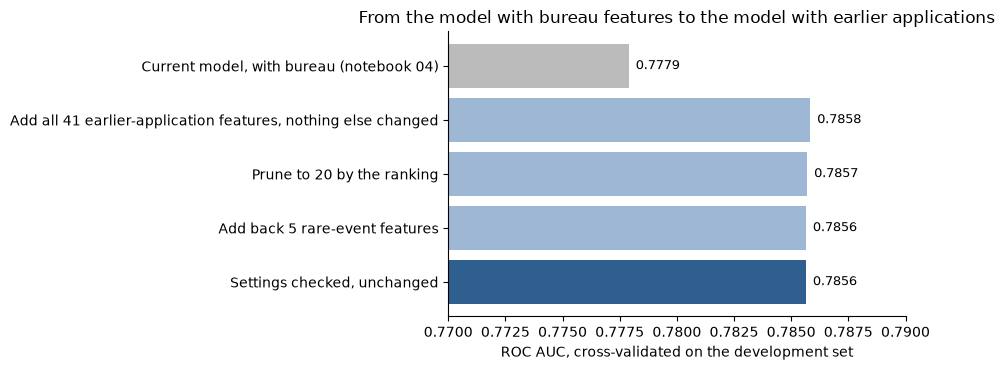

In [42]:
steps = [
    ('Current model, with bureau (notebook 04)', len(CURRENT), N_TREES, baseline, 2),
    ('Add all 41 earlier-application features, nothing else changed', len(WITH_NEW), N_TREES, with_new, 3),
    ('Prune to 20 by the ranking', len(CURRENT) + len(RULE_PREV), N_TREES, pruned_rule, 5),
    ('Add back 5 rare-event features', len(CHOSEN_FEATURES), N_TREES, chosen, 5),
    ('Settings checked, unchanged', len(CHOSEN_FEATURES), FINAL_TREES, final_run, 6),
]
ladder = pd.DataFrame({label: {'stage': stage, 'features': n, 'trees': trees, 'roc_auc': r['mean']['roc_auc'], 'pr_auc': r['mean']['pr_auc'],
                               'gain_over_current_model': compare(r, baseline)['mean_difference'], 'folds_better': compare(r, baseline)['folds_better'] if r is not baseline else 0}
                       for label, n, trees, r, stage in steps}).T
ladder['step'] = ladder['roc_auc'].astype(float).diff()
print('cross-validated on the development set, the same five folds throughout:')
print(ladder.astype({'stage': int, 'features': int, 'trees': int, 'folds_better': int}).to_string(float_format=lambda v: f'{v:.5f}', na_rep=''))

calibrated_summary = pd.DataFrame({'current model': baseline_cal['mean'], 'with earlier applications': final_cal['mean']}).loc[['roc_auc', 'pr_auc', 'log_loss', 'brier']]
calibrated_summary['change'] = calibrated_summary['with earlier applications'] - calibrated_summary['current model']
print('\nafter calibration:')
print(calibrated_summary.to_string(float_format=lambda v: f'{v:.5f}'))
first = verdict(with_new)
print(f"\nwhen the features were first added (stage 3): gain {first['mean_difference']:+.5f}, {first['ratio_to_standard_error']:.0f} times its standard error, {first['mean_difference'] / NOISE_FLOOR:.0f} times the seed noise floor of {NOISE_FLOOR:.4f}")
print(f"95% interval for that gain from resampling applicants: {np.quantile(boot_gain, 0.025):+.4f} to {np.quantile(boot_gain, 0.975):+.4f}")
print(f"gain of the final model, both models on the same settings: {like_for_like['mean_difference']:+.5f}")
print(f"cost per 1,000 applicants at the reference threshold: {ref_old['cost_per_1000_applicants']:.1f} -> {ref_new['cost_per_1000_applicants']:.1f}")

main_scores = KAGGLE_SCORES['submission_with_previous.csv']
evidence = pd.DataFrame({
    'application only': {'cross-validation': 0.76852, 'holdout (opened once, notebook 02)': 0.7715, 'Kaggle public': 0.76743, 'Kaggle private': 0.76382},
    'with bureau': {'cross-validation': WITH_BUREAU['cv'], 'holdout (opened once, notebook 02)': np.nan, 'Kaggle public': WITH_BUREAU['public'], 'Kaggle private': WITH_BUREAU['private']},
    'with earlier applications': {'cross-validation': CV_MAIN, 'holdout (opened once, notebook 02)': np.nan,
                                  'Kaggle public': main_scores['public'] if KAGGLE_ENTERED else np.nan, 'Kaggle private': main_scores['private'] if KAGGLE_ENTERED else np.nan},
})
print('\nROC AUC by kind of evidence:')
print(evidence.to_string(float_format=lambda v: f'{v:.4f}', na_rep='not measured'))
print(f"Kaggle scores for the model with earlier applications: {'entered in section 9.6' if KAGGLE_ENTERED else 'NOT YET ENTERED (section 9.6)'}")

# the figures quoted in the conclusions
assert round(float(baseline['mean']['roc_auc']), 4) == 0.7779 and round(CV_MAIN, 4) == 0.7856 and len(CHOSEN_FEATURES) == 85 and len(KEPT_PREV) == 25 and FINAL_TREES == 3500
assert round(float(final_cal['mean']['log_loss']), 4) == 0.2377 and round(like_for_like['mean_difference'], 4) == 0.0077
assert not any(name in globals() for name in ['X_all', 'y_all']), 'the full training table should not be in memory'
assert KAGGLE_ENTERED and round(main_scores['private'], 4) == 0.7842 and round(main_scores['private'] - WITH_BUREAU['private'], 4) == 0.0089

fig, ax = plt.subplots(figsize=(9.5, 3.8))
labels = list(ladder.index)[::-1]
values = ladder['roc_auc'].astype(float)[::-1]
ax.barh(labels, values, color=['#2f5f8f'] + ['#9db7d5'] * (len(labels) - 2) + ['#bbbbbb'])
for i, v in enumerate(values):
    ax.text(v + 0.0003, i, f'{v:.4f}', va='center', fontsize=9)
ax.set_xlim(0.770, 0.790); ax.set_xlabel('ROC AUC, cross-validated on the development set'); ax.set_title('From the model with bureau features to the model with earlier applications')
sns.despine(); plt.tight_layout(); plt.show()

### Conclusions

**The answer.** Yes. Home Credit's own record of the applicant's earlier applications improves the model, by nearly as much as the credit bureau did.

| | Current model (with bureau) | With earlier applications | Change |
|---|---:|---:|---:|
| ROC AUC, cross-validated | 0.7779 | 0.7856 | +0.0077 |
| PR AUC | 0.2654 | 0.2768 | +0.0114 |
| Log loss | 0.2403 | 0.2377 | -0.0026 |
| Defaults caught at the reference threshold | 66.7% | 67.7% | +0.9 points |
| Good applicants declined | 25.5% | 25.1% | -0.3 points |
| Cost per 1,000 applicants, ratio 10 | 503 | 492 | -2.1% |
| Kaggle private score | 0.7753 | 0.7842 | +0.0089 |

- The settings and the number of trees did not change, so the whole 0.0077 comes from the features. No like-for-like adjustment is needed.
- The four conditions fixed in advance were met when the features were first added, with nothing tuned to them: higher on average, higher in every fold, 23 times its standard error and 16 times the noise a change of seed produces. The final model meets them too.
- Across three notebooks, on the same five folds: 0.7685 with the application alone, 0.7779 with the bureau, 0.7856 with the earlier applications.
- **Kaggle confirms it.** On the private test set, a different population whose labels nobody in this project has seen, the gain is 0.0089, a little more than cross-validation predicted. All three expectations written down before the upload were met. On the public score, a fifth of the test rows, the gain is smaller at 0.0060.

**The model**

| | |
|---|---|
| Inputs | 85 features: 36 from the application, 24 from the credit bureau, 25 of the 41 earlier-application features of notebook 05 |
| Settings | Unchanged from notebook 02. The two settings with a reason to move were checked and did not |
| Trees | 3,500 at a learning rate of 0.02, as in notebook 04 |
| Output | A calibrated probability, by the same Platt scaling |
| Decision rule | Unchanged: decline at 0.0909 or above |
| Saved as | `artifacts/model_with_previous/`, loaded by the same `src/models/scoring.py` |

**Where the gain comes from**
- **How earlier loans were priced.** The pricing family gives 62% of the gain alone and costs the most to remove. Applicants who were charged the most default at nearly twice the rate of those charged the least, and the current model under-predicted for them by two points.
- **Loans still running.** The longest remaining term on a running loan is worth 0.0011 alone. The current model had it backwards, predicting more risk for applicants about to finish a loan than for those with years to go.
- **A few strong features, not many weak ones.** Three earlier-application features are among the model's 17 most important, where no bureau feature was. Four of them give 60% of the gain.
- **Applicants the bureau could not help.** Those with no bureau record gain 0.017 within their group, more than twice the average. Most of them have a history with Home Credit.
- **Not** from refusals as a ranking signal (worth 0.0003), although they looked like the clearest signal in notebook 05, and not from knowing how many applications there were (0.0002).
- **But refusals do matter for the probabilities.** The current model under-predicted for refused applicants by 0.5 to 2.7 points. The new one is right for them, and for all 20 groups tested.

**What I got wrong**
- **Refusals.** Notebook 05 called them the clearest signal in the table. Added to a model that already has the external scores and the bureau, they add almost nothing to the ranking. This is notebook 04's lesson from the other side: a feature's relationship with default says little about what it adds.
- **Applicants with no earlier application.** I expected them to lose, as applicants with no bureau record did in notebook 04. They gain 0.005. I offered an explanation in stage 4 and did not test it.
- **The ratios across two tables.** Suggested in notebook 05, tested here, and they changed nothing. The same idea failed for the bureau.
- **A check that stopped the run.** The first version of those ratios divided by a past average that is zero for seven applicants. The check caught it. I had not looked for it.
- **The calibration groups in stage 7** were chosen knowing where the current model was weak, so the count of groups it gets wrong is not a neutral one. The findings say so.
- **The ranking dropped the rare-event features again.** This time a rule was waiting for them, which is the only reason this is not a fourth repetition of the same mistake. One of the five kept turned out to do nothing.

**How leakage was controlled**

| Risk | Control | What was measured |
|---|---|---|
| A difference in code, not in features | Shared module, unchanged since notebook 04 | The baseline reproduced notebook 04's predictions exactly, for all 246,008 applicants |
| A gain from more columns, not more information | New features scrambled between applicants | The scrambled columns made the model worse by 0.0015 |
| A gain from seed noise | Other seeds of the baseline; the gain repeated on two more seeds | Noise floor 0.0005; gain 0.0081 and 0.0082 on the other seeds |
| Features that use the future | Notebook 05 asserts no record is dated on or after the application | |
| Features supplied differently in train and test | Notebook 05's supply test on every column | All pass. One feature differs in distribution and has its own diagnostic submission |
| Feature selection on the scored rows | Selection inside the pipeline, on training folds | Fixing one list flatters the score by 0.00001 |
| Calibration on the scored rows | Nested inside the training folds | |
| The holdout | Never loaded. Its applicants appear only as training rows in the final refit | |
| The test file | No labels. Passed through finished models only | |
| Tuning on the test set | The diagnostic model is not a candidate, whatever its Kaggle score | |

**What is still uncertain**
- **The holdout has not been opened for this model.** Every figure above is cross-validated on the development set. For the two earlier models, cross-validation was confirmed by the holdout and by Kaggle, which is the reason to trust the method. It is not a measurement of this model.
- **Kaggle has now tested it once.** The private score of 0.7842 is 0.0014 below cross-validation, a smaller drop than either earlier model had (0.0026 and 0.0047). That is direct evidence that the cross-validated gain is real and not an artefact of choices made on the development folds. It is one test on one population.
- **Choices made on the development folds add up.** Notebook 05 screened 53 features to 41 using development outcomes for one of its three rules. This notebook chose a list size, a fixed list and five features to add back. Each was done by a rule fixed in advance, and the one effect that could be measured was 0.00001. Stage 6 changed nothing and so adds nothing. The Kaggle result puts a ceiling on the total: had these choices inflated the cross-validated gain much, the gain on the test file would have fallen short of it, and it did not. The holdout, opened once at the end, remains the formal check.
- **No full search of the settings was run.** Three earlier searches found a plateau, and only the two settings with a reason to move were checked. A search could in principle find something those checks cannot.

**Limits**
- **Some of what the model learns is the lender's own earlier judgement.** The price of earlier loans and earlier refusals were decisions Home Credit made about the applicant. They predict well. They also mean that an applicant once judged risky is judged risky again partly because of that judgement. Applicants refused before are now approved at 0.82 times the rate of those never refused, down from 0.86. Whether to use a lender's past decisions as inputs is a policy question, like gender and age.
- **The external scores are still the main reason for 59% of declines,** down from 63%, and 71% in notebook 02. They remain unexplained.
- **A contribution is not a cause.** The model treats a larger running annuity as raising risk although those applicants default less. A reason given to an applicant has to be worded with that in mind.
- **One leading feature is distributed differently in the test file.** Test applicants more often have a loan about to end. The second submission tested whether the feature holds up there, and it does: it is worth 0.0019 on the private test set.
- **The payment records are not used yet.** `installments_payments`, `POS_CASH_balance` and `credit_card_balance` say whether earlier loans were paid on time. Every feature here describes what was applied for and granted, not how it was repaid.
- **One kept feature does nothing** (`PREV_N_REFUSED_OTHER`). It is harmless and was kept by a rule that treated five features as a group.
- **Gender and age.** The gaps found in notebook 02 are unchanged.
- **The model is somewhat slower.** About 72 seconds a fold against 63.

**What to do next**
1. **Add `installments_payments` by the same method.** It is the first table that records behaviour: whether each instalment was paid, when, and how much. `POS_CASH_balance` and `credit_card_balance` follow.
2. **Open the holdout once, at the end,** for the model that includes every table.
3. **Move the application features' code out of notebook 01,** so that the model can score a raw application and its histories without any notebook.